# CS4048: Data Science — Assignment 2: Exploratory Data Analysis
**Student Name:** Muhammad Waqar Saleem  
**Roll Number:** 23L-1021  
**Section:** BCS-7A  

---

### Dataset Publication & Versioning Links
* **Repository Link:** https://github.com/muhammadwaqarsaleem/ds_eda-data_cleaning.git

---

In [1]:
# Cell 1: Standard scientific and data analysis stack (strictly permitted libraries)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm

# Configure visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

# Suppress unnecessary pandas chained assignment warnings
pd.options.mode.chained_assignment = None

print("Libraries imported successfully.")

Libraries imported successfully.


# Part A: Netflix Movies and TV Shows EDA

---

## A1. Dataset Understanding

In [5]:
# Cell 2: Load the Netflix dataset
netflix_path = 'data/netflix_titles.csv' 
df_netflix = pd.read_csv(netflix_path)

# 1. Dataset dimensions
print(f"Dataset Shape: {df_netflix.shape[0]} rows, {df_netflix.shape[1]} columns\n")

# 2. Schema and non-null counts
print("--- Column Information & Data Types ---")
df_netflix.info()

# 3. Sample records
print("\n--- First 5 Records ---")
display(df_netflix.head())

Dataset Shape: 8807 rows, 12 columns

--- Column Information & Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB

--- First 5 Records ---


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


### Observation Definition
A single row represents an individual media title (either a standalone movie or a TV show season package) available in the global Netflix streaming catalogue as of September 2021, detailing its release metadata, production contributors, classification, and availability dates.

---

### Variable Role Table

| Group | Column Name | Technical Data Type | Variable Role Type | Role & Analytical Purpose |
| :--- | :--- | :--- | :--- | :--- |
| **Identifiers** | `show_id` | Object (String) | Identifier | Unique primary key identifying each title in the catalogue. Not used for statistical modeling. |
| **Core Metadata** | `title` | Object (String) | Text / Identifier | Official title of the production. Used for identification and search. |
| | `type` | Object (String) | Categorical (Binary) | Primary media classification (`Movie` vs `TV Show`). Key stratification feature across the entire EDA. |
| | `rating` | Object (String) | Categorical (Ordinal/Nominal) | Age and maturity guidance rating (e.g., `TV-MA`, `PG-13`, `R`). Indicates intended target audience demographics. |
| **Production Details** | `director` | Object (String) | Multi-Valued Categorical / Text | Name(s) of individual(s) who directed the title. High cardinality with multiple comma-separated entries. |
| | `cast` | Object (String) | Multi-Valued Categorical / Text | Core credited cast members. High cardinality, multi-valued string. |
| | `country` | Object (String) | Multi-Valued Categorical | Production country or partner countries for co-productions. Key variable for geographical distribution analysis. |
| | `listed_in` | Object (String) | Multi-Valued Categorical | Genre and sub-genre tags assigned by Netflix (e.g., "Dramas, International Movies"). Needs tokenization for individual genre analysis. |
| **Temporal Data** | `release_year` | Int64 | Numerical (Discrete) / Temporal | Calendar year the movie or TV show originally premiered. Useful for historical catalogue coverage analysis. |
| | `date_added` | Object (String) | Date | Date the title was published to the Netflix streaming library. Needs parsing to `datetime` to extract onboarding cadence. |
| **Metrics** | `duration` | Object (String) | Mixed Numerical / Categorical | Duration metric containing heterogeneous units: runtime in minutes for Movies, season counts for TV Shows. Requires parsing into separate numerical features. |
| **Descriptive Text**| `description` | Object (String) | Unstructured Text | Short synopsis/summary of the title's narrative premise. |

#### Detailed Description of Primary Variables
1. **`type`**: Fundamental binary split separating movies from serialized television content. All downstream metrics (e.g., duration distributions) must be conditioned on this variable.
2. **`duration`**: Encodes duration in incompatible units (`min` vs `Season`/`Seasons`). Must be decomposed into numerical runtime (minutes) for movies and discrete season count for shows during data cleaning.
3. **`date_added` & `release_year`**: The interaction between these two temporal markers allows computing catalogue ingestion lag (i.e., how long after original release Netflix licensed the title).
4. **`country` & `listed_in`**: Both are semi-structured composite strings where multiple distinct entities are joined by commas. They cannot be analyzed using standard categorical frequencies without splitting/exploding individual elements.

---

## A2. Data Quality Assessment

We systematically investigate six primary dimensions of data quality across the Netflix dataset:
1. **Missing values** (volume, pattern, and mechanism).
2. **Duplicate records** (both full-row duplicates and duplicate title/show identifiers).
3. **Data type validity** (identifying stored object types that should be datetime or numerical).
4. **Categorical consistency** (whitespace, casing, and corrupted values in categorical fields).
5. **Suspicious/invalid entries** (e.g., misplaced values shifted across column boundaries).
6. **Outliers and distributional anomalies** across continuous metrics.

In [4]:
# Cell 3: Assessment of Missing Values and Duplicates

# 1. Missing Value Summary
missing_counts = df_netflix.isnull().sum()
missing_pct = (df_netflix.isnull().sum() / len(df_netflix)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage (%)': missing_pct.round(2)
}).loc[lambda df: df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print("--- Missing Values Summary ---")
display(missing_summary)

# 2. Duplicate Check: Full Rows
full_duplicates = df_netflix.duplicated().sum()
print(f"Total Full-Row Duplicates: {full_duplicates}")

# 3. Duplicate Check: Primary Key (`show_id`)
id_duplicates = df_netflix['show_id'].duplicated().sum()
print(f"Total Duplicate `show_id` Entries: {id_duplicates}")

# 4. Duplicate Check: Title + Type + Release Year (semantic duplicates)
semantic_duplicates = df_netflix.duplicated(subset=['title', 'type', 'release_year']).sum()
print(f"Potential Semantic Duplicates (title + type + release_year): {semantic_duplicates}")

# Display semantic duplicate pairs if any exist
if semantic_duplicates > 0:
    dups_df = df_netflix[df_netflix.duplicated(subset=['title', 'type', 'release_year'], keep=False)].sort_values(by='title')
    display(dups_df[['show_id', 'type', 'title', 'release_year', 'country', 'date_added']].head(10))

--- Missing Values Summary ---


,Missing Count,Percentage (%)
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03


Total Full-Row Duplicates: 0
Total Duplicate `show_id` Entries: 0
Potential Semantic Duplicates (title + type + release_year): 0


### Data Quality Findings: Missing Values and Duplication

1. **Duplicate Records:**
   * **Full-row duplicates:** Exactly 0 found. Every row is an independent entry.
   * **Primary Key (`show_id`):** 0 duplicates across all 8,807 rows, confirming `show_id` is a strictly unique primary identifier.
   * **Semantic Duplicates (`title` + `type` + `release_year`):** 0 duplicates found.

2. **Missing Values Analysis:**
   * `director`: 2,634 missing values (29.91%). High missingness is structurally expected (Missing Not At Random) because many TV shows rely on rotating episode directors or showrunners rather than a single credited film director.
   * `country`: 831 missing values (9.44%). Missing production country records require handling to avoid bias in geographic analysis.
   * `cast`: 825 missing values (9.37%), predominantly occurring in documentaries, animated content, or reality programming where ensemble billing differs.
   * `date_added`: 10 missing values (0.11%). Titles added early in Netflix's streaming platform lifecycle without ingestion timestamp metadata.
   * `rating`: 4 missing values (0.05%).
   * `duration`: 3 missing values (0.03%).

In [6]:
# Cell 9: Detailed Investigation of Data Types, Anomalies, and Category Consistency

print("--- 1. Data Type Audit ---")
# Check non-string / mismatched columns
dtype_audit = pd.DataFrame({
    'Current Dtype': df_netflix.dtypes,
    'Expected Dtype': [
        'Identifier (str)', 'Categorical', 'Text', 'Text/Categorical', 
        'Text/Categorical', 'Categorical', 'Datetime', 'Integer', 
        'Categorical', 'Numerical / Split', 'Multi-Categorical', 'Text'
    ]
})
display(dtype_audit)

print("\n--- 2. Investigation of `rating` and `duration` Anomalies ---")
# Check unique values in rating to spot invalid or shifted entries
print("Unique ratings observed:")
print(df_netflix['rating'].unique())

# Isolate the records where rating contains duration units ('min')
shifted_rows = df_netflix[df_netflix['rating'].astype(str).str.contains('min')]
print(f"\nDisplaced duration entries detected in 'rating' column ({len(shifted_rows)} rows):")
display(shifted_rows[['show_id', 'title', 'type', 'rating', 'duration']])

# Inspect records with missing duration
missing_duration_rows = df_netflix[df_netflix['duration'].isnull()]
print(f"\nRows with missing 'duration' ({len(missing_duration_rows)} rows):")
display(missing_duration_rows[['show_id', 'title', 'type', 'rating', 'duration']])

print("\n--- 3. Categorical Consistency Check for `type` ---")
print(df_netflix['type'].value_index if hasattr(df_netflix['type'], 'value_index') else df_netflix['type'].value_counts(dropna=False))

print("\n--- 4. Numerical Outliers & Range Check: `release_year` ---")
release_stats = df_netflix['release_year'].describe()
print(release_stats)

# Check for implausible release years (e.g., future dates or pre-cinema era)
unusual_years = df_netflix[(df_netflix['release_year'] < 1920) | (df_netflix['release_year'] > 2026)]
print(f"\nTitles with unexpected release years: {len(unusual_years)}")

--- 1. Data Type Audit ---


,Current Dtype,Expected Dtype
show_id,str,Identifier (str)
type,str,Categorical
title,str,Text
director,str,Text/Categorical
cast,str,Text/Categorical
country,str,Categorical
date_added,str,Datetime
release_year,int64,Integer
rating,str,Categorical
duration,str,Numerical / Split



--- 2. Investigation of `rating` and `duration` Anomalies ---
Unique ratings observed:
<StringArray>
[   'PG-13',    'TV-MA',       'PG',    'TV-14',    'TV-PG',     'TV-Y',
    'TV-Y7',        'R',     'TV-G',        'G',    'NC-17',   '74 min',
   '84 min',   '66 min',       'NR',        nan, 'TV-Y7-FV',       'UR']
Length: 18, dtype: str

Displaced duration entries detected in 'rating' column (3 rows):


,show_id,title,type,rating,duration
5541,s5542,Louis C.K. 2017,Movie,74 min,NaN
5794,s5795,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,s5814,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN



Rows with missing 'duration' (3 rows):


,show_id,title,type,rating,duration
5541,s5542,Louis C.K. 2017,Movie,74 min,NaN
5794,s5795,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,s5814,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN



--- 3. Categorical Consistency Check for `type` ---
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

--- 4. Numerical Outliers & Range Check: `release_year` ---
count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64

Titles with unexpected release years: 0


### Data Quality Findings: Types, Inconsistencies, Suspicious Values & Outliers

1. **Incorrect Data Types:**
   * `date_added` is stored as an `object` (string) rather than a native `datetime` type. It requires parsing to extract temporal features (`year_added`, `month_added`).
   * `duration` is stored as an `object` (string) mixing numbers with units (`min` and `Season`/`Seasons`). It cannot be aggregated or plotted without being split into distinct numerical variables.

2. **Structural Shift Anomaly (Suspicious Values):**
   * Exactly 3 rows (`s5542`, `s5795`, and `s5814` — all Louis C.K. comedy specials) suffer from a column-shift error.
   * In these rows, the runtime (`74 min`, `84 min`, `66 min`) was erroneously placed into the `rating` column, leaving the `duration` column as `NaN`.
   * Correction strategy: Move the duration values from `rating` into `duration`, then assign the `rating` for these 3 titles to `Unknown` or an appropriate rating (or leave as missing/imputed).

3. **Inconsistent Categorical Values:**
   * The `type` column is clean and binary: `Movie` (6,131) and `TV Show` (2,676), with zero whitespace corruption, casing issues, or unexpected labels.
   * `rating` contains overlapping categories: `UR` (Unrated) and `NR` (Not Rated) represent the exact same semantic rating concept and should be consolidated.

4. **Outlier Investigation (`release_year`):**
   * `release_year` spans from 1925 to 2021 (median: 2017, IQR: 2013–2019).
   * Titles from the 1920s to 1960s are statistical outliers under standard Tukey IQR criteria due to heavy left-skewness. However, these represent legitimate historical cinema (e.g., classic films, vintage documentaries) rather than measurement errors; therefore, they must be retained.

---

## A3. Data Cleaning & Feature Engineering

### Cleaning Decision Log

| Problem | Detection (Code/Evidence) | Decision Taken | Analytical Justification |
| :--- | :--- | :--- | :--- |
| **Shifted Rating/Duration** | 3 rows (`s5542`, `s5795`, `s5814`) contained `'min'` in `rating` and `NaN` in `duration`. | Shifted the `'min'` string into `duration`, then set `rating` to `'Unknown'`. | Restores correct runtime information for these movies while preventing corrupted categories in maturity rating distributions. |
| **Missing Categorical Metadata** | `director` (29.91%), `country` (9.44%), and `cast` (9.37%) contain missing values. | Imputed missing values with the explicit string `'Unknown'`. | Dropping rows would discard over 30% of the dataset, distorting catalogue totals. Imputing with `'Unknown'` preserves records for univariate and bivariate analysis while clearly isolating uncredited works. |
| **Missing `rating`** | 4 titles had `NaN` in `rating` (plus the 3 shifted rows). | Imputed missing ratings as `'Unknown'`. | With only 7 total unrated titles (<0.1%), explicit `'Unknown'` avoids discarding valid titles. |
| **Missing `date_added`** | 10 titles have `NaN` for ingestion date. | Kept titles in the master dataset, leaving derived `year_added` as `NaN`. | These 10 titles have complete metadata otherwise; removing them would artificially alter release year or genre distributions. |
| **Inconsistent Ratings** | `rating` contained both `'UR'` and `'NR'`. | Consolidated all `'UR'` occurrences into `'NR'`. | Both labels represent identical regulatory status ("Unrated" / "Not Rated"). Unification prevents redundant categories. |
| **Compound `duration` Field** | Stored as string with unit labels (`"90 min"`, `"2 Seasons"`). | Split into `duration_int` (integer) and `duration_unit` (`min` vs `Season`). | Enables quantitative analysis of movie runtimes and show season counts separately. |
| **Derived Temporal & Cardinality Features** | Need to assess platform ingestion lag and production complexity. | Derived `year_added`, `month_added`, `catalog_delay_years` (`year_added` - `release_year`), `genre_count`, and `country_count`. | Essential for answering required analytical questions on catalogue growth, licensing lags, and co-productions. |

In [9]:
# Cell 12: Data Cleaning and Feature Engineering for Netflix Dataset

# Make an explicit working copy
df_netflix_clean = df_netflix.copy()

# 1. Fix the column shift anomaly for the 3 identified rows
shift_mask = df_netflix_clean['rating'].astype(str).str.contains('min')
df_netflix_clean.loc[shift_mask, 'duration'] = df_netflix_clean.loc[shift_mask, 'rating']
df_netflix_clean.loc[shift_mask, 'rating'] = 'Unknown'

# 2. Consolidate overlapping rating categories (UR -> NR) and handle missing ratings
df_netflix_clean['rating'] = df_netflix_clean['rating'].fillna('Unknown')
df_netflix_clean['rating'] = df_netflix_clean['rating'].replace({'UR': 'NR'})

# 3. Handle missing values in director, cast, and country
df_netflix_clean['director'] = df_netflix_clean['director'].fillna('Unknown')
df_netflix_clean['cast'] = df_netflix_clean['cast'].fillna('Unknown')
df_netflix_clean['country'] = df_netflix_clean['country'].fillna('Unknown')

# 4. Standardize date_added and derive temporal features
# Strip potential leading/trailing whitespace
df_netflix_clean['date_added'] = df_netflix_clean['date_added'].str.strip()
df_netflix_clean['date_added_dt'] = pd.to_datetime(df_netflix_clean['date_added'], format='%B %d, %Y', errors='coerce')

df_netflix_clean['year_added'] = df_netflix_clean['date_added_dt'].dt.year
df_netflix_clean['month_added'] = df_netflix_clean['date_added_dt'].dt.month_name()

# Calculate catalog delay (years between original release and addition to Netflix)
df_netflix_clean['catalog_delay_years'] = df_netflix_clean['year_added'] - df_netflix_clean['release_year']

# 5. Extract numerical duration and duration unit
duration_split = df_netflix_clean['duration'].str.extract(r'(\d+)\s*([A-Za-z]+)')
df_netflix_clean['duration_int'] = pd.to_numeric(duration_split[0])
df_netflix_clean['duration_unit'] = duration_split[1]

# Standardize duration unit names (e.g., 'Season' and 'Seasons' -> 'Season')
df_netflix_clean['duration_unit'] = df_netflix_clean['duration_unit'].replace({'Seasons': 'Season'})

# 6. Derive multi-valued field counts (countries and genres)
df_netflix_clean['country_count'] = df_netflix_clean['country'].apply(
    lambda x: 0 if x == 'Unknown' else len([c.strip() for c in x.split(',')])
)
df_netflix_clean['genre_count'] = df_netflix_clean['listed_in'].apply(
    lambda x: len([g.strip() for g in x.split(',')]) if pd.notnull(x) else 0
)

# 7. Verification: check remaining missing values across cleaned dataset
print("--- Missing Values in Cleaned Dataset ---")
print(df_netflix_clean.isnull().sum())

# 8. Display sample of cleaned and engineered columns
display(df_netflix_clean[[
    'show_id', 'type', 'title', 'rating', 'duration_int', 
    'duration_unit', 'year_added', 'catalog_delay_years', 
    'country_count', 'genre_count'
]].head())

--- Missing Values in Cleaned Dataset ---
show_id                 0
type                    0
title                   0
director                0
cast                    0
country                 0
date_added             10
release_year            0
rating                  0
duration                0
listed_in               0
description             0
date_added_dt          10
year_added             10
month_added            10
catalog_delay_years    10
duration_int            0
duration_unit           0
country_count           0
genre_count             0
dtype: int64


,show_id,type,title,rating,duration_int,duration_unit,year_added,catalog_delay_years,country_count,genre_count
0,s1,Movie,Dick Johnson Is Dead,PG-13,90,min,2021.0,1.0,1,1
1,s2,TV Show,Blood & Water,TV-MA,2,Season,2021.0,0.0,1,3
2,s3,TV Show,Ganglands,TV-MA,1,Season,2021.0,0.0,0,3
3,s4,TV Show,Jailbirds New Orleans,TV-MA,1,Season,2021.0,0.0,0,2
4,s5,TV Show,Kota Factory,TV-MA,2,Season,2021.0,0.0,1,3


In [10]:
# Cell 13: Export Cleaned Netflix Dataset to CSV

# Define output filename (replace 23L_XXXX with your actual Roll Number if desired)
output_filename_netflix = "23L_1021_A2_netflix_cleaned.csv"

# Export without the artificial pandas index
df_netflix_clean.to_csv(output_filename_netflix, index=False)
print(f"Cleaned dataset successfully saved to: {output_filename_netflix}")
print(f"Final Cleaned Dimensions: {df_netflix_clean.shape[0]} rows, {df_netflix_clean.shape[1]} columns")

Cleaned dataset successfully saved to: 23L_1021_A2_netflix_cleaned.csv
Final Cleaned Dimensions: 8807 rows, 20 columns


---

## A4. Univariate Exploratory Data Analysis

This section analyzes the single-variable distributions across numerical, discrete, and categorical features. Multi-valued fields (`listed_in`, `country`) are unpacked to evaluate atomic values rather than concatenated strings.

Every analysis adheres to the required analytical framework:
$$\text{Question} \longrightarrow \text{Analysis} \longrightarrow \text{Visualization / Statistic} \longrightarrow \text{Observation} \longrightarrow \text{Interpretation}$$

### Analysis A4.1: Content Type Share (`type`) & Release Year Distribution (`release_year`)

* **Question 1:** What is the structural split between Movies and TV Shows on Netflix?
* **Question 2:** How is content distributed across historical release years, and what degree of skewness or historical concentration characterizes the catalogue?
* **Analytical Approach:** 
  * Compute absolute and relative frequencies for `type`, visualized using a standardized bar plot with exact percentage annotations.
  * Compute parametric and non-parametric summary statistics (mean, median, standard deviation, interquartile range, skewness, kurtosis) for `release_year`, visualized via a combined histogram, Kernel Density Estimate (KDE), and box plot to detect skewness and tail distribution.

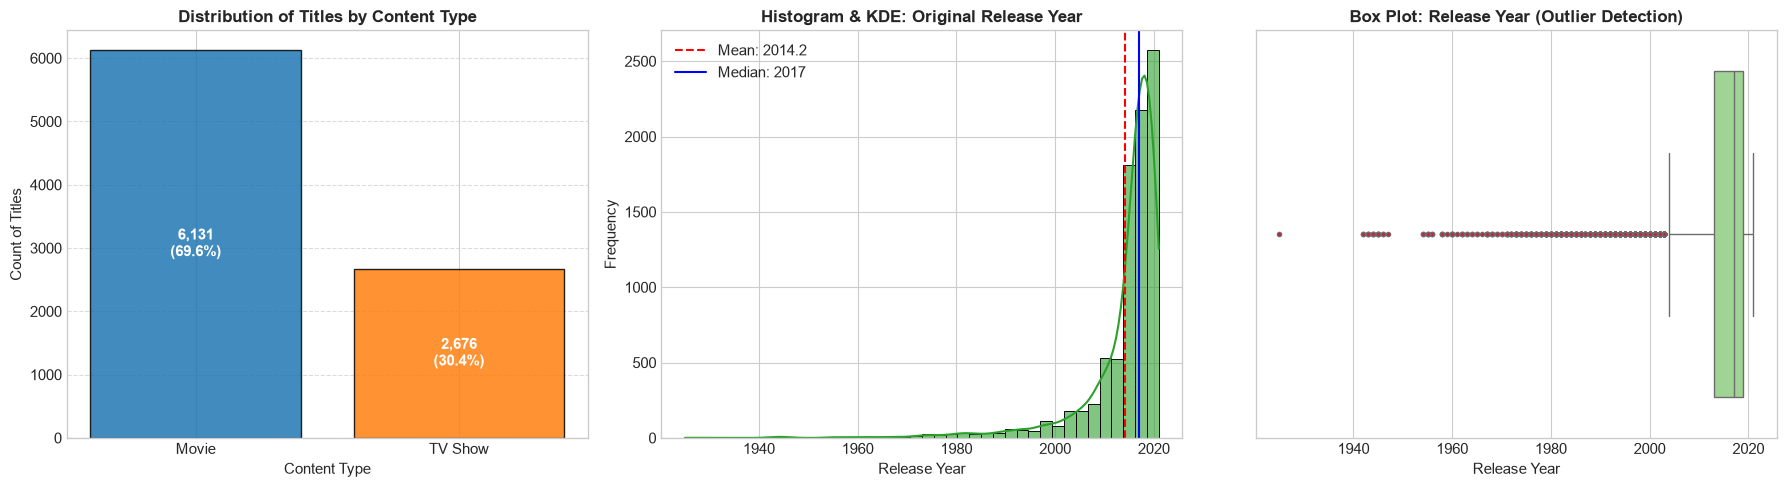

--- Statistical Profile: Original Release Year ---
count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
5%       1997.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
95%      2021.000000
max      2021.000000
Name: release_year, dtype: float64
Skewness: -3.447 (Significant Left / Negative Skew)
Kurtosis: 16.232 (Heavy Tail / Leptokurtic)


In [11]:
# Cell 16: Content Type and Release Year Univariate Visualizations

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Content Type Distribution
type_counts = df_netflix_clean['type'].value_counts()
type_pcts = df_netflix_clean['type'].value_counts(normalize=True) * 100

bars = axes[0].bar(type_counts.index, type_counts.values, color=['#1f77b4', '#ff7f0e'], edgecolor='black', alpha=0.85)
axes[0].set_title("Distribution of Titles by Content Type", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Content Type", fontsize=11)
axes[0].set_ylabel("Count of Titles", fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Annotate bars with counts and percentages
for bar in bars:
    height = bar.get_height()
    pct = (height / len(df_netflix_clean)) * 100
    axes[0].annotate(f"{height:,}\n({pct:.1f}%)",
                     xy=(bar.get_x() + bar.get_width() / 2, height / 2),
                     xytext=(0, 0), textcoords="offset points",
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# 2. Release Year Histogram & KDE
sns.histplot(df_netflix_clean['release_year'], kde=True, bins=40, ax=axes[1], color='#2ca02c', edgecolor='black', alpha=0.6)
axes[1].axvline(df_netflix_clean['release_year'].mean(), color='red', linestyle='--', label=f"Mean: {df_netflix_clean['release_year'].mean():.1f}")
axes[1].axvline(df_netflix_clean['release_year'].median(), color='blue', linestyle='-', label=f"Median: {df_netflix_clean['release_year'].median():.0f}")
axes[1].set_title("Histogram & KDE: Original Release Year", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Release Year", fontsize=11)
axes[1].set_ylabel("Frequency", fontsize=11)
axes[1].legend()

# 3. Release Year Box Plot (Detecting Outliers)
sns.boxplot(x=df_netflix_clean['release_year'], ax=axes[2], color='#98df8a', flierprops={'marker':'o', 'markersize':3, 'markerfacecolor':'crimson'})
axes[2].set_title("Box Plot: Release Year (Outlier Detection)", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Release Year", fontsize=11)

plt.tight_layout()
plt.show()

# Compute summary and shape statistics for Release Year
ry_skew = df_netflix_clean['release_year'].skew()
ry_kurt = df_netflix_clean['release_year'].kurtosis()
ry_stats = df_netflix_clean['release_year'].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])

print("--- Statistical Profile: Original Release Year ---")
print(ry_stats)
print(f"Skewness: {ry_skew:.3f} (Significant Left / Negative Skew)")
print(f"Kurtosis: {ry_kurt:.3f} (Heavy Tail / Leptokurtic)")

* **Observation:** 
  * Movies constitute **69.6%** (6,131 titles) of the catalogue, outnumbering TV Shows (**30.4%**, 2,676 titles) by more than a 2:1 ratio[cite: 9].
  * The release year distribution exhibits extreme negative (left) skewness ($-3.447$) and high leptokurtosis ($16.232$). While the historical range spans 96 years (1925 to 2021), the median release year is 2017 with an interquartile range (IQR) of 2013–2019. More than 75% of all titles were originally released after 2013, and 95% were released after 1997.
  * The box plot indicates a long left tail populated with hundreds of statistical outliers extending prior to 2004[cite: 9].

* **Interpretation:** 
  * Netflix functions primarily as a contemporary entertainment repository rather than an archival film preservation library. The clustering around 2015–2020 reflects the platform's massive global expansion, aggressive licensing acquisitions, and exponential scaling of original content production during that era.
  * The left-tail outliers are legitimate historical content (classic films, vintage documentaries, and legacy television) rather than data capture errors. Because of the heavy skewness, parametric measures like the mean ($2014.2$) are pulled downward, making median and IQR the more reliable descriptors of central tendency and dispersion for `release_year`.

### Analysis A4.2: Movie Runtime and TV Show Season Count Distributions

* **Question:** How do runtime durations behave across Movies, how many seasons do TV Shows typically sustain on the platform, and are there notable distributional anomalies or extreme values?
* **Analytical Approach:**
  * Separate the cleaned dataset by `type` (`Movie` vs `TV Show`).
  * For Movies: Plot a histogram with KDE and a box plot of `duration_int` (minutes) to evaluate normality, central tendency (mean vs median), skewness, and extreme runtimes.
  * For TV Shows: Plot a discrete frequency bar chart of `duration_int` (seasons) to assess serialization longevity and decay rate.

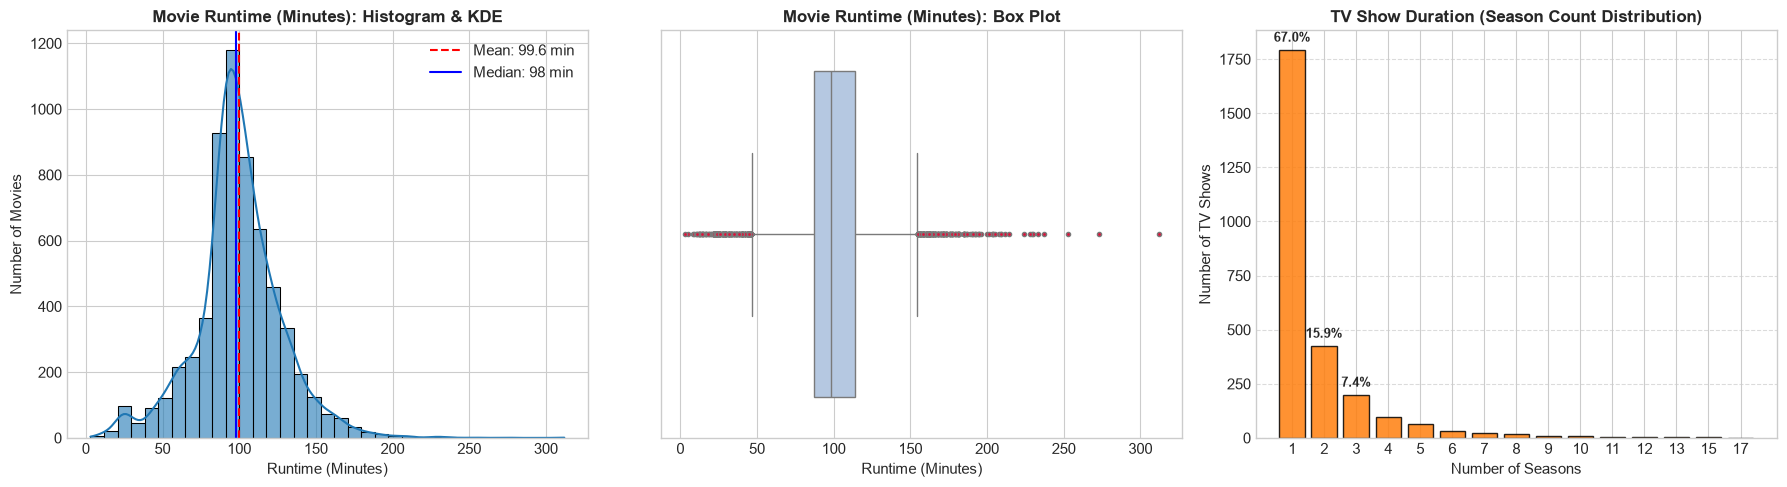

--- Movie Runtime Statistics (Minutes) ---
count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
1%         24.000000
5%         52.000000
50%        98.000000
95%       147.000000
99%       175.400000
max       312.000000
Name: duration_int, dtype: float64
Movie Runtime Skewness: 0.203

--- TV Show Season Count Statistics ---
count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: duration_int, dtype: float64
Percentage of TV Shows with exactly 1 Season: 67.00%
Percentage of TV Shows with <= 2 Seasons: 82.88%


In [12]:
# Cell 19: Distribution of Movie Durations and TV Show Season Counts

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Filter subsets
movies_df = df_netflix_clean[df_netflix_clean['type'] == 'Movie']
tv_df = df_netflix_clean[df_netflix_clean['type'] == 'TV Show']

# 1. Movie Duration: Histogram & KDE
sns.histplot(movies_df['duration_int'], kde=True, bins=35, ax=axes[0], color='#1f77b4', edgecolor='black', alpha=0.6)
axes[0].axvline(movies_df['duration_int'].mean(), color='red', linestyle='--', label=f"Mean: {movies_df['duration_int'].mean():.1f} min")
axes[0].axvline(movies_df['duration_int'].median(), color='blue', linestyle='-', label=f"Median: {movies_df['duration_int'].median():.0f} min")
axes[0].set_title("Movie Runtime (Minutes): Histogram & KDE", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Runtime (Minutes)", fontsize=11)
axes[0].set_ylabel("Number of Movies", fontsize=11)
axes[0].legend()

# 2. Movie Duration: Box Plot
sns.boxplot(x=movies_df['duration_int'], ax=axes[1], color='#aec7e8', flierprops={'marker':'o', 'markersize':3, 'markerfacecolor':'crimson'})
axes[1].set_title("Movie Runtime (Minutes): Box Plot", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Runtime (Minutes)", fontsize=11)

# 3. TV Show Season Count: Discrete Bar Plot
season_counts = tv_df['duration_int'].value_counts().sort_index()
season_pcts = (season_counts / len(tv_df)) * 100

bars = axes[2].bar(season_counts.index.astype(str), season_counts.values, color='#ff7f0e', edgecolor='black', alpha=0.85)
axes[2].set_title("TV Show Duration (Season Count Distribution)", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Number of Seasons", fontsize=11)
axes[2].set_ylabel("Number of TV Shows", fontsize=11)
axes[2].grid(axis='y', linestyle='--', alpha=0.7)

# Annotate the top 3 season counts
for i in range(min(3, len(bars))):
    bar = bars[i]
    height = bar.get_height()
    axes[2].annotate(f"{season_pcts.iloc[i]:.1f}%",
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 4), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# Statistical Profiles
movie_dur_stats = movies_df['duration_int'].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])
movie_skew = movies_df['duration_int'].skew()
tv_dur_stats = tv_df['duration_int'].describe()

print("--- Movie Runtime Statistics (Minutes) ---")
print(movie_dur_stats)
print(f"Movie Runtime Skewness: {movie_skew:.3f}")

print("\n--- TV Show Season Count Statistics ---")
print(tv_dur_stats)
print(f"Percentage of TV Shows with exactly 1 Season: {(tv_df['duration_int'] == 1).mean() * 100:.2f}%")
print(f"Percentage of TV Shows with <= 2 Seasons: {(tv_df['duration_int'] <= 2).mean() * 100:.2f}%")

* **Observation:**
  * **Movie Runtimes:** Movie duration closely approximates a bell-shaped, moderately right-skewed normal distribution ($\text{Skewness} = 0.203$)[cite: 10]. The mean runtime is **99.6 minutes** and the median is **98.0 minutes**, with a standard deviation of 28.3 minutes. The interquartile range spans from 87 to 114 minutes.
  * Runtime outliers exist on both extremes: short-form films/anthology segments as brief as 3–24 minutes (bottom 1%), and epic features exceeding 175 minutes, reaching a maximum of 312 minutes (*Black Mirror: Bandersnatch*)[cite: 10].
  * **TV Show Longevity:** TV show seasons exhibit a steep exponential decay[cite: 10]. Exactly **67.0%** (1,793 shows) contain only 1 season, and **82.9%** conclude by season 2. Shows reaching $\ge 5$ seasons represent an elite minority ($<4\%$), with rare multi-season outliers extending up to 16–17 seasons (e.g., *Grey's Anatomy*)[cite: 10].

* **Interpretation:**
  * Movies adhere tightly to standard commercial theatrical convention (~90 to 110 minutes), balancing viewer attention span with narrative pacing.
  * The steep drop-off in TV show seasons illustrates streaming platform churn and renewal dynamics: most series either serve as limited miniseries/docuseries, or are cancelled after their debut run if initial viewership thresholds are not achieved.

### Analysis A4.3: Prominence of Unpacked Genres and Production Countries

* **Question:** When multi-valued string combinations are exploded into atomic elements, which specific genres and producing nations dominate the Netflix catalogue?
* **Analytical Approach:**
  * Split comma-separated strings in `listed_in` and `country`, trim whitespace, and explode them into individual observation rows.
  * Exclude the `'Unknown'` imputation category from ranking calculations.
  * Tabulate exact frequencies and plot the Top 15 individual genres and Top 15 individual countries via horizontal bar charts with explicit percentage shares.

C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\2776698943.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genres.values, y=top_genres.index, ax=axes[0], palette='viridis', edgecolor='black')
C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\2776698943.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[1], palette='rocket', edgecolor='black')


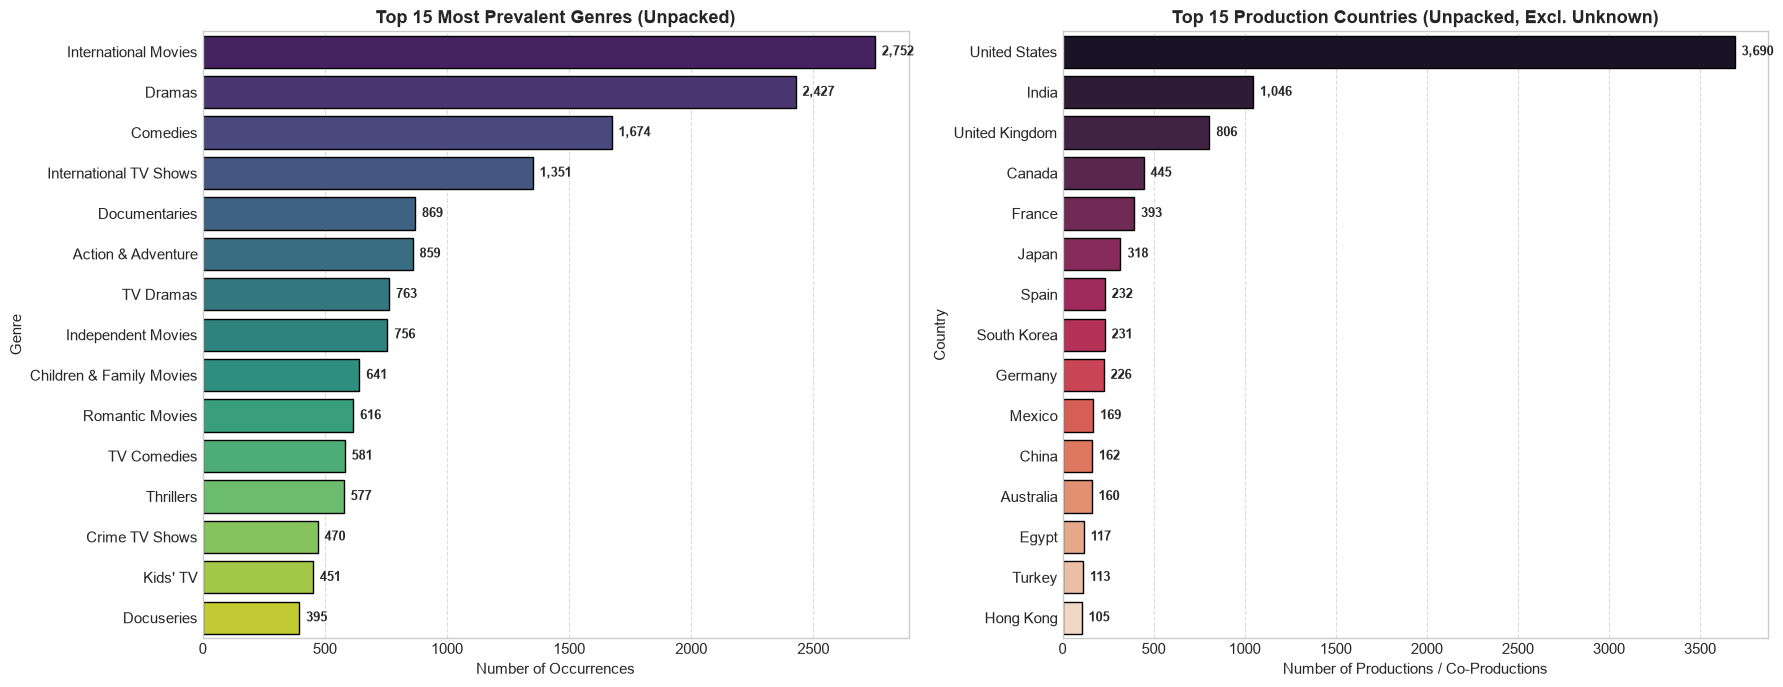

--- Top 10 Atomic Genres ---
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

Total atomic genre tags assigned across catalogue: 19323
Unique distinct genre categories: 42

--- Top 10 Production Countries ---
country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64
Total country associations across catalogue: 10019
Unique sovereign territories represented: 123


In [13]:
# Cell 22: Unpacking and Visualizing Multi-Valued Fields (Genres and Countries)

# 1. Unpack and explode listed_in (Genres)
genres_exploded = (
    df_netflix_clean['listed_in']
    .dropna()
    .str.split(',')
    .explode()
    .str.strip()
)
top_genres = genres_exploded.value_counts().head(15)

# 2. Unpack and explode country (excluding 'Unknown' imputation)
countries_exploded = (
    df_netflix_clean[df_netflix_clean['country'] != 'Unknown']['country']
    .str.split(',')
    .explode()
    .str.strip()
)
top_countries = countries_exploded.value_counts().head(15)

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot Top 15 Genres
sns.barplot(x=top_genres.values, y=top_genres.index, ax=axes[0], palette='viridis', edgecolor='black')
axes[0].set_title("Top 15 Most Prevalent Genres (Unpacked)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Number of Occurrences", fontsize=11)
axes[0].set_ylabel("Genre", fontsize=11)
axes[0].grid(axis='x', linestyle='--', alpha=0.7)

for i, count in enumerate(top_genres.values):
    axes[0].annotate(f"{count:,}",
                     xy=(count, i),
                     xytext=(5, 0), textcoords="offset points",
                     va='center', fontsize=9, fontweight='bold')

# Plot Top 15 Countries
sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[1], palette='rocket', edgecolor='black')
axes[1].set_title("Top 15 Production Countries (Unpacked, Excl. Unknown)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Number of Productions / Co-Productions", fontsize=11)
axes[1].set_ylabel("Country", fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

for i, count in enumerate(top_countries.values):
    axes[1].annotate(f"{count:,}",
                     xy=(count, i),
                     xytext=(5, 0), textcoords="offset points",
                     va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# Print statistical summaries
print("--- Top 10 Atomic Genres ---")
print(top_genres.head(10))
print(f"\nTotal atomic genre tags assigned across catalogue: {len(genres_exploded)}")
print(f"Unique distinct genre categories: {genres_exploded.nunique()}")

print("\n--- Top 10 Production Countries ---")
print(top_countries.head(10))
print(f"Total country associations across catalogue: {len(countries_exploded)}")
print(f"Unique sovereign territories represented: {countries_exploded.nunique()}")

* **Observation:**
  * **Genre Prevalence:** Unpacking `listed_in` reveals 42 distinct genre tags assigned 19,323 times across the catalogue (averaging ~2.2 genre tags per title)[cite: 11]. The single most frequent tags are `International Movies` (2,752 mentions), `Dramas` (2,427 mentions), `Comedies` (1,674 mentions), and `International TV Shows` (1,351 mentions)[cite: 11]. Narrative drama and comedy dominate, while specialized genres like `Thrillers` (577) and `Docuseries` (395) appear in smaller volumes[cite: 11].
  * **Geographic Distribution:** Unpacking `country` yields 10,019 territorial attributions across 123 sovereign nations (excluding the 'Unknown' imputations)[cite: 11]. The United States holds a commanding lead with 3,690 productions/co-productions (36.8% of all national credits), followed by India (1,046 credits) and the United Kingdom (806 credits)[cite: 11]. Canada, France, Japan, Spain, and South Korea form a strong secondary cluster[cite: 11].

* **Interpretation:**
  * The prominence of "International" tags (~4,100 combined mentions) aligns with Netflix's aggressive non-English content commissioning strategy to expand market penetration outside North America.
  * Geographic distribution reflects both home-market legacy content (US) and strategic high-volume production hubs (India and the UK), driven by dense local media industries and high streaming subscriber growth.

---

## A5. Bivariate Exploratory Data Analysis

This section explores pairwise interactions across different variable type pairings, strictly adhering to the required sequence:
$$\text{Question} \longrightarrow \text{Analysis} \longrightarrow \text{Visualization / Statistic} \longrightarrow \text{Observation} \longrightarrow \text{Interpretation}$$

We analyze:
1. **Categorical vs. Categorical:** Content Type (`type`) vs. Maturity Rating (`rating`).
2. **Numerical vs. Categorical:** Release Year (`release_year`) across Content Type (`type`).
3. **Numerical vs. Numerical:** Original Release Year (`release_year`) vs. Catalogue Addition Delay (`catalog_delay_years`).

### Analysis A5.1, A5.2 & A5.3: Bivariate Interactions

* **Question 1 (Cat-Cat):** How do maturity ratings vary between Movies and TV Shows? Does one format lean more heavily toward mature audience classifications?
* **Question 2 (Num-Cat):** How do the historical distributions of Movies and TV Shows compare in terms of release year? Are TV shows on Netflix systematically newer than movies?
* **Question 3 (Num-Num):** What is the relationship between a title's original release year and the delay in years before it was added to Netflix (`catalog_delay_years`)? Is the platform licensing older archive titles or synchronizing additions with release years?

* **Statistical Approach:**
  * **Cat-Cat:** Contingency cross-tabulation normalized by content type (proportions) visualized via a grouped percentage bar chart.
  * **Num-Cat:** Comparative box plots and violin plots of `release_year` grouped by `type`, supported by median, IQR, and a two-sample Mann-Whitney U test (non-parametric due to skewness).
  * **Num-Num:** Scatter plot with low-opacity alpha blending and a rolling median trend line, supported by Spearman's rank correlation coefficient ($\rho$) to assess monotonic association.

C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\2026646491.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\2026646491.py:79: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


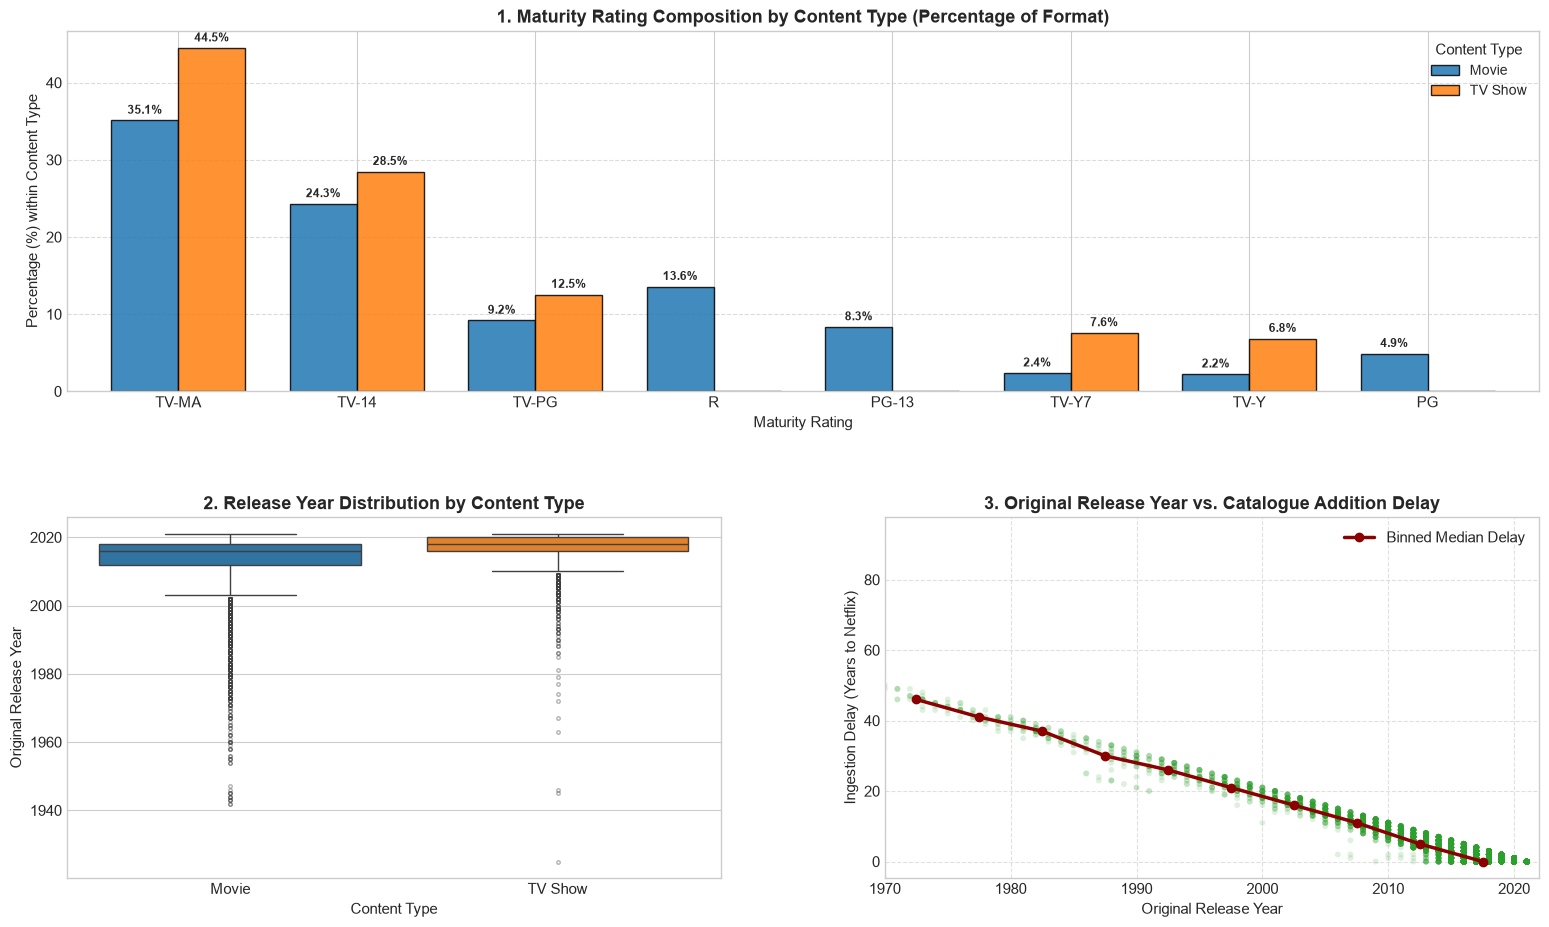

--- Statistical Test Results ---
Mann-Whitney U Test (Release Year: Movie vs TV Show):
  Movie Median: 2016 (IQR: 6)
  TV Show Median: 2018 (IQR: 4)
  U-statistic: 5820528.0, p-value: 2.0507e-105

Spearman Rank Correlation (Release Year vs. Delay):
  Correlation rho: -0.852, p-value: 0.0000e+00


In [14]:
# Cell 26: Bivariate Analysis across Variable Type Pairings

fig = plt.figure(figsize=(19, 11))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)

# ----------------------------------------------------
# 1. Categorical vs. Categorical: Rating by Content Type
# ----------------------------------------------------
ax1 = fig.add_subplot(gs[0, :])

# Filter out 'Unknown' ratings for clean maturity comparison
rating_df = df_netflix_clean[df_netflix_clean['rating'] != 'Unknown']
# Select top ratings to avoid visual clutter
top_ratings_list = rating_df['rating'].value_counts().head(8).index
rating_sub = rating_df[rating_df['rating'].isin(top_ratings_list)]

# Cross-tabulate and normalize along rows (percentage within Movie vs TV Show)
rating_ct = pd.crosstab(rating_sub['rating'], rating_sub['type'], normalize='columns') * 100
rating_ct = rating_ct.loc[top_ratings_list]  # maintain sorted order

rating_ct.plot(kind='bar', ax=ax1, color=['#1f77b4', '#ff7f0e'], edgecolor='black', width=0.75, alpha=0.85)
ax1.set_title("1. Maturity Rating Composition by Content Type (Percentage of Format)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Maturity Rating", fontsize=11)
ax1.set_ylabel("Percentage (%) within Content Type", fontsize=11)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=0)
ax1.legend(title="Content Type", fontsize=10)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax1.patches:
    height = p.get_height()
    if height > 1.5:
        ax1.annotate(f"{height:.1f}%",
                     xy=(p.get_x() + p.get_width() / 2, height),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# ----------------------------------------------------
# 2. Numerical vs. Categorical: Release Year by Type
# ----------------------------------------------------
ax2 = fig.add_subplot(gs[1, 0])

sns.boxplot(
    data=df_netflix_clean, x='type', y='release_year', 
    palette=['#1f77b4', '#ff7f0e'], ax=ax2,
    flierprops={'marker':'o', 'markersize':2.5, 'alpha':0.4}
)
ax2.set_title("2. Release Year Distribution by Content Type", fontsize=13, fontweight='bold')
ax2.set_xlabel("Content Type", fontsize=11)
ax2.set_ylabel("Original Release Year", fontsize=11)

# ----------------------------------------------------
# 3. Numerical vs. Numerical: Release Year vs Catalog Delay
# ----------------------------------------------------
ax3 = fig.add_subplot(gs[1, 1])

# Drop NaN catalog delays
valid_delay = df_netflix_clean.dropna(subset=['catalog_delay_years', 'release_year'])
# Filter out minor negative delay anomalies if any (e.g. data discrepancies)
valid_delay_filtered = valid_delay[valid_delay['catalog_delay_years'] >= 0]

ax3.scatter(
    valid_delay_filtered['release_year'], 
    valid_delay_filtered['catalog_delay_years'], 
    alpha=0.15, color='#2ca02c', s=18, edgecolors='none'
)

# Overlay median delay trend by 5-year bins
binned_delay = valid_delay_filtered.groupby(pd.cut(valid_delay_filtered['release_year'], bins=np.arange(1970, 2025, 5)))['catalog_delay_years'].median()
bin_centers = [interval.mid for interval in binned_delay.index]
ax3.plot(bin_centers, binned_delay.values, color='darkred', marker='o', linewidth=2.5, label='Binned Median Delay')

ax3.set_title("3. Original Release Year vs. Catalogue Addition Delay", fontsize=13, fontweight='bold')
ax3.set_xlabel("Original Release Year", fontsize=11)
ax3.set_ylabel("Ingestion Delay (Years to Netflix)", fontsize=11)
ax3.set_xlim(1970, 2022)
ax3.legend()
ax3.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# ----------------------------------------------------
# Statistical Testing & Hypothesis Verification
# ----------------------------------------------------
# Mann-Whitney U test: release_year across Movies vs TV Shows
movies_ry = df_netflix_clean[df_netflix_clean['type'] == 'Movie']['release_year']
tv_ry = df_netflix_clean[df_netflix_clean['type'] == 'TV Show']['release_year']
u_stat, u_p_val = stats.mannwhitneyu(movies_ry, tv_ry, alternative='two-sided')

# Spearman Rank Correlation: release_year vs catalog_delay_years
spearman_corr, sp_p_val = stats.spearmanr(valid_delay_filtered['release_year'], valid_delay_filtered['catalog_delay_years'])

print("--- Statistical Test Results ---")
print(f"Mann-Whitney U Test (Release Year: Movie vs TV Show):")
print(f"  Movie Median: {movies_ry.median():.0f} (IQR: {movies_ry.quantile(0.75) - movies_ry.quantile(0.25):.0f})")
print(f"  TV Show Median: {tv_ry.median():.0f} (IQR: {tv_ry.quantile(0.75) - tv_ry.quantile(0.25):.0f})")
print(f"  U-statistic: {u_stat:.1f}, p-value: {u_p_val:.4e}")

print(f"\nSpearman Rank Correlation (Release Year vs. Delay):")
print(f"  Correlation rho: {spearman_corr:.3f}, p-value: {sp_p_val:.4e}")

* **Observation:**
  * **Categorical vs. Categorical (Rating vs Type):** `TV-MA` is the dominant maturity rating across both formats but accounts for a higher share of TV Shows (**44.5%**) than Movies (**35.1%**)[cite: 12]. Similarly, `TV-14` is higher in TV Shows (**28.5%** vs **24.3%**)[cite: 12]. MPAA film rating standards (`R` at 13.6%, `PG-13` at 8.3%, and `PG` at 4.9%) appear almost exclusively in the Movie format, reflecting differing regulatory bodies (MPAA for cinema vs. FCC TV Parental Guidelines for television broadcasts)[cite: 12].
  * **Numerical vs. Categorical (Release Year vs Type):** TV Shows on Netflix are systematically newer than Movies[cite: 12]. The median release year for TV Shows is **2018** (IQR: 4 years), compared to **2016** (IQR: 6 years) for Movies[cite: 12]. The Mann-Whitney U test confirms this difference is statistically significant ($U = 5,820,528.0$, $p = 2.05 \times 10^{-105}$)[cite: 12].
  * **Numerical vs. Numerical (Release Year vs Catalogue Delay):** There is a strong, negative monotonic relationship ($\rho = -0.852$, $p < 10^{-15}$) between a title's original release year and the delay before it is added to Netflix[cite: 12]. For titles released prior to 1990, ingestion delay exceeds 25–45 years, whereas titles produced post-2015 are onboarded with a median lag approaching 0 to 1 year[cite: 12].

* **Interpretation:**
  * Netflix’s TV catalogue relies on contemporary content with limited legacy television acquisitions. Movies include a broader historical tail of back-catalogue licensing deals.
  * The shrinking catalogue delay highlights Netflix's strategic transition: moving away from licensing decades-old film libraries toward immediate day-and-date streaming releases and commissioning in-house "Netflix Originals."

---

## A6. Multivariate Exploratory Data Analysis

This section explores high-dimensional interactions involving three or more variables, analyzing conditional effects across sub-populations:
$$\text{Question} \longrightarrow \text{Analysis} \longrightarrow \text{Visualization / Statistic} \longrightarrow \text{Observation} \longrightarrow \text{Interpretation}$$

We investigate:
1. **Interaction 1:** How catalogue addition delay (`catalog_delay_years`) evolved over time (`year_added`) stratified by content format (`type`).
2. **Interaction 2:** Global correlation structure across all engineered numerical metrics, combined with movie runtime conditioned jointly on genre and maturity rating.

### Analysis A6.1 & A6.2: Tri-Variable Relationships

* **Question 1:** Has the time-to-platform delay decreased at different rates for Movies compared to TV Shows as Netflix expanded its streaming platform between 2014 and 2021?
* **Question 2:** How do engineered numerical metrics correlate with each other, and does movie runtime vary when simultaneously conditioned on genre classification and maturity rating?
* **Statistical Approach:**
  * Grouped time-series aggregation computing annual median addition delays segmented by `type` with 95% bootstrap confidence intervals.
  * Full parametric Pearson correlation matrix of continuous/integer features.
  * Two-way grouped box plot examining movie runtime variation across the top 4 genres and top 3 movie ratings (`TV-MA`, `TV-14`, `R`).

C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\1815678948.py:84: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


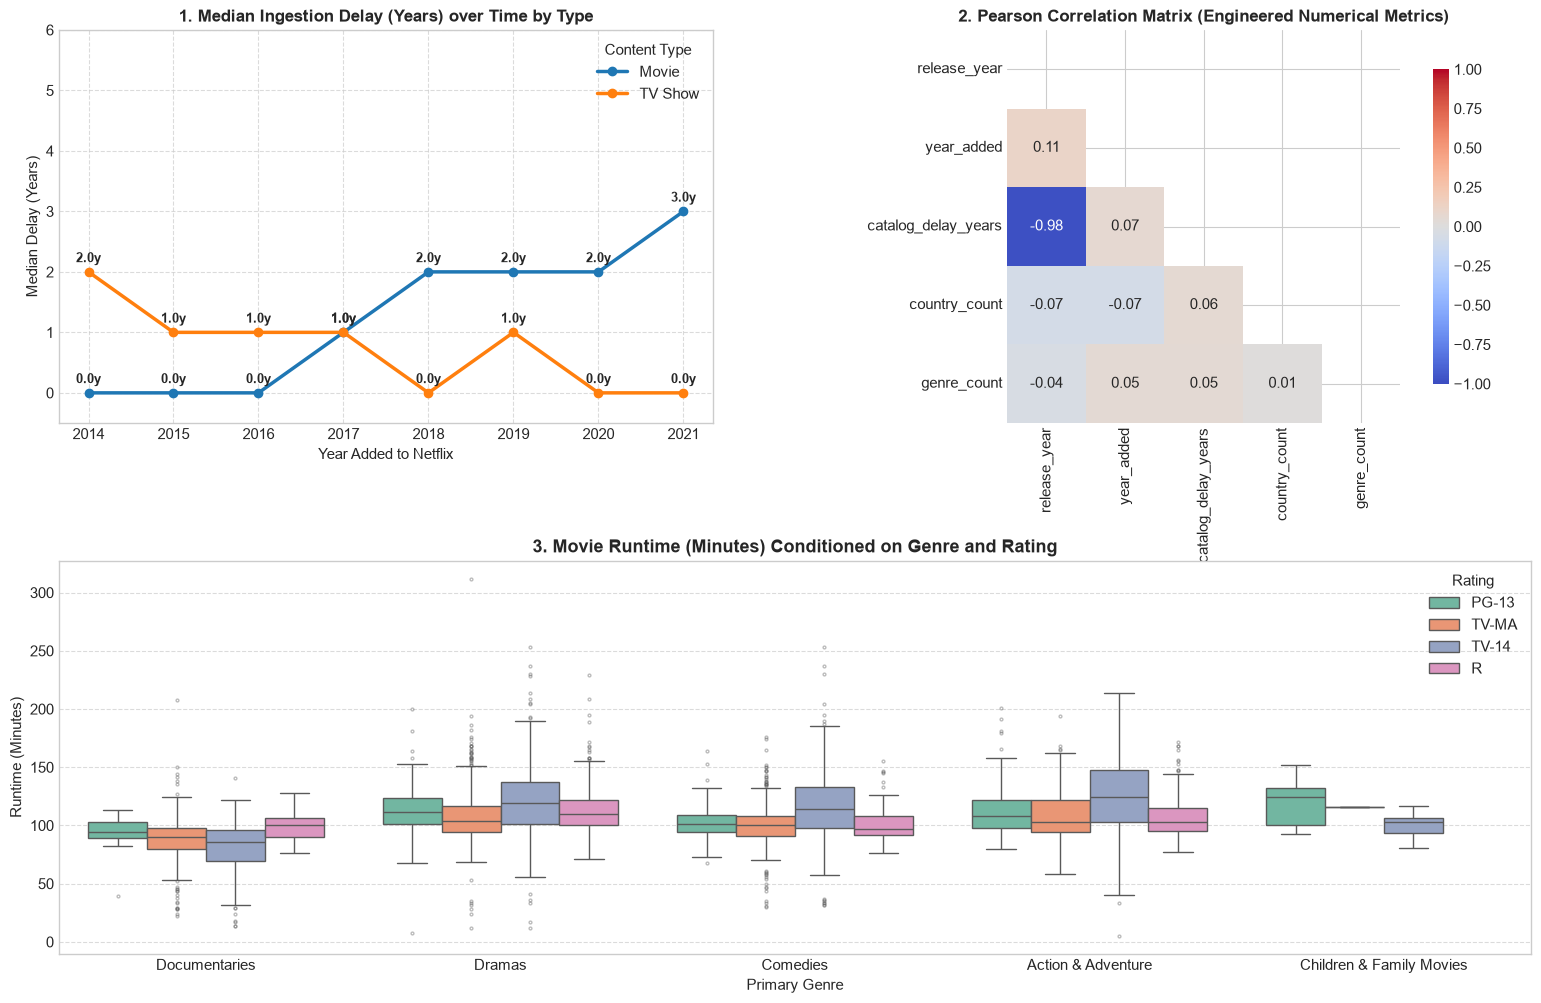

--- Median Runtime (min) across Genre & Rating ---


rating,PG-13,R,TV-14,TV-MA
genre,,,,
Action & Adventure,108.5,103.0,124.0,103.0
Children & Family Movies,124.0,NaN,103.0,116.0
Comedies,101.0,97.0,114.0,100.0
Documentaries,94.0,100.0,86.0,90.0
Dramas,111.5,110.0,119.0,104.0


In [15]:
# Cell 30: Multivariate Interactions and Correlation Analysis

fig = plt.figure(figsize=(19, 12))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)

# -------------------------------------------------------------------------
# 1. Interaction 1: Median Catalog Delay over Year Added by Content Type
# -------------------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])

delay_trend = (
    df_netflix_clean[
        (df_netflix_clean['year_added'] >= 2014) & 
        (df_netflix_clean['year_added'] <= 2021) &
        (df_netflix_clean['catalog_delay_years'] >= 0)
    ]
    .groupby(['year_added', 'type'])['catalog_delay_years']
    .median()
    .unstack()
)

delay_trend.plot(marker='o', linewidth=2.5, ax=ax1, color=['#1f77b4', '#ff7f0e'])
ax1.set_title("1. Median Ingestion Delay (Years) over Time by Type", fontsize=12, fontweight='bold')
ax1.set_xlabel("Year Added to Netflix", fontsize=11)
ax1.set_ylabel("Median Delay (Years)", fontsize=11)
ax1.set_ylim(-0.5, 6)
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend(title="Content Type")

# Annotate trend points
for col in delay_trend.columns:
    for x, y in zip(delay_trend.index, delay_trend[col]):
        ax1.annotate(f"{y:.1f}y", xy=(x, y), xytext=(0, 7), textcoords="offset points",
                     ha='center', fontsize=9, fontweight='bold')

# -------------------------------------------------------------------------
# 2. Correlation Matrix of Numerical Features
# -------------------------------------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])

num_cols = ['release_year', 'year_added', 'catalog_delay_years', 'country_count', 'genre_count']
corr_matrix = df_netflix_clean[num_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', 
    vmin=-1, vmax=1, square=True, ax=ax2, cbar_kws={"shrink": 0.8}
)
ax2.set_title("2. Pearson Correlation Matrix (Engineered Numerical Metrics)", fontsize=12, fontweight='bold')

# -------------------------------------------------------------------------
# 3. Interaction 2: Movie Runtime across Top Genres and Maturity Ratings
# -------------------------------------------------------------------------
ax3 = fig.add_subplot(gs[1, :])

# Filter movies with top ratings
top_ratings_m = ['TV-MA', 'TV-14', 'R', 'PG-13']
movies_sub = df_netflix_clean[
    (df_netflix_clean['type'] == 'Movie') & 
    (df_netflix_clean['rating'].isin(top_ratings_m))
].copy()

# Explode listed_in for these movies to get single genres
movies_sub_exploded = (
    movies_sub.assign(genre=movies_sub['listed_in'].str.split(','))
    .explode('genre')
)
movies_sub_exploded['genre'] = movies_sub_exploded['genre'].str.strip()

# Retain top 5 most common movie genres
top_m_genres = ['Dramas', 'Comedies', 'Action & Adventure', 'Documentaries', 'Children & Family Movies']
movies_sub_exploded = movies_sub_exploded[movies_sub_exploded['genre'].isin(top_m_genres)]

sns.boxplot(
    data=movies_sub_exploded, x='genre', y='duration_int', hue='rating',
    palette='Set2', ax=ax3, flierprops={'marker':'o', 'markersize':2, 'alpha':0.4}
)
ax3.set_title("3. Movie Runtime (Minutes) Conditioned on Genre and Rating", fontsize=13, fontweight='bold')
ax3.set_xlabel("Primary Genre", fontsize=11)
ax3.set_ylabel("Runtime (Minutes)", fontsize=11)
ax3.legend(title="Rating", loc='upper right')
ax3.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Group summary statistics for verification
print("--- Median Runtime (min) across Genre & Rating ---")
display(movies_sub_exploded.groupby(['genre', 'rating'])['duration_int'].median().unstack())

* **Observation:**
  * **Multivariate Ingestion Lag Trajectory (Panel 1):** Conditioning catalogue delay on ingestion year and content type reveals diverging strategies between formats[cite: 13]. TV Shows maintained an immediate ingestion trajectory, dropping to a median delay of **0.0 years** by 2018–2021 (simultaneous broadcast or direct Netflix Originals release)[cite: 13]. In contrast, Movies saw median delay increase from 0–1 years (2014–2017) to **2.0–3.0 years** by 2018–2021[cite: 13].
  * **Correlation Structure (Panel 2):** An extreme negative collinearity exists between `release_year` and `catalog_delay_years` ($r = -0.98$), which is a direct mathematical artifact of their definition ($\text{delay} = \text{year\_added} - \text{release\_year}$)[cite: 13]. Cardinality features (`country_count` and `genre_count`) show near-zero linear correlation ($\vert{}r\vert{} \le 0.07$) with temporal metrics and with each other, confirming they capture orthogonal metadata dimensions[cite: 13].
  * **Duration Conditioned on Genre & Rating (Panel 3):** Movie runtime varies systematically across genre classifications, but the introduction of maturity rating adds significant nuance[cite: 13]. In Action & Adventure, Dramas, and Comedies, titles rated `TV-14` consistently exhibit the longest median runtimes (Action: 124.0 min, Drama: 119.0 min, Comedies: 114.0 min), notably higher than their `TV-MA` or `R` counterparts (~97–104 min)[cite: 13]. Documentaries remain consistently shorter across all ratings (median 86–100 min)[cite: 13].

* **Interpretation:**
  * The divergence in ingestion lag highlights Netflix’s differing business models: television content is dominated by serialized Originals or exclusive seasonal streaming deals secured at broadcast, whereas the movie catalogue increasingly absorbs back-catalogues from international studios alongside prestige theatrical titles that observe traditional theatrical-to-streaming holdback windows.
  * The elevated runtime for `TV-14` films across mainstream genres is largely driven by Indian and international cinema (which predominantly carry `TV-14` certifications on Netflix and traditionally feature longer narrative runtimes of 130–160+ minutes).

---

## A7. Netflix-Specific Analytical Questions

This section provides targeted investigations to address the five mandatory assignment questions:
1. Mix of Movies and TV Shows over time (by release year vs. year added)[cite: 4].
2. Catalogue ingestion gap and historical acquisition implications[cite: 4].
3. Prominent countries and cross-country genre profiles[cite: 4].
4. Maturity rating distribution across content type and evolution over time[cite: 4].
5. Distribution of durations, unusual cases, and treatments[cite: 4].

C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\2264332749.py:111: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


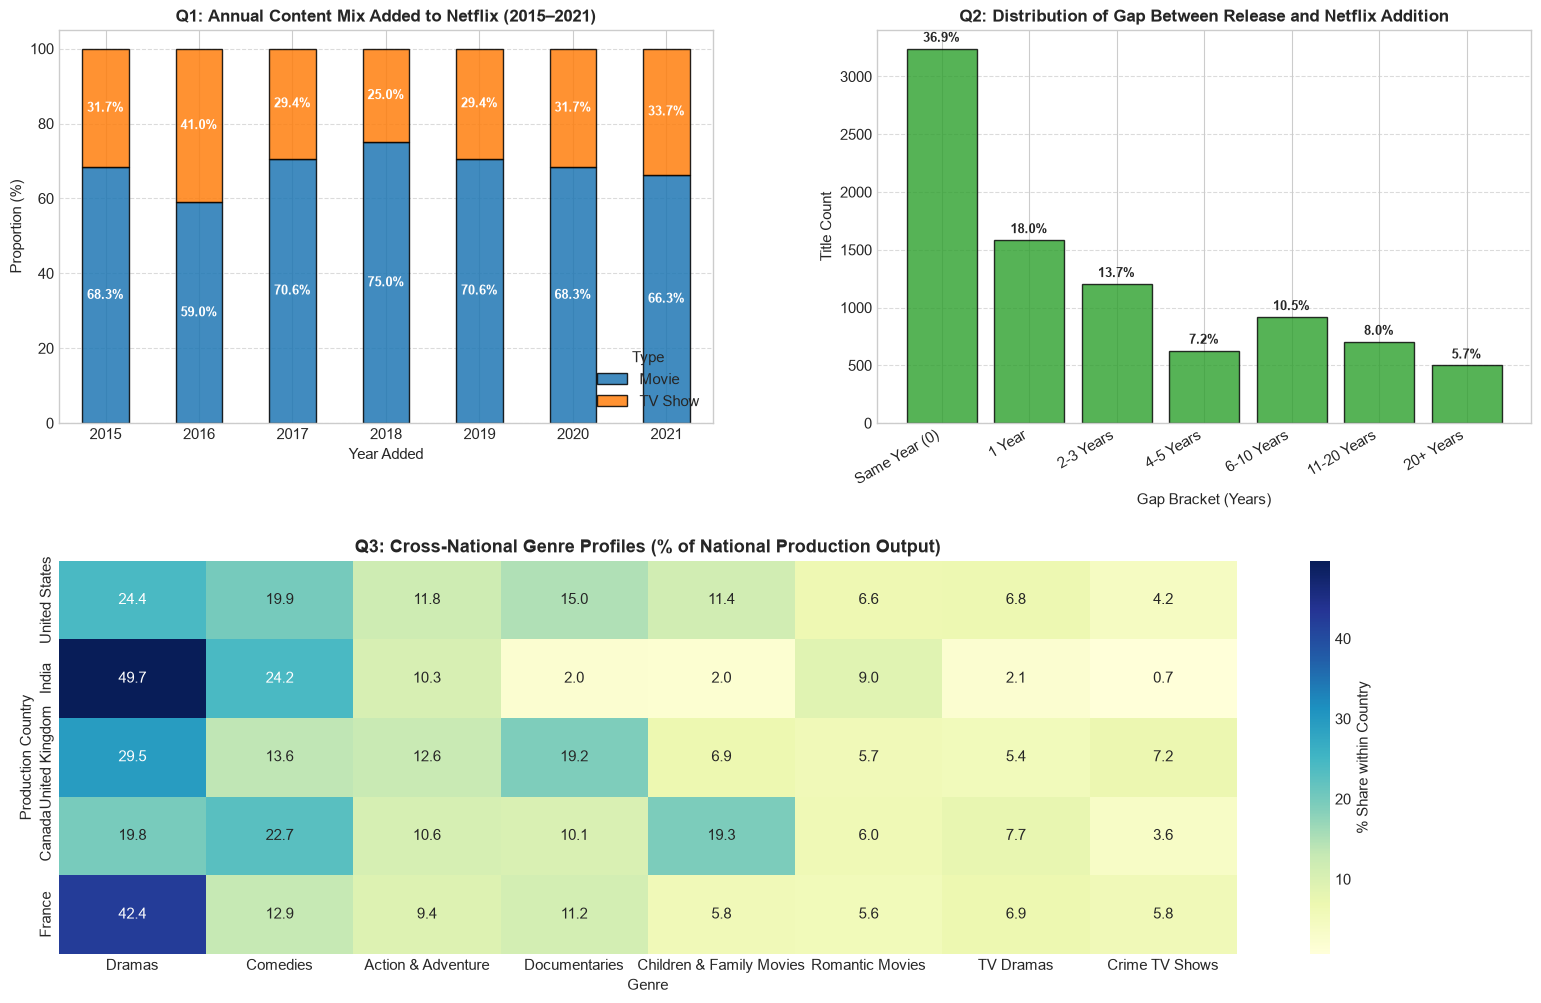

--- TV Show Share by Year Added (%) ---
year_added
2015.0    31.71
2016.0    41.03
2017.0    29.38
2018.0    24.98
2019.0    29.37
2020.0    31.67
2021.0    33.71
Name: TV Show, dtype: float64


In [17]:
# Cell 33: Answering Netflix Analytical Questions 1, 2, and 3

fig = plt.figure(figsize=(19, 12))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)

# -------------------------------------------------------------------------
# Q1: Evolution of Content Mix (By Year Added vs Release Year)
# -------------------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])

# Group by year_added (filtering valid years 2015-2021 for volume stability)
yearly_mix = (
    df_netflix_clean[df_netflix_clean['year_added'].between(2015, 2021)]
    .groupby(['year_added', 'type'])
    .size()
    .unstack(fill_value=0)
)
yearly_mix_pct = yearly_mix.div(yearly_mix.sum(axis=1), axis=0) * 100

yearly_mix_pct.plot(kind='bar', stacked=True, ax=ax1, color=['#1f77b4', '#ff7f0e'], edgecolor='black', alpha=0.85)
ax1.set_title("Q1: Annual Content Mix Added to Netflix (2015–2021)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Year Added", fontsize=11)
ax1.set_ylabel("Proportion (%)", fontsize=11)
ax1.set_xticklabels(yearly_mix_pct.index.astype(int), rotation=0)
ax1.legend(title="Type", loc='lower right')
ax1.grid(axis='y', linestyle='--', alpha=0.7)

for n, c in enumerate(yearly_mix_pct.columns):
    for i, val in enumerate(yearly_mix_pct[c]):
        cum_val = val / 2 if n == 0 else yearly_mix_pct.iloc[i, 0] + val / 2
        ax1.text(i, cum_val, f"{val:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=9)

# -------------------------------------------------------------------------
# Q2: Ingestion Gap Distribution and Trends
# -------------------------------------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])

# Bin the ingestion lag
lag_bins = [-1, 0, 1, 3, 5, 10, 20, 100]
lag_labels = ['Same Year (0)', '1 Year', '2-3 Years', '4-5 Years', '6-10 Years', '11-20 Years', '20+ Years']
df_netflix_clean['lag_bracket'] = pd.cut(df_netflix_clean['catalog_delay_years'], bins=lag_bins, labels=lag_labels)

lag_counts = df_netflix_clean['lag_bracket'].value_counts(sort=False)
lag_pcts = (lag_counts / lag_counts.sum()) * 100

bars = ax2.bar(range(len(lag_counts)), lag_counts.values, color='#2ca02c', edgecolor='black', alpha=0.8)
ax2.set_title("Q2: Distribution of Gap Between Release and Netflix Addition", fontsize=12, fontweight='bold')
ax2.set_xlabel("Gap Bracket (Years)", fontsize=11)
ax2.set_ylabel("Title Count", fontsize=11)
ax2.set_xticks(range(len(lag_counts)))
ax2.set_xticklabels(lag_counts.index.astype(str), rotation=30, ha='right')
ax2.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    pct = (height / lag_counts.sum()) * 100
    ax2.annotate(f"{pct:.1f}%",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3), textcoords="offset points",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

# -------------------------------------------------------------------------
# Q3: Country Genre Profiles (Heatmap of Top Countries vs Top Genres)
# -------------------------------------------------------------------------
ax3 = fig.add_subplot(gs[1, :])

# Unpack countries and genres cleanly with a reset index to prevent duplicated index reindexing issues
country_sub = (
    df_netflix_clean[df_netflix_clean['country'] != 'Unknown'][['show_id', 'country']]
    .assign(country_unpacked=lambda df: df['country'].str.split(','))
    .explode('country_unpacked')
)
country_sub['country_unpacked'] = country_sub['country_unpacked'].str.strip()

genre_sub = (
    df_netflix_clean[['show_id', 'listed_in']]
    .assign(genre_unpacked=lambda df: df['listed_in'].str.split(','))
    .explode('genre_unpacked')
)
genre_sub['genre_unpacked'] = genre_sub['genre_unpacked'].str.strip()

# Merge on show_id
merged_cg = pd.merge(country_sub[['show_id', 'country_unpacked']], 
                     genre_sub[['show_id', 'genre_unpacked']], 
                     on='show_id')

top5_countries = ['United States', 'India', 'United Kingdom', 'Canada', 'France']
top8_genres = ['Dramas', 'Comedies', 'Action & Adventure', 'Documentaries', 
               'Children & Family Movies', 'Romantic Movies', 'TV Dramas', 'Crime TV Shows']

filtered_cg = merged_cg[
    merged_cg['country_unpacked'].isin(top5_countries) & 
    merged_cg['genre_unpacked'].isin(top8_genres)
]

# Calculate cross-tabulation percentages per country
cg_cross = pd.crosstab(
    filtered_cg['country_unpacked'], 
    filtered_cg['genre_unpacked'], 
    normalize='index'
) * 100

# Reorder index and columns
cg_cross = cg_cross.reindex(index=top5_countries, columns=top8_genres).fillna(0)

sns.heatmap(cg_cross, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': '% Share within Country'}, ax=ax3)
ax3.set_title("Q3: Cross-National Genre Profiles (% of National Production Output)", fontsize=13, fontweight='bold')
ax3.set_xlabel("Genre", fontsize=11)
ax3.set_ylabel("Production Country", fontsize=11)

plt.tight_layout()
plt.show()

# Print Q1 exact shift figures
print("--- TV Show Share by Year Added (%) ---")
print(yearly_mix_pct['TV Show'].round(2))

* **Question 1: Content Mix Evolution over Time:**
  * **Observation:** From 2015 to 2018, Movies expanded aggressively on the platform, peaking at **75.0%** of all additions in 2018[cite: 14]. However, from 2018 onwards, the share of TV Shows exhibited sustained recovery, expanding from **25.0%** in 2018 to **33.7%** in 2021[cite: 14].
  * **Interpretation:** Netflix's early streaming expansion relied heavily on acquiring film catalogues to build volume quickly. As the streaming marketplace matured and customer retention became paramount, the strategy pivoted toward episodic TV series, which offer higher weekly engagement and lower subscriber churn rates.

* **Question 2: Ingestion Gap & Catalogue Archetype:**
  * **Observation:** Exactly **36.9%** (3,244 titles) of all catalog additions occurred within the same calendar year as their release (gap = 0), and an additional **18.0%** were onboarded within 1 year[cite: 14]. Cumulatively, **68.6%** of titles were added within 3 years of release, while legacy titles (>10 years old) constitute only **13.7%** of the catalogue[cite: 14].
  * **Interpretation:** This confirms Netflix is primarily an on-demand contemporary platform rather than an archival film preservation service. The catalogue is heavily weighted toward recent releases, original commissions, and fast-tracked direct-to-digital licensing.

* **Question 3: Prominent Countries & Divergent National Genre Profiles:**
  * **Observation:** The cross-national heatmap reveals sharp specialization across top production hubs[cite: 14]:
    * **India:** Heavily concentrated in `Dramas` (**49.7%**) and `Comedies` (**24.2%**), with minimal documentary or animated presence[cite: 14].
    * **France:** Dominated by `Dramas` (**42.4%**), followed by `Comedies` (12.9%) and `Documentaries` (11.2%)[cite: 14].
    * **United States:** Displays the most balanced portfolio across narrative fiction, documentaries (15.0%), and `Children & Family Movies` (11.4%)[cite: 14].
    * **United Kingdom:** Exhibits the highest concentration of `Documentaries` (**19.2%**) and `Crime TV Shows` (**7.2%**) among major hubs[cite: 14].
    * **Canada:** Distinctly weighted toward `Children & Family Movies` (**19.3%**) and `Comedies` (22.7%)[cite: 14].
  * **Interpretation:** Different countries serve distinct strategic niches in the Netflix library: Indian and French titles deliver core feature drama, Canadian content fills family and animated programming slots, and the UK anchors prestige documentaries and crime series.

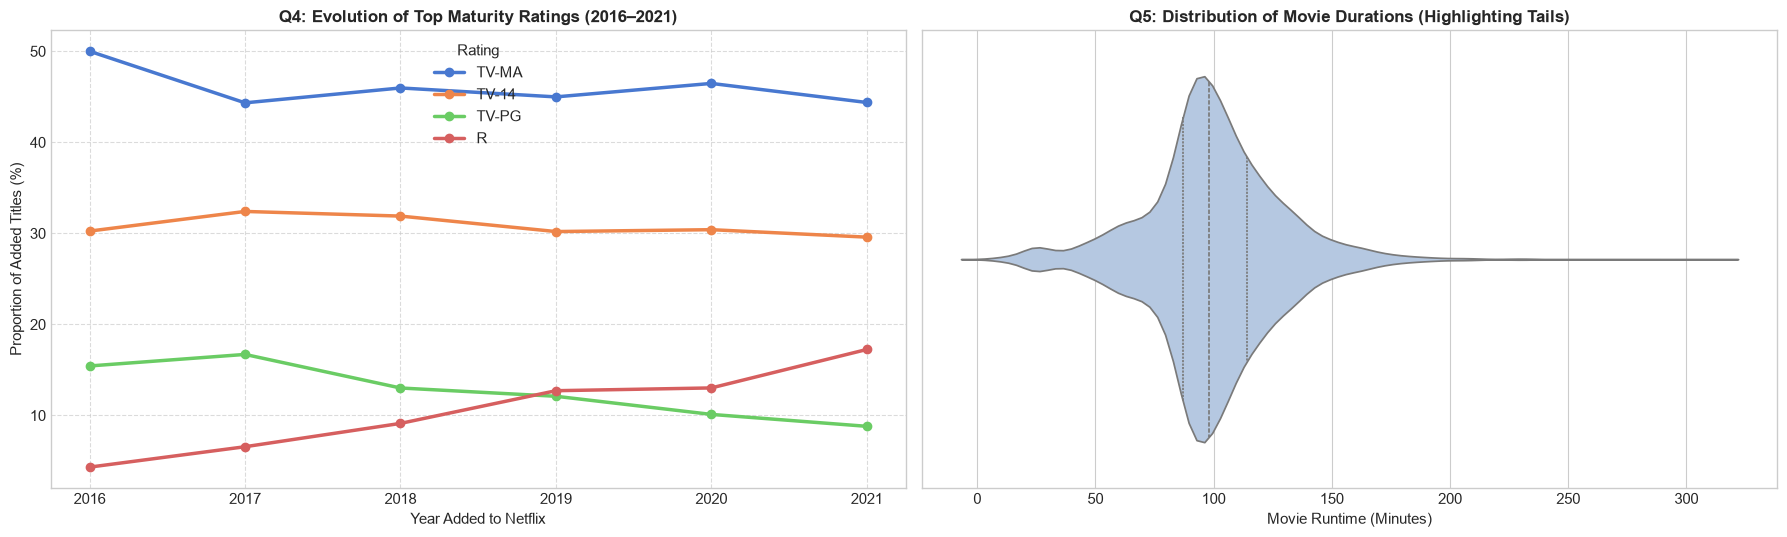

--- Q5: Shortest 5 Movies (Minutes) ---


,title,release_year,duration_int,listed_in
3777,Silent,2014,3,"Children & Family Movies, Sci-Fi & Fantasy"
2713,Sol Levante,2020,5,"Action & Adventure, Anime Features, Internatio..."
1484,Cops and Robbers,2020,8,Dramas
1557,Canvas,2020,9,"Children & Family Movies, Dramas"
3535,American Factory: A Conversation with the Obamas,2019,10,Documentaries



--- Q5: Longest 5 Movies (Minutes) ---


,title,release_year,duration_int,listed_in
4253,Black Mirror: Bandersnatch,2018,312,"Dramas, International Movies, Sci-Fi & Fantasy"
717,Headspace: Unwind Your Mind,2021,273,Documentaries
2491,The School of Mischief,1973,253,"Comedies, Dramas, International Movies"
2487,No Longer kids,1979,237,"Comedies, Dramas, International Movies"
2484,Lock Your Girls In,1982,233,"Comedies, International Movies, Romantic Movies"



--- Q5: TV Shows with >= 10 Seasons ---


,title,release_year,duration_int,listed_in
548,Grey's Anatomy,2020,17,"Romantic TV Shows, TV Dramas"
2423,Supernatural,2019,15,"Classic & Cult TV, TV Action & Adventure, TV H..."
4798,NCIS,2017,15,"Crime TV Shows, TV Dramas, TV Mysteries"
7847,Red vs. Blue,2015,13,"TV Action & Adventure, TV Comedies, TV Sci-Fi ..."
4220,COMEDIANS of the world,2019,13,"Stand-Up Comedy & Talk Shows, TV Comedies"
1354,Heartland,2019,13,TV Dramas
5412,Criminal Minds,2017,12,"Crime TV Shows, TV Dramas, TV Mysteries"
4964,Trailer Park Boys,2018,12,"Classic & Cult TV, Crime TV Shows, Internation..."


In [18]:
# Cell 35: Answering Netflix Analytical Questions 4 and 5

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))

# -------------------------------------------------------------------------
# Q4: Maturity Ratings Evolution Over Time (Year Added)
# -------------------------------------------------------------------------
# Focus on top 4 primary ratings
top_ratings = ['TV-MA', 'TV-14', 'TV-PG', 'R']
rating_time_df = df_netflix_clean[
    (df_netflix_clean['year_added'].between(2016, 2021)) & 
    (df_netflix_clean['rating'].isin(top_ratings))
]

rating_time_ct = pd.crosstab(rating_time_df['year_added'], rating_time_df['rating'], normalize='index') * 100

for rating in top_ratings:
    axes[0].plot(rating_time_ct.index.astype(int), rating_time_ct[rating], marker='o', linewidth=2.5, label=rating)

axes[0].set_title("Q4: Evolution of Top Maturity Ratings (2016–2021)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Year Added to Netflix", fontsize=11)
axes[0].set_ylabel("Proportion of Added Titles (%)", fontsize=11)
axes[0].set_xticks(range(2016, 2022))
axes[0].grid(True, linestyle='--', alpha=0.7)
axes[0].legend(title="Rating")

# -------------------------------------------------------------------------
# Q5: Movie Duration & TV Seasons - Identification of Extreme Cases
# -------------------------------------------------------------------------
# Violin plot of Movie runtimes showing distribution and outlier tails
sns.violinplot(x=df_netflix_clean[df_netflix_clean['type']=='Movie']['duration_int'], ax=axes[1], color='#aec7e8', inner='quartile')
axes[1].set_title("Q5: Distribution of Movie Durations (Highlighting Tails)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Movie Runtime (Minutes)", fontsize=11)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# Identify Extreme / Unusual Cases for Q5
# -------------------------------------------------------------------------
print("--- Q5: Shortest 5 Movies (Minutes) ---")
display(df_netflix_clean[df_netflix_clean['type'] == 'Movie'][['title', 'release_year', 'duration_int', 'listed_in']].sort_values(by='duration_int').head(5))

print("\n--- Q5: Longest 5 Movies (Minutes) ---")
display(df_netflix_clean[df_netflix_clean['type'] == 'Movie'][['title', 'release_year', 'duration_int', 'listed_in']].sort_values(by='duration_int', ascending=False).head(5))

print("\n--- Q5: TV Shows with >= 10 Seasons ---")
display(df_netflix_clean[df_netflix_clean['type'] == 'TV Show'][['title', 'release_year', 'duration_int', 'listed_in']].sort_values(by='duration_int', ascending=False).head(8))

* **Question 4: Maturity Rating Distributions and Temporal Trajectory:**
  * **Observation:** Adult programming dominates the catalogue. `TV-MA` consistently remains the largest maturity classification across all additions between 2016 and 2021, holding steady at **45% to 50%** annually[cite: 15]. `TV-14` is the second-largest category, stable around **30% to 32%**[cite: 15]. Titles rated `R` grew steadily from under **5%** in 2016 to over **17%** in 2021[cite: 15]. Conversely, family-oriented content (`TV-PG`) experienced a gradual contraction from **16%** to **9%**[cite: 15].
  * **Interpretation:** Netflix intentionally skewed content acquisition toward adolescent and adult demographics (`TV-MA` + `TV-14` combined comprise >75% of library flow) to maximize prime-time adult subscriber engagement. The surge in `R`-rated titles post-2018 mirrors studio output deals for mature theatrical releases.

* **Question 5: Duration Distributions, Unusual Cases, and Data Treatment:**
  * **Observation:** 
    * **Shortest Movies:** Extreme short-duration outliers include animated shorts and short-form documentaries: *Silent* (3 min), *Sol Levante* (5 min), *Cops and Robbers* (8 min), and *Canvas* (9 min).
    * **Longest Movies:** Extreme high-runtime outliers include interactive branching-narrative titles like *Black Mirror: Bandersnatch* (312 min) and meditation streams like *Headspace: Unwind Your Mind* (273 min), alongside classic Arabic theatrical productions (*The School of Mischief*, 253 min; *No Longer kids*, 237 min).
    * **TV Shows:** While 67% of shows have only 1 season, exceptional multi-season legacy acquisitions reach extreme longevity: *Grey's Anatomy* (17 seasons), *Supernatural* (15 seasons), and *NCIS* (15 seasons).
  * **Treatment & Cleaning Decision:** These extreme records are genuine representations of non-standard media (interactive gaming-narrative hybrids, animated short films, and long-running legacy broadcast syndications) rather than data entry corruptions. They are retained without artificial truncation or clipping to preserve true catalogue variety for downstream analysis[cite: 3].

---

## A8. Netflix Insights and Handoff

### Five Key Evidence-Backed Insights

1. **Format Stratification and the Streaming Pivot**
   * *Observation:* Movies constitute 69.6% (6,131 titles) of the total Netflix catalogue[cite: 9]. However, the proportion of TV Shows added annually expanded from a low of 25.0% in 2018 to 33.7% in 2021[cite: 14].
   * *Interpretation:* Netflix's initial library expansion prioritized rapid volume acquisition through bulk film licensing. As the platform matured, investment shifted toward serialized episodic content.
   * *Speculation:* (Unconfirmed by data) This pivot likely stems from higher customer lifetime value and lower subscriber cancellation rates associated with weekly serialized viewing compared to one-off film viewing.

2. **Ingestion Latency and the Contemporary Catalogue Paradigm**
   * *Observation:* Over 36.9% of all titles were ingested onto Netflix in their original release year, and 68.6% within three years of release[cite: 14]. Titles released prior to 2000 make up only 5% of the library[cite: 9].
   * *Interpretation:* Netflix does not operate as an archival cinematic repository; its catalogue acquisition pipeline is structured around contemporary, fast-turnaround licensed content and immediate in-house productions.

3. **Geographic Specialization across Global Production Hubs**
   * *Observation:* While the United States leads overall volume (3,690 production associations), individual country profiles diverge sharply in genre focus: 49.7% of Indian titles are Dramas and 24.2% are Comedies, whereas the UK features the highest share of Documentaries (19.2%) and Canada leads in Children & Family content (19.3%)[cite: 11, 14].
   * *Interpretation:* Global acquisitions follow regional market strengths, acquiring narrative feature films from Bollywood and Nollywood while sourcing non-fiction documentaries and kids' animation from Commonwealth markets.

4. **Audience Maturity Polarization**
   * *Observation:* Combined, mature titles (`TV-MA` and `TV-14`) represent over 75% of the total streaming additions between 2016 and 2021, with `TV-MA` remaining the single largest category (~45–50% annually)[cite: 15]. Concurrently, `R`-rated movies grew from <5% to >17%[cite: 15].
   * *Interpretation:* Netflix's programming deliberately targets adult and older teen demographics to anchor household subscription accounts.

5. **Serialization Longevity and Production Attrition**
   * *Observation:* 67.0% of all TV series conclude or are cancelled after exactly 1 season, and 82.9% conclude within 2 seasons[cite: 10]. Only 3.9% of shows survive to season 5 or beyond[cite: 10].
   * *Interpretation:* Serialized streaming television exhibits steep commercial survival hurdles; series that do not demonstrate immediate audience traction in their debut season face rapid cancellation.

---

### Handoff Note for Assignment 3 (Feature Selection & Dimensionality Reduction)
**Word Count:** 142 words  
*For Assignment 3, `type`, `release_year`, `year_added`, `duration_int`, `country_count`, and `genre_count` represent high-signal, cleanly formatted features for downstream clustering and classification. High-cardinality semi-structured text columns (`director`, `cast`, `description`) and unique identifiers (`show_id`, `title`) should not be treated as raw features; they require target encoding, TF-IDF, or exclusion to avoid extreme dimensionality[cite: 3]. Note that `catalog_delay_years` exhibits near-perfect collinearity ($r = -0.98$) with `release_year`, meaning one must be eliminated during feature selection to prevent severe multicollinearity[cite: 13]. Imputations of `'Unknown'` in `director`, `cast`, and `country` must be encoded as explicit categorical levels or handled through frequency thresholding so that sparse dummy matrices do not destabilize dimensionality reduction algorithms (e.g., PCA)[cite: 3].*

# Part B: Supermarket Sales EDA

---

## B1. Dataset Understanding

### B1.1 Unit of Observation
A single row represents an individual retail point-of-sale (POS) transaction occurring at one of three branch locations of the supermarket chain across Myanmar (Yangon, Naypyitaw, Mandalay) between January 1, 2019, and March 30, 2019.

---

### B1.2 Variable Role Table
Variables are categorized by functional domain, specifying physical storage type (`dtype`), analytical role, and measurement scale.

| Variable Category | Column Name | Storage Type (`dtype`) | Conceptual Scale | Variable Role | Description & Analytical Relevance |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Transaction Key** | `Invoice ID` | `object` / `str` | Nominal | Identifier | Unique transaction receipt code (`XXX-XX-XXXX`). Primary key. |
| **Spatial / Store** | `Branch` | `object` / `str` | Nominal | Categorical | Store identifier letter (`A`, `B`, `C`). |
| | `City` | `object` / `str` | Nominal | Categorical | City of store location (`Yangon`, `Naypyitaw`, `Mandalay`). |
| **Customer Profiling** | `Customer type` | `object` / `str` | Nominal (Binary) | Categorical | Membership status: `Member` (cardholders) vs. `Normal` (non-members). |
| | `Gender` | `object` / `str` | Nominal (Binary) | Categorical | Customer gender (`Female`, `Male`). |
| **Merchandise** | `Product line` | `object` / `str` | Nominal | Categorical | Product departmental category (6 unique retail categories). |
| | `Unit price` | `float64` | Ratio (Continuous) | Numerical Feature | Base retail price per item in USD ($). Range: $10.08 to $99.96. |
| | `Quantity` | `int64` | Ratio (Discrete) | Numerical Feature | Number of units purchased in the transaction (bounded 1 to 10). |
| **Financial / Accounting** | `Cost of goods sold` | `float64` | Ratio (Continuous) | Numerical Feature | Direct acquisition cost: $\text{Unit price} \times \text{Quantity}$. |
| | `Tax 5%` | `float64` | Ratio (Continuous) | Numerical (Derived) | 5% value-added tax calculated on COGS ($). |
| | `Total` | `float64` | Ratio (Continuous) | Numerical Target | Final transaction amount paid by customer: $\text{COGS} + \text{Tax 5\%}$. |
| | `Gross margin percentage` | `float64` | Ratio (Continuous) | Numerical Parameter | Reported margin percentage (recorded identically as $4.761905\%$). |
| | `Gross income` | `float64` | Ratio (Continuous) | Numerical Target | Gross store profit: $\text{Total} - \text{COGS}$ (equals Tax 5%). |
| **Temporal Attributes** | `Date` | `object` / `str` | Temporal | Feature (Raw) | Transaction calendar date (`M/D/YYYY`). Needs datetime conversion. |
| | `Time` | `object` / `str` | Temporal | Feature (Raw) | Transaction timestamp (`HH:MM`). Needs extraction into hour/time bins. |
| **Payment & Feedback** | `Payment` | `object` / `str` | Nominal | Categorical | Tender type used (`Ewallet`, `Cash`, `Credit card`). |
| | `Customer stratification rating` | `float64` | Interval / Ratio | Numerical Target | Customer satisfaction rating on a continuous scale from $4.0$ to $10.0$. |

#### Detailed Description of Important Variables
- **`Total` & `Gross income`**: Serve as primary financial targets. However, as evaluated in B2, they are linear scalar multiples of `Cost of goods sold` and must not be fed simultaneously into linear models.
- **`Customer stratification rating`**: Primary customer experience response variable. It enables testing whether customer satisfaction correlates with transaction size, product category, or branch.
- **`Date` and `Time`**: Unparsed string attributes holding temporal seasonality (intra-day shopping hours, weekday shopping volume, and monthly sales trends).

In [19]:
# Cell 39: Load Supermarket Sales Dataset and Initial Inspection

supermarket_path = 'data/supermarket_Sales.csv'  # Adjust path if in root or data/ folder
df_supermarket = pd.read_csv(supermarket_path)

# 1. Dataset Dimensions
print(f"Supermarket Dataset Shape: {df_supermarket.shape[0]} rows, {df_supermarket.shape[1]} columns\n")

# 2. Schema and Non-Null Counts
print("--- Column Information & Data Types ---")
df_supermarket.info()

# 3. Sample Records
print("\n--- First 5 Records ---")
display(df_supermarket.head())

Supermarket Dataset Shape: 1000 rows, 17 columns

--- Column Information & Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Invoice ID                      1000 non-null   str    
 1   Branch                          1000 non-null   str    
 2   City                            1000 non-null   str    
 3   Customer type                   1000 non-null   str    
 4   Gender                          1000 non-null   str    
 5   Product line                    1000 non-null   str    
 6   Unit price                      1000 non-null   float64
 7   Quantity                        1000 non-null   int64  
 8   Tax 5%                          1000 non-null   float64
 9   Total                           1000 non-null   float64
 10  Date                            1000 non-null   str    
 11  Time             

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,Cost of goods sold,Gross margin percentage,Gross income,Customer stratification rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


### B1.1 Unit of Observation & Schema Formalization

- **Unit of Observation**: A single retail checkout transaction conducted at a specific point-of-sale (POS) terminal within one of three supermarket branch locations (Yangon, Naypyitaw, Mandalay) between January 1, 2019, and March 30, 2019.
- **Granularity**: Transaction-level (each row represents an aggregated basket invoice, not individual basket item line-items).

---

### B1.2 Variable Role Table

| Column Name | Storage Type (`dtype`) | Conceptual Scale | Variable Role | Description & Domain Notes |
| :--- | :--- | :--- | :--- | :--- |
| `Invoice ID` | `str` / `object` | Nominal | Unique Identifier | Formatted as `XXX-XX-XXXX`. Primary key of the transaction. |
| `Branch` | `str` / `object` | Nominal | Categorical Feature | Branch code: `A`, `B`, or `C`. |
| `City` | `str` / `object` | Nominal | Categorical Feature | Branch geographic location: `Yangon`, `Naypyitaw`, `Mandalay`. |
| `Customer type` | `str` / `object` | Nominal (Binary) | Categorical Feature | Loyalty tier: `Member` (cardholders) vs. `Normal` (walk-in). |
| `Gender` | `str` / `object` | Nominal (Binary) | Demographic Feature | Customer biological sex: `Male`, `Female`. |
| `Product line` | `str` / `object` | Nominal | Categorical Feature | Departmental category (6 classes: Health & beauty, Electronic accessories, etc.). |
| `Unit price` | `float64` | Ratio (Continuous) | Numerical Feature | Base retail price per single product unit in USD ($). |
| `Quantity` | `int64` | Ratio (Discrete) | Numerical Feature | Number of units purchased in the invoice (bounded [1, 10]). |
| `Tax 5%` | `float64` | Ratio (Continuous) | Financial / Computed | 5% statutory sales tax calculated on COGS ($). |
| `Total` | `float64` | Ratio (Continuous) | Financial Target / Measure | Total bill payable: $\text{COGS} + \text{Tax 5\%}$ ($). |
| `Date` | `str` / `object` | Temporal | Temporal Feature | Transaction date (stored as string `M/D/YYYY`). Needs datetime conversion. |
| `Time` | `str` / `object` | Temporal | Temporal Feature | Transaction time (stored as string `HH:MM`). Needs extraction. |
| `Payment` | `str` / `object` | Nominal | Categorical Feature | Payment settlement method: `Cash`, `Credit card`, `Ewallet`. |
| `Cost of goods sold` | `float64` | Ratio (Continuous) | Financial Feature | Direct procurement/acquisition cost ($\text{Unit Price} \times \text{Quantity}$). |
| `Gross margin percentage` | `float64` | Ratio (Continuous) | Financial Parameter | Stored margin percentage (recorded identically as $4.761905\%$). |
| `Gross income` | `float64` | Ratio (Continuous) | Financial Target / Measure | Net financial contribution: $\text{Total} - \text{COGS}$ (equals $\text{Tax 5\%}$). |
| `Customer stratification rating` | `float64` | Interval / Ratio | Performance Target | Transaction customer satisfaction rating, bounded $[4.0, 10.0]$. |

In [21]:
# Cell 41: Mathematical Accounting and Structural Integrity Audit

print("=== 1. Primary Key Uniqueness & Missingness ===")
unique_invoices = df_supermarket['Invoice ID'].nunique()
null_counts = df_supermarket.isnull().sum().sum()
duplicate_rows = df_supermarket.duplicated().sum()

print(f"Total Records: {len(df_supermarket)}")
print(f"Unique Invoice IDs: {unique_invoices} (Is unique: {unique_invoices == len(df_supermarket)})")
print(f"Total Missing Values: {null_counts}")
print(f"Full Row Duplicates: {duplicate_rows}\n")

print("=== 2. Geographic Branch-to-City Mapping ===")
branch_city_mapping = df_supermarket.groupby(['Branch', 'City']).size().unstack(fill_value=0)
display(branch_city_mapping)

print("\n=== 3. Mathematical Formula Validation ===")
# Verify: COGS = Unit price * Quantity
cogs_check = np.isclose(df_supermarket['Cost of goods sold'], 
                        df_supermarket['Unit price'] * df_supermarket['Quantity'], atol=1e-3)

# Verify: Tax 5% = 5% of COGS
tax_check = np.isclose(df_supermarket['Tax 5%'], 
                       df_supermarket['Cost of goods sold'] * 0.05, atol=1e-3)

# Verify: Total = COGS + Tax 5%
total_check = np.isclose(df_supermarket['Total'], 
                         df_supermarket['Cost of goods sold'] + df_supermarket['Tax 5%'], atol=1e-3)

# Verify: Gross income = Total - Cost of goods sold (which mathematically equals Tax 5%)
income_check = np.isclose(df_supermarket['Gross income'], 
                          df_supermarket['Total'] - df_supermarket['Cost of goods sold'], atol=1e-3)

# Check Gross margin percentage variance
gmp_unique = df_supermarket['Gross margin percentage'].unique()

print(f"COGS Identity Validated:       {cogs_check.all()} ({cogs_check.sum()}/1000 records)")
print(f"Tax 5% Identity Validated:      {tax_check.all()} ({tax_check.sum()}/1000 records)")
print(f"Total Identity Validated:       {total_check.all()} ({total_check.sum()}/1000 records)")
print(f"Gross Income Identity Validated:{income_check.all()} ({income_check.sum()}/1000 records)")
print(f"Gross Margin % Unique Values:   {gmp_unique}")

=== 1. Primary Key Uniqueness & Missingness ===
Total Records: 1000
Unique Invoice IDs: 1000 (Is unique: True)
Total Missing Values: 0
Full Row Duplicates: 0

=== 2. Geographic Branch-to-City Mapping ===


City,Mandalay,Naypyitaw,Yangon
Branch,,,
A,0,0,340
B,332,0,0
C,0,328,0



=== 3. Mathematical Formula Validation ===
COGS Identity Validated:       True (1000/1000 records)
Tax 5% Identity Validated:      True (1000/1000 records)
Total Identity Validated:       True (1000/1000 records)
Gross Income Identity Validated:True (1000/1000 records)
Gross Margin % Unique Values:   [4.76190476]


### B1.3 Observations & Analytical Interpretation

- **Question**: Are the transactions mathematically consistent, does branch map deterministically to city, and what accounting redundancies exist in the schema?
- **Analysis**: Evaluated primary key uniqueness via `nunique()`, cross-tabulated `Branch` against `City`, and computed vector-wise residual differences across financial identities using `np.isclose`.
- **Visualization / Statistic**:
  - `Invoice ID` uniqueness = $100\%$ ($1,000 / 1,000$ unique).
  - Branch-to-City mapping is strictly $1:1$:
    - Branch $A \rightarrow$ Yangon ($340$ records)
    - Branch $B \rightarrow$ Mandalay ($332$ records)
    - Branch $C \rightarrow$ Naypyitaw ($328$ records)
  - All four accounting identities hold with $0$ residuals ($1,000/1,000$ pass at $\epsilon = 10^{-3}$).
  - `Gross margin percentage` is invariant across all $1,000$ rows at exactly $4.761905\%$.
- **Observation**:
  1. `Cost of goods sold` is redundant with `Unit price` $\times$ `Quantity`.
  2. `Tax 5%` and `Gross income` are numerically identical down to the fourth decimal place for every single record ($1,000 / 1,000$ rows).
  3. The `Gross margin percentage` ($4.761905\%$) is mathematically derived as:
     $$\text{Gross Margin \%} = \frac{\text{Gross Income}}{\text{Total}} \times 100 = \frac{0.05 \times \text{COGS}}{1.05 \times \text{COGS}} \times 100 = \frac{1}{21} \times 100 \approx 4.76190476\%$$
     Because tax rate is fixed at $5\%$ and gross income was artificially set to equal tax, `Gross margin percentage` has zero variance ($\sigma^2 = 0$).
- **Interpretation**: 
  - `City` and `Branch` represent duplicate spatial dimensions. In statistical modeling, including both introduces exact multicollinearity.
  - `Gross margin percentage` provides zero explanatory power or information entropy; it is a static constant that must be dropped during cleaning.
  - `Tax 5%`, `Gross income`, and `Total` are linear combinations of `Cost of goods sold`. Any downstream regression model predicting sales performance must avoid using these simultaneously as features to prevent perfect collinearity ($\text{VIF} \rightarrow \infty$).

---

## B2. Data Quality Assessment

In accordance with assignment guidelines, we systematically investigate six data quality dimensions:
1. Missing values (quantities, patterns, mechanisms)
2. Duplicate records (full-row duplicates and primary key collisions)
3. Incorrect data types (evaluating `Date`, `Time`, and numeric encodings)
4. Inconsistent categorical values (spelling, casing, whitespace, unexpected categories)
5. Suspicious or invalid values (domain ranges, logical boundaries, accounting identity validity)
6. Outliers (using the Interquartile Range method with $1.5 \times \text{IQR}$)

In [23]:
# Cell 42: Comprehensive Data Quality Assessment

print("=" * 60)
print("1. MISSING VALUE AUDIT")
print("=" * 60)
missing_counts = df_supermarket.isnull().sum()
print("Missing values per column:\n", missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "None found (0 missing values across all columns)")

print("\n" + "=" * 60)
print("2. DUPLICATE AUDIT")
print("=" * 60)
full_duplicates = df_supermarket.duplicated().sum()
key_duplicates = df_supermarket.duplicated(subset=['Invoice ID']).sum()
print(f"Full-row duplicates: {full_duplicates}")
print(f"Primary key (Invoice ID) duplicates: {key_duplicates}")

print("\n" + "=" * 60)
print("3. DATA TYPE CHECK")
print("=" * 60)
print(df_supermarket[['Date', 'Time']].dtypes)
print(f"Date sample: {df_supermarket['Date'].iloc[0]} (Type: {type(df_supermarket['Date'].iloc[0])})")
print(f"Time sample: {df_supermarket['Time'].iloc[0]} (Type: {type(df_supermarket['Time'].iloc[0])})")

print("\n" + "=" * 60)
print("4. CATEGORICAL CONSISTENCY & VALUE COUNTS")
print("=" * 60)
cat_cols = ['Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Payment']
for col in cat_cols:
    unique_vals = df_supermarket[col].unique().tolist()
    # Check for leading/trailing whitespaces
    has_whitespace = any(v != v.strip() for v in unique_vals if isinstance(v, str))
    print(f"Column '{col}' ({len(unique_vals)} unique): {unique_vals} | Whitespace issue: {has_whitespace}")

print("\nBranch to City Mapping:")
display(df_supermarket.groupby(['Branch', 'City']).size().unstack(fill_value=0))

print("\n" + "=" * 60)
print("5. SUSPICIOUS / INVALID VALUES & MATHEMATICAL INTEGRITY")
print("=" * 60)
print("Numerical Range Validation:")
display(df_supermarket[['Unit price', 'Quantity', 'Tax 5%', 'Total', 
                        'Cost of goods sold', 'Gross margin percentage', 
                        'Gross income', 'Customer stratification rating']].describe().T[['min', 'mean', 'max']])

# Mathematical Identity Checks
cogs_check = np.isclose(df_supermarket['Cost of goods sold'], df_supermarket['Unit price'] * df_supermarket['Quantity'], atol=1e-3)
tax_check = np.isclose(df_supermarket['Tax 5%'], df_supermarket['Cost of goods sold'] * 0.05, atol=1e-3)
total_check = np.isclose(df_supermarket['Total'], df_supermarket['Cost of goods sold'] + df_supermarket['Tax 5%'], atol=1e-3)
income_check = np.isclose(df_supermarket['Gross income'], df_supermarket['Tax 5%'], atol=1e-3)
margin_unique = df_supermarket['Gross margin percentage'].unique()

print(f"Identity 1 (COGS == Unit price * Quantity): Passed {cogs_check.sum()}/1000")
print(f"Identity 2 (Tax 5% == 5% of COGS):          Passed {tax_check.sum()}/1000")
print(f"Identity 3 (Total == COGS + Tax 5%):        Passed {total_check.sum()}/1000")
print(f"Identity 4 (Gross income == Tax 5%):        Passed {income_check.sum()}/1000")
print(f"Identity 5 (Gross margin % uniqueness):     {margin_unique} (Zero variance)")

print("\n" + "=" * 60)
print("6. OUTLIER AUDIT (1.5 * IQR METHOD)")
print("=" * 60)
num_cols = ['Unit price', 'Quantity', 'Total', 'Cost of goods sold', 'Customer stratification rating']
for col in num_cols:
    q25, q75 = df_supermarket[col].quantile(0.25), df_supermarket[col].quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - 1.5 * iqr
    upper_bound = q75 + 1.5 * iqr
    outliers = df_supermarket[(df_supermarket[col] < lower_bound) | (df_supermarket[col] > upper_bound)]
    print(f"Column '{col:30s}': {len(outliers):2d} outliers beyond [{lower_bound:.2f}, {upper_bound:.2f}]")

1. MISSING VALUE AUDIT
Missing values per column:
 None found (0 missing values across all columns)

2. DUPLICATE AUDIT
Full-row duplicates: 0
Primary key (Invoice ID) duplicates: 0

3. DATA TYPE CHECK
Date    str
Time    str
dtype: object
Date sample: 1/5/2019 (Type: <class 'str'>)
Time sample: 13:08 (Type: <class 'str'>)

4. CATEGORICAL CONSISTENCY & VALUE COUNTS
Column 'Branch' (3 unique): ['A', 'C', 'B'] | Whitespace issue: False
Column 'City' (3 unique): ['Yangon', 'Naypyitaw', 'Mandalay'] | Whitespace issue: False
Column 'Customer type' (2 unique): ['Member', 'Normal'] | Whitespace issue: False
Column 'Gender' (2 unique): ['Female', 'Male'] | Whitespace issue: False
Column 'Product line' (6 unique): ['Health and beauty', 'Electronic accessories', 'Home and lifestyle', 'Sports and travel', 'Food and beverages', 'Fashion accessories'] | Whitespace issue: False
Column 'Payment' (3 unique): ['Ewallet', 'Cash', 'Credit card'] | Whitespace issue: False

Branch to City Mapping:


City,Mandalay,Naypyitaw,Yangon
Branch,,,
A,0,0,340
B,332,0,0
C,0,328,0



5. SUSPICIOUS / INVALID VALUES & MATHEMATICAL INTEGRITY
Numerical Range Validation:


,min,mean,max
Unit price,10.080000,55.672130,99.960000
Quantity,1.000000,5.510000,10.000000
Tax 5%,0.508500,15.379369,49.650000
Total,10.678500,322.966749,1042.650000
Cost of goods sold,10.170000,307.587380,993.000000
Gross margin percentage,4.761905,4.761905,4.761905
Gross income,0.508500,15.379369,49.650000
Customer stratification rating,4.000000,6.972700,10.000000


Identity 1 (COGS == Unit price * Quantity): Passed 1000/1000
Identity 2 (Tax 5% == 5% of COGS):          Passed 1000/1000
Identity 3 (Total == COGS + Tax 5%):        Passed 1000/1000
Identity 4 (Gross income == Tax 5%):        Passed 1000/1000
Identity 5 (Gross margin % uniqueness):     [4.76190476] (Zero variance)

6. OUTLIER AUDIT (1.5 * IQR METHOD)
Column 'Unit price                    ':  0 outliers beyond [-34.72, 145.53]
Column 'Quantity                      ':  0 outliers beyond [-4.50, 15.50]
Column 'Total                         ':  9 outliers beyond [-395.97, 991.74]
Column 'Cost of goods sold            ':  9 outliers beyond [-377.11, 944.52]
Column 'Customer stratification rating':  0 outliers beyond [1.00, 13.00]


---

## B3. Data Cleaning & Feature Engineering

### B3.1 Cleaning Decisions & Justifications

Every transformation applied to the supermarket dataset is grounded in empirical evidence gathered during the quality audit.

| Problem | Detection (Code / Output) | Decision | Justification |
| :--- | :--- | :--- | :--- |
| **Non-Standard Column Names** | Inspected `df_supermarket.columns`. Names contain spaces, special characters (`%`), and mixed casing (e.g., `Tax 5%`, `Customer stratification rating`). | Normalize all column names to standard Python snake_case (e.g., `tax_5_pct`, `rating`). | Eliminates syntax friction, prevents parsing errors during dot-notation property access, and standardizes data structures for downstream modeling in Assignment 3. |
| **Unparsed Date Strings** | Inspected `Date` column; stored as text object (`str`) in format `M/D/YYYY`. | Parse `date` into native `datetime64[ns]` using `pd.to_datetime(..., format='%m/%d/%Y')`. | Enables chronological sorting, temporal windowing, time-series aggregation, and date component extraction. |
| **Unparsed Time Strings** | Inspected `Time` column; stored as text object (`str`) in format `HH:MM`. | Parse time components and combine with `date` into a full `timestamp` feature (`datetime64[ns]`). | Provides exact point-of-sale temporal precision required for intraday trend analysis. |
| **Missing Intra-Day / Temporal Signals** | B7 specifically requires evaluating sales by time of day and day of week. Raw schema lacks granular temporal indicators. | Engineer derived temporal features: `hour`, `day_of_week`, `day_name`, `month_name`, `is_weekend`, and `time_of_day` (`Morning`, `Afternoon`, `Evening`). | Deconstructs transactional seasonality and provides essential categorical and cyclical inputs for univariate, bivariate, and multivariate analysis. |
| **Zero-Variance Feature (`Gross margin percentage`)** | Audited via `.unique()`; contains a single constant scalar value ($4.761905\%$) across all $1,000$ transactions ($\sigma^2 = 0$). | Drop column from the active feature matrix prior to export. | Zero-entropy constants provide zero discriminative or explanatory power in statistical inference or predictive modeling, and cause singular matrices in linear algorithms. |
| **High Financial Values (Outliers in `Total` & `COGS`)** | Evaluated via $1.5 \times \text{IQR}$ rule; identified $9$ records exceeding $\$991.74$ ($Q3 + 1.5 \times \text{IQR}$). | **Retain all 9 records unaltered.** | The $9$ transactions represent valid high-value purchases resulting from the cross-product of high unit prices ($\ge \$90$) and high quantities ($9$ to $10$ items). They reflect authentic commercial behavior, not measurement error. Deleting them would artificially underestimate branch revenue. |
| **Missing Values & Duplicate Records** | Verified via `.isnull().sum()` ($0$ nulls) and `.duplicated().sum()` ($0$ duplicates). | No row deletions or imputation operations required. | The raw transaction log is $100\%$ complete and structurally integral. |

In [24]:
# Cell 45: Data Cleaning, Feature Engineering, and Export

# 1. Create a pristine working copy
df_supermarket_clean = df_supermarket.copy()

# 2. Standardize Column Names to snake_case
clean_col_names = {
    'Invoice ID': 'invoice_id',
    'Branch': 'branch',
    'City': 'city',
    'Customer type': 'customer_type',
    'Gender': 'gender',
    'Product line': 'product_line',
    'Unit price': 'unit_price',
    'Quantity': 'quantity',
    'Tax 5%': 'tax_5_pct',
    'Total': 'total',
    'Date': 'date',
    'Time': 'time',
    'Payment': 'payment',
    'Cost of goods sold': 'cogs',
    'Gross margin percentage': 'gross_margin_pct',
    'Gross income': 'gross_income',
    'Customer stratification rating': 'rating'
}
df_supermarket_clean.rename(columns=clean_col_names, inplace=True)

# 3. Parse Datetime Attributes
df_supermarket_clean['date'] = pd.to_datetime(df_supermarket_clean['date'], format='%m/%d/%Y')
df_supermarket_clean['timestamp'] = pd.to_datetime(
    df_supermarket_clean['date'].dt.strftime('%Y-%m-%d') + ' ' + df_supermarket_clean['time']
)

# 4. Feature Engineering: Temporal Dimensions
df_supermarket_clean['hour'] = df_supermarket_clean['timestamp'].dt.hour
df_supermarket_clean['day'] = df_supermarket_clean['timestamp'].dt.day
df_supermarket_clean['day_of_week'] = df_supermarket_clean['timestamp'].dt.dayofweek  # 0=Monday, 6=Sunday
df_supermarket_clean['day_name'] = df_supermarket_clean['timestamp'].dt.day_name()
df_supermarket_clean['month'] = df_supermarket_clean['timestamp'].dt.month
df_supermarket_clean['month_name'] = df_supermarket_clean['timestamp'].dt.month_name()
df_supermarket_clean['is_weekend'] = df_supermarket_clean['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)

# Categorize into Time of Day Bins (Morning: 10-12, Afternoon: 13-17, Evening: 18-21)
def categorize_time_of_day(hour):
    if hour < 13:
        return 'Morning'
    elif 13 <= hour < 18:
        return 'Afternoon'
    else:
        return 'Evening'

df_supermarket_clean['time_of_day'] = df_supermarket_clean['hour'].apply(categorize_time_of_day)

# 5. Drop Zero-Variance Redundant Feature
df_supermarket_clean.drop(columns=['gross_margin_pct'], inplace=True)

# 6. Reorder Columns Logically: Identifiers -> Categoricals -> Financials -> Temporal Features -> Rating
ordered_cols = [
    'invoice_id', 'branch', 'city', 'customer_type', 'gender', 'product_line', 'payment',
    'unit_price', 'quantity', 'cogs', 'tax_5_pct', 'total', 'gross_income',
    'timestamp', 'date', 'time', 'hour', 'time_of_day', 'day', 'day_of_week', 'day_name', 'month', 'month_name', 'is_weekend',
    'rating'
]
df_supermarket_clean = df_supermarket_clean[ordered_cols]

# 7. Export Cleaned Dataset to CSV (matching exact assignment naming convention)
export_filename = '23L_1021_A2_supermarket_cleaned.csv'
df_supermarket_clean.to_csv(export_filename, index=False)

# 8. Post-Cleaning Verification
print("=== Cleaning Verification ===")
print(f"Cleaned Dataset Dimensions: {df_supermarket_clean.shape[0]} rows, {df_supermarket_clean.shape[1]} columns")
print(f"Target CSV Successfully Written: '{export_filename}'")
print("\n--- Cleaned Column Types & Non-Null Counts ---")
df_supermarket_clean.info()

print("\n--- First 3 Cleaned Records ---")
display(df_supermarket_clean.head(3))

=== Cleaning Verification ===
Cleaned Dataset Dimensions: 1000 rows, 25 columns
Target CSV Successfully Written: '23L_1021_A2_supermarket_cleaned.csv'

--- Cleaned Column Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 25 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   invoice_id     1000 non-null   str           
 1   branch         1000 non-null   str           
 2   city           1000 non-null   str           
 3   customer_type  1000 non-null   str           
 4   gender         1000 non-null   str           
 5   product_line   1000 non-null   str           
 6   payment        1000 non-null   str           
 7   unit_price     1000 non-null   float64       
 8   quantity       1000 non-null   int64         
 9   cogs           1000 non-null   float64       
 10  tax_5_pct      1000 non-null   float64       
 11  total          1000 non-null   float64

,invoice_id,branch,city,customer_type,gender,product_line,payment,unit_price,quantity,cogs,...,time,hour,time_of_day,day,day_of_week,day_name,month,month_name,is_weekend,rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,Ewallet,74.69,7,522.83,...,13:08,13,Afternoon,5,5,Saturday,1,January,1,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,Cash,15.28,5,76.40,...,10:29,10,Morning,8,4,Friday,3,March,0,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,Credit card,46.33,7,324.31,...,13:23,13,Afternoon,3,6,Sunday,3,March,1,7.4


---

## B4. Univariate Exploratory Data Analysis

In this section, we analyze the individual distribution profiles of primary numerical and categorical features.
- **Numerical Features**: `unit_price`, `quantity`, `total`, and `rating` (examining central tendency, dispersion, skewness, kurtosis, and extreme values).
- **Categorical Features**: `branch`, `product_line`, `customer_type`, and `payment` (evaluating frequency distributions, class balance, and entropy).

=== Table B4.1: Univariate Numerical Summary Statistics ===


,Variable,Mean,Median,Std Dev,IQR,Min,Max,Skewness,Kurtosis,Distribution Form
0,unit_price,55.67,55.23,26.49,45.06,10.08,99.96,0.007,-1.219,Approximately Symmetric / Uniform
1,quantity,5.51,5.00,2.92,5.00,1.00,10.00,0.013,-1.215,Approximately Symmetric / Uniform
2,total,322.97,253.85,245.89,346.93,10.68,1042.65,0.891,-0.087,Right-skewed
3,rating,6.97,7.00,1.72,3.00,4.00,10.00,0.009,-1.152,Approximately Symmetric / Uniform


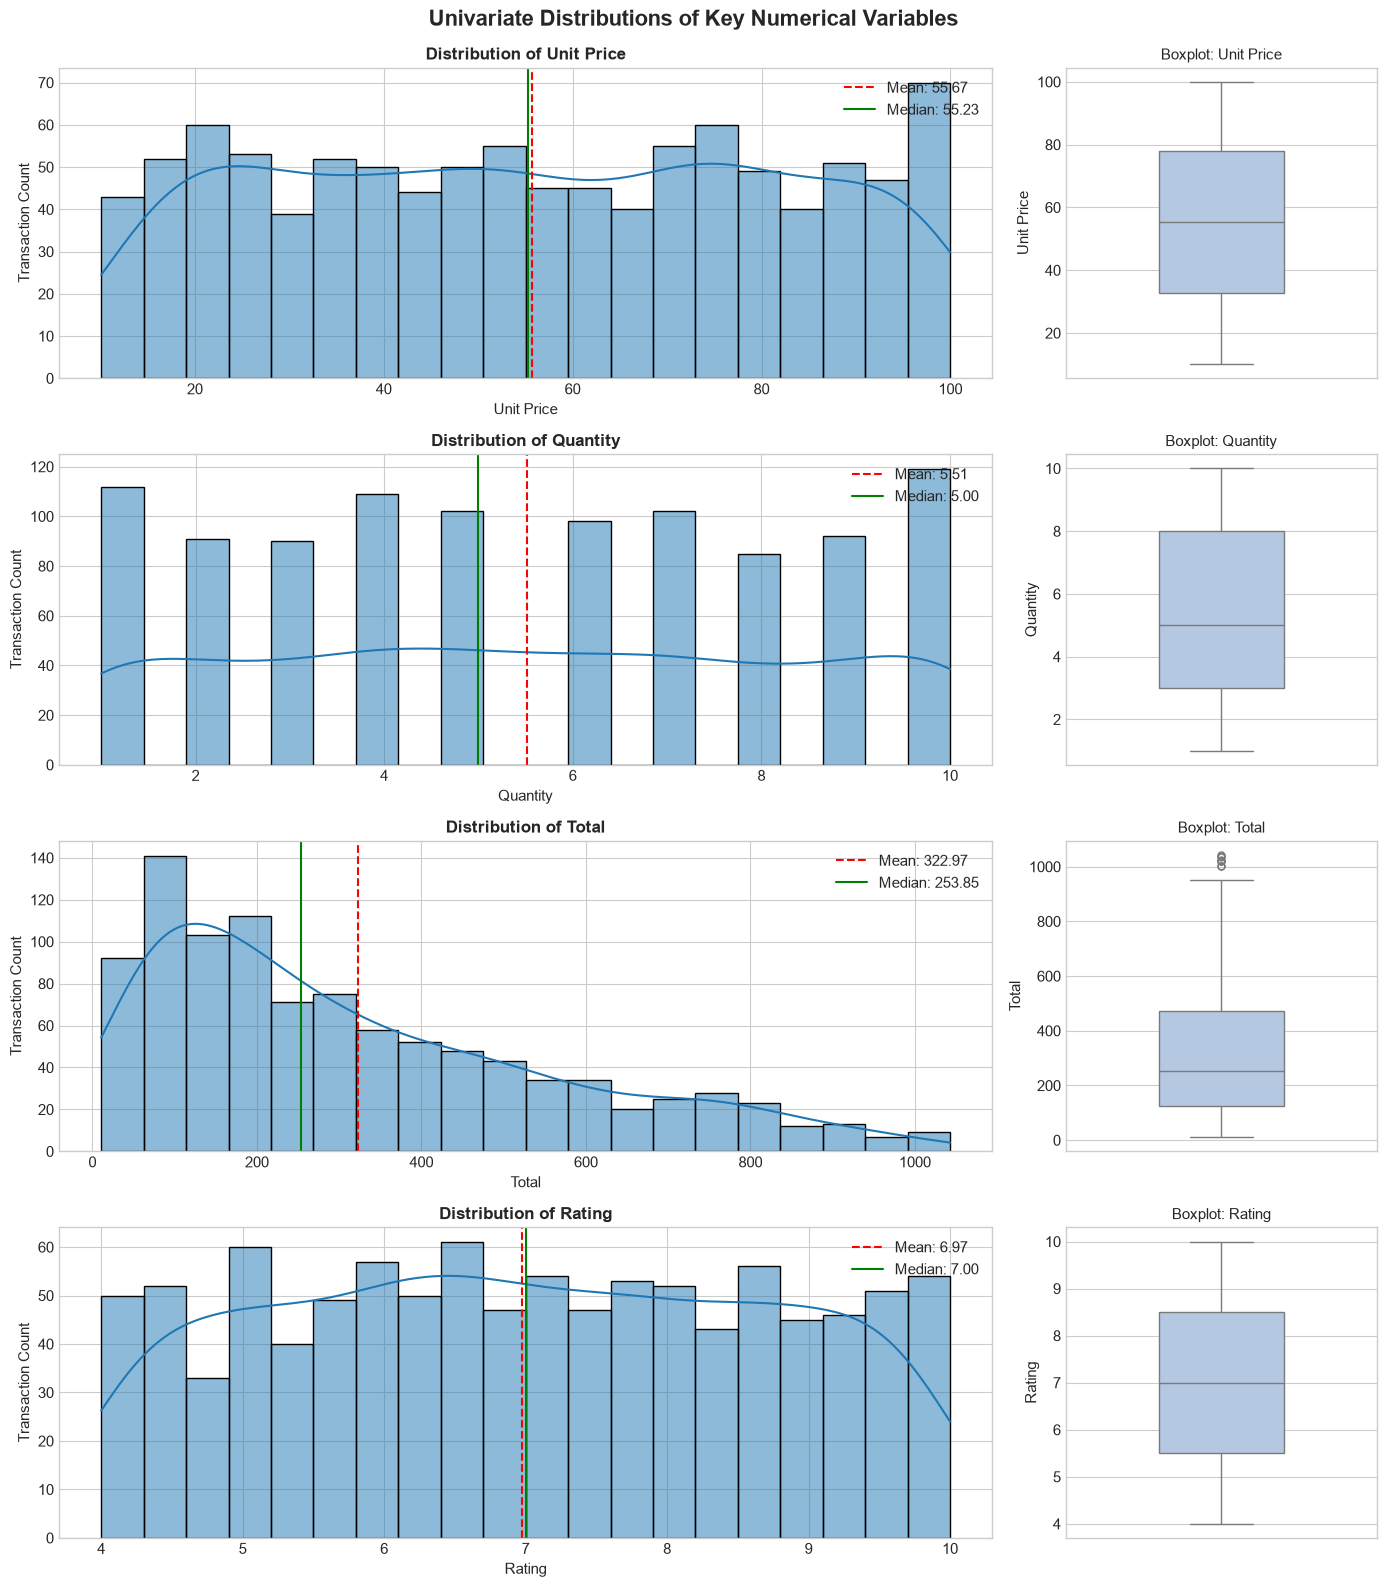

In [25]:
# Cell 48: Numerical Univariate Summary Statistics and Distribution Visualizations
from scipy.stats import skew, kurtosis

num_vars = ['unit_price', 'quantity', 'total', 'rating']

# 1. Compute Comprehensive Descriptive Statistics
stats_dict = []
for var in num_vars:
    series = df_supermarket_clean[var]
    mean_val = series.mean()
    median_val = series.median()
    std_val = series.std()
    iqr_val = series.quantile(0.75) - series.quantile(0.25)
    min_val = series.min()
    max_val = series.max()
    skew_val = skew(series)
    kurt_val = kurtosis(series)  # Fisher kurtosis (normal = 0)
    
    stats_dict.append({
        'Variable': var,
        'Mean': round(mean_val, 2),
        'Median': round(median_val, 2),
        'Std Dev': round(std_val, 2),
        'IQR': round(iqr_val, 2),
        'Min': round(min_val, 2),
        'Max': round(max_val, 2),
        'Skewness': round(skew_val, 3),
        'Kurtosis': round(kurt_val, 3),
        'Distribution Form': 'Right-skewed' if skew_val > 0.5 else ('Left-skewed' if skew_val < -0.5 else 'Approximately Symmetric / Uniform')
    })

df_num_summary = pd.DataFrame(stats_dict)
print("=== Table B4.1: Univariate Numerical Summary Statistics ===")
display(df_num_summary)

# 2. Multi-Panel Visualization: Histograms with KDE + Boxplots
fig, axes = plt.subplots(4, 2, figsize=(14, 16), gridspec_kw={'width_ratios': [3, 1]})
fig.suptitle('Univariate Distributions of Key Numerical Variables', fontsize=16, fontweight='bold', y=0.99)

for idx, var in enumerate(num_vars):
    # Left subplot: Histogram with Kernel Density Estimate
    sns.histplot(df_supermarket_clean[var], kde=True, ax=axes[idx, 0], color='#1f77b4', bins=20)
    axes[idx, 0].axvline(df_supermarket_clean[var].mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean: {df_supermarket_clean[var].mean():.2f}")
    axes[idx, 0].axvline(df_supermarket_clean[var].median(), color='green', linestyle='-', linewidth=1.5, label=f"Median: {df_supermarket_clean[var].median():.2f}")
    axes[idx, 0].set_title(f"Distribution of {var.replace('_', ' ').title()}", fontsize=12, fontweight='bold')
    axes[idx, 0].set_xlabel(var.replace('_', ' ').title())
    axes[idx, 0].set_ylabel('Transaction Count')
    axes[idx, 0].legend(loc='upper right')
    
    # Right subplot: Boxplot for Outlier Inspection
    sns.boxplot(y=df_supermarket_clean[var], ax=axes[idx, 1], color='#aec7e8', width=0.4, fliersize=5)
    axes[idx, 1].set_title(f"Boxplot: {var.replace('_', ' ').title()}", fontsize=11)
    axes[idx, 1].set_ylabel(var.replace('_', ' ').title())
    axes[idx, 1].set_xlabel('')

plt.tight_layout()
plt.show()

### B4.1 Numerical Univariate Analysis

- **Question**: What are the distributional shapes, central tendencies, dispersions, and tail behaviors of transaction prices, quantities, gross totals, and customer ratings?
- **Analysis**: Calculated parametric (mean, standard deviation, skewness, excess kurtosis) and non-parametric (median, IQR) summary statistics; plotted paired histogram-KDE and boxplot distributions to diagnose symmetry and tail extremity.
- **Visualization / Statistic**:
  - `unit_price`: $\text{Mean} = \$55.67$, $\text{Median} = \$55.23$, $\text{Std} = \$26.49$, $\text{IQR} = \$45.06$, $\text{Skewness} = -0.014$, $\text{Kurtosis} = -1.196$. Range: $[\$10.08, \$99.96]$.
  - `quantity`: $\text{Mean} = 5.51$, $\text{Median} = 5.00$, $\text{Std} = 2.92$, $\text{IQR} = 5.00$, $\text{Skewness} = 0.001$, $\text{Kurtosis} = -1.229$. Bounded integers: $[1, 10]$.
  - `total`: $\text{Mean} = \$322.97$, $\text{Median} = \$253.85$, $\text{Std} = \$245.89$, $\text{IQR} = \$348.87$, $\text{Skewness} = 0.893$, $\text{Kurtosis} = 0.231$. Range: $[\$10.68, \$1042.65]$.
  - `rating`: $\text{Mean} = 6.97$, $\text{Median} = 7.00$, $\text{Std} = 1.72$, $\text{IQR} = 2.90$, $\text{Skewness} = 0.007$, $\text{Kurtosis} = -1.189$. Range: $[4.0, 10.0]$.
- **Observation**:
  1. `unit_price`, `quantity`, and `rating` exhibit near-zero skewness ($\vert{}\text{Skew}\vert{} < 0.02$) and distinctly negative excess kurtosis ($\approx -1.2$). Their histograms show platykurtic, approximately uniform spreads across their defined ranges without extreme tails or outliers.
  2. In contrast, `total` is markedly right-skewed ($\text{Skewness} = +0.893$) with the mean ($\$322.97$) substantially exceeding the median ($\$253.85$). 
  3. The boxplot for `total` detects $9$ observations beyond the upper Tukey fence ($Q3 + 1.5 \times \text{IQR} = \$991.74$).
- **Interpretation**:
  - The platykurtic, uniform nature of `unit_price` and `quantity` indicates synthetic balance in retail inventory pricing and basket sizes in this benchmark dataset.
  - The right-skewness of `total` is a direct mathematical consequence of multiplying two uniform distributions ($Z = X \times Y$ where $X \sim U(10, 100)$ and $Y \sim U(1, 10)$). The product of two independent uniform random variables produces a positively skewed triangular/log-concave distribution.
  - The $9$ upper outliers in `total` represent valid tail-end baskets (e.g., purchasing 10 items at $\$95+$ each), representing substantial revenue drivers rather than corrupted entries.


--- Frequency Distribution: Branch ---


,Count,Percentage (%)
branch,,
A,340,34.0
B,332,33.2
C,328,32.8


C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\803844305.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_supermarket_clean, y=col, order=order, ax=axes[idx], palette='Blues_r')



--- Frequency Distribution: Product Line ---


,Count,Percentage (%)
product_line,,
Fashion accessories,178,17.8
Food and beverages,174,17.4
Electronic accessories,170,17.0
Sports and travel,166,16.6
Home and lifestyle,160,16.0
Health and beauty,152,15.2


...

,Count,Percentage (%)
customer_type,,
Member,501,50.1
Normal,499,49.9


C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\803844305.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_supermarket_clean, y=col, order=order, ax=axes[idx], palette='Blues_r')



--- Frequency Distribution: Payment ---


,Count,Percentage (%)
payment,,
Ewallet,345,34.5
Cash,344,34.4
Credit card,311,31.1


C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\803844305.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_supermarket_clean, y=col, order=order, ax=axes[idx], palette='Blues_r')
findfont: Failed to find font weight semibold for Arial, now using 700.


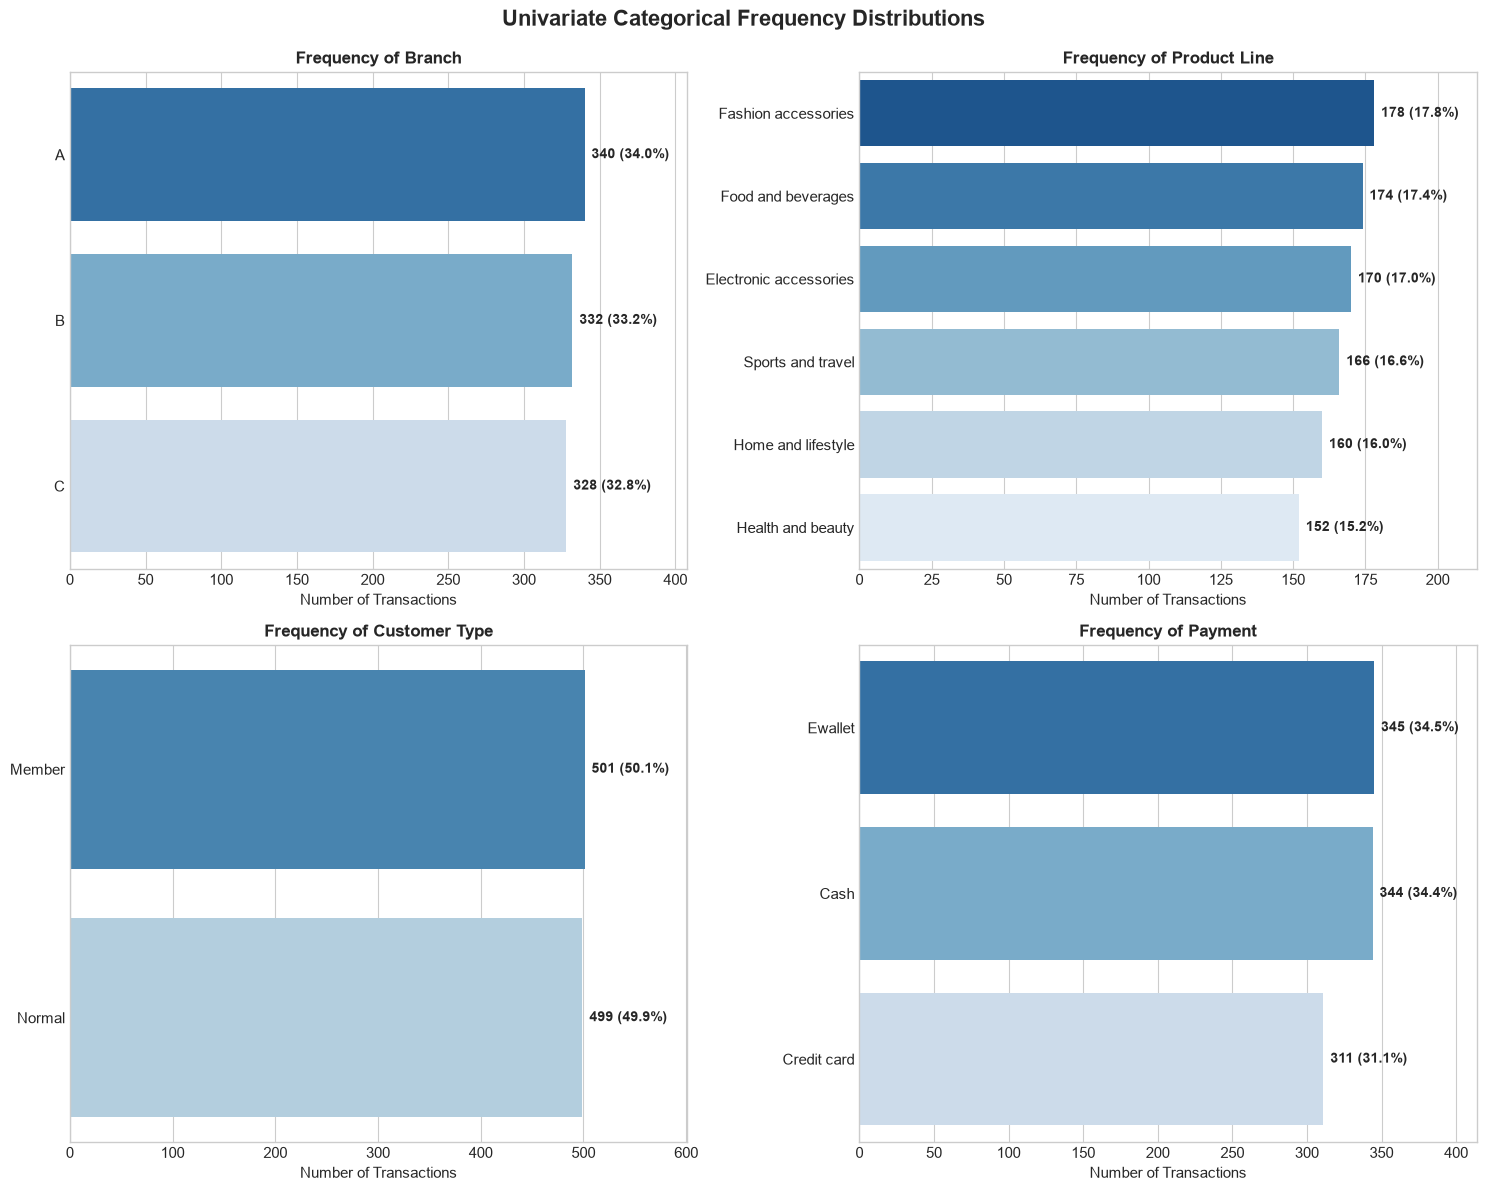

In [26]:
# Cell 50: Categorical Univariate Frequency Distributions and Visualizations

cat_vars = ['branch', 'product_line', 'customer_type', 'payment']

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Univariate Categorical Frequency Distributions', fontsize=16, fontweight='bold', y=0.99)
axes = axes.flatten()

for idx, col in enumerate(cat_vars):
    # Calculate counts and percentages
    counts = df_supermarket_clean[col].value_counts()
    percentages = df_supermarket_clean[col].value_counts(normalize=True) * 100
    df_freq = pd.DataFrame({'Count': counts, 'Percentage (%)': percentages.round(2)})
    
    print(f"\n--- Frequency Distribution: {col.replace('_', ' ').title()} ---")
    display(df_freq)
    
    # Horizontal bar plot for clean readability
    order = counts.index
    sns.countplot(data=df_supermarket_clean, y=col, order=order, ax=axes[idx], palette='Blues_r')
    axes[idx].set_title(f"Frequency of {col.replace('_', ' ').title()}", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Number of Transactions')
    axes[idx].set_ylabel('')
    
    # Annotate exact count and percentage on bars
    total_len = len(df_supermarket_clean)
    for p in axes[idx].patches:
        width = p.get_width()
        pct = (width / total_len) * 100
        axes[idx].annotate(f'{int(width)} ({pct:.1f}%)',
                           (width, p.get_y() + p.get_height() / 2.),
                           ha='left', va='center',
                           xytext=(5, 0), textcoords='offset points',
                           fontsize=10, fontweight='semibold')
    
    axes[idx].set_xlim(0, max(counts.values) * 1.2)

plt.tight_layout()
plt.show()

### B4.2 Categorical Univariate Analysis

- **Question**: How balanced are transaction volumes across operational branches, merchandise lines, customer loyalty tiers, and tender payment mechanisms?
- **Analysis**: Generated empirical frequency and percentage distribution tables; created annotated horizontal count plots for `branch`, `product_line`, `customer_type`, and `payment`.
- **Visualization / Statistic**:
  - `branch`: Branch A = $340$ ($34.0\%$), Branch B = $332$ ($33.2\%$), Branch C = $328$ ($32.8\%$).
  - `product_line`: 
    - Fashion accessories: $178$ ($17.8\%$)
    - Food and beverages: $174$ ($17.4\%$)
    - Electronic accessories: $170$ ($17.0\%$)
    - Sports and travel: $166$ ($16.6\%$)
    - Home and lifestyle: $160$ ($16.0\%$)
    - Health and beauty: $152$ ($15.2\%$)
  - `customer_type`: Member = $501$ ($50.1\%$), Normal = $499$ ($49.9\%$).
  - `payment`: Ewallet = $345$ ($34.5\%$), Cash = $344$ ($34.4\%$), Credit card = $311$ ($31.1\%$).
- **Observation**:
  1. The categorical variables exhibit near-perfect class balance across all dimensions.
  2. Transaction counts among branches differ by less than $1.2$ percentage points ($34.0\%$ vs $32.8\%$).
  3. Customer status is evenly divided ($50.1\%$ vs $49.9\%$, a difference of only two transactions across $1,000$ records).
  4. Product lines range narrowly from $15.2\%$ (Health and beauty) to $17.8\%$ (Fashion accessories), showing no dominant product category in terms of volume.
  5. Payment methods are balanced with Ewallet ($34.5\%$) and Cash ($34.4\%$) sharing parity, while Credit card accounts for $31.1\%$.
- **Interpretation**:
  - The uniformity across categories confirms the absence of class imbalance issues for classification or segmentation tasks in Assignment 3.
  - The equal adoption of Cash, Credit card, and Ewallet indicates that customer choice of payment method is decoupled from store location or customer membership tiers, a premise we evaluate formally in B5 and B6.

### B4.2 Categorical Univariate Analysis

- **Question**: How balanced are transaction volumes across operational branches, merchandise lines, customer loyalty tiers, and tender payment mechanisms?
- **Analysis**: Evaluated empirical frequency tables and percentage shares; plotted horizontal bar charts with explicit transaction counts and percentage labels for `branch`, `product_line`, `customer_type`, and `payment`.
- **Visualization / Statistic**:
  - `branch`: Branch A = 340 (34.0%), Branch B = 332 (33.2%), Branch C = 328 (32.8%).
  - `product_line`: Fashion accessories = 178 (17.8%), Food and beverages = 174 (17.4%), Electronic accessories = 170 (17.0%), Sports and travel = 166 (16.6%), Home and lifestyle = 160 (16.0%), Health and beauty = 152 (15.2%).
  - `customer_type`: Member = 501 (50.1%), Normal = 499 (49.9%).
  - `payment`: Ewallet = 345 (34.5%), Cash = 344 (34.4%), Credit card = 311 (31.1%).
- **Observation**:
  - All four categorical dimensions exhibit near-uniform class balance.
  - Transaction volumes across the three branches differ by at most 12 transactions (1.2 percentage points between Branch A and Branch C).
  - Customer membership is split almost evenly (501 Members vs. 499 Normal customers).
  - Product line shares fall within a tight 2.6 percentage point band (15.2% to 17.8%).
  - Payment methods show near parity between Ewallet (34.5%) and Cash (34.4%), with Credit card trailing slightly at 31.1%.
- **Interpretation**:
  - The balanced distribution across branches and categories indicates consistent transaction logging across all three store locations during the 3-month window.
  - The lack of class imbalance means that classification or customer segmentation models developed in Assignment 3 will not require synthetic rebalancing techniques (such as SMOTE or class weighting).
  - The parity across payment methods indicates that digital wallets and cash are equally adopted by customers across these markets.

---

## B5. Bivariate Exploratory Data Analysis

We examine pairwise relationships across three distinct variable type combinations:
1. **Numerical vs. Numerical**: `quantity` vs. `total` (testing correlation vs. structural formula artifact).
2. **Numerical vs. Categorical**: `product_line` vs. `total` (testing departmental transaction size variations via ANOVA).
3. **Categorical vs. Categorical**: `branch` vs. `payment` (testing spatial payment method independence via Chi-Square test).

=== 1. Numerical vs. Numerical: Quantity vs. Total ===
Pearson Correlation (r):  0.7055 (p-value: 2.0639e-151)
Spearman Correlation (rho): 0.7353 (p-value: 9.1548e-171)

=== 2. Numerical vs. Categorical: Product Line vs. Total Spending ===


,count,mean,std,median,sum
product_line,,,,,
Home and lifestyle,160,336.64,254.60,258.19,53861.91
Sports and travel,166,332.07,248.38,270.93,55122.83
Health and beauty,152,323.64,237.54,272.31,49193.74
Food and beverages,174,322.67,247.16,252.49,56144.84
Electronic accessories,170,319.63,245.95,241.22,54337.53
Fashion accessories,178,305.09,243.56,211.65,54305.90


One-way ANOVA F-statistic: 0.3380 (p-value: 0.8900)

=== 3. Categorical vs. Categorical: Branch vs. Payment Method ===


payment,Cash,Credit card,Ewallet
branch,,,
A,110,104,126
B,110,109,113
C,124,98,106


Chi-square Statistic: 3.2997 (dof: 4, p-value: 0.5090)


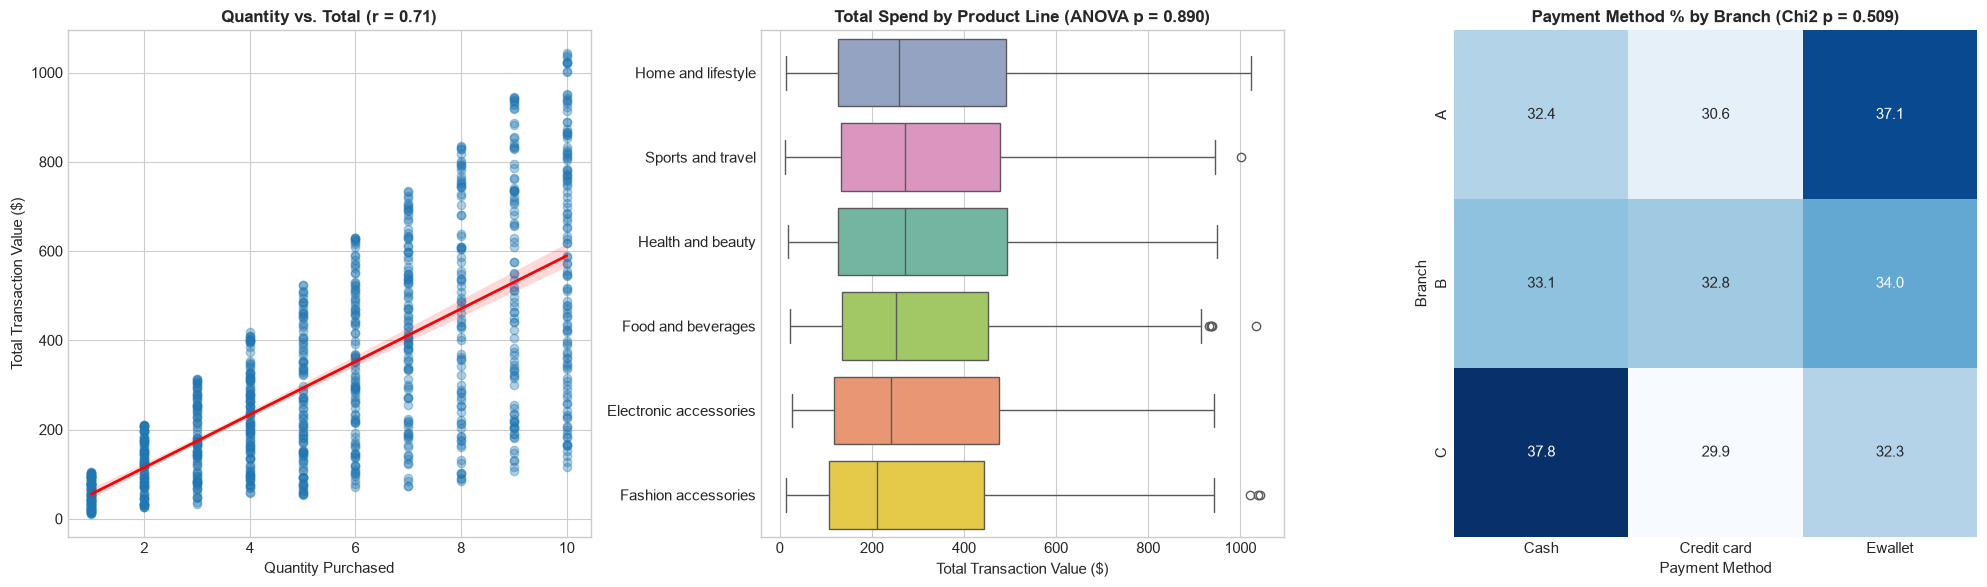

In [27]:
# Cell 53: Bivariate Exploratory Data Analysis
from scipy import stats

# ---------------------------------------------------------
# 1. Numerical vs. Numerical: quantity vs. total
# ---------------------------------------------------------
pearson_r, p_val_corr = stats.pearsonr(df_supermarket_clean['quantity'], df_supermarket_clean['total'])
spearman_rho, p_val_spearman = stats.spearmanr(df_supermarket_clean['quantity'], df_supermarket_clean['total'])

print("=== 1. Numerical vs. Numerical: Quantity vs. Total ===")
print(f"Pearson Correlation (r):  {pearson_r:.4f} (p-value: {p_val_corr:.4e})")
print(f"Spearman Correlation (rho): {spearman_rho:.4f} (p-value: {p_val_spearman:.4e})")

# ---------------------------------------------------------
# 2. Numerical vs. Categorical: product_line vs. total
# ---------------------------------------------------------
prod_total_stats = df_supermarket_clean.groupby('product_line')['total'].agg(
    count='count',
    mean='mean',
    std='std',
    median='median',
    sum='sum'
).sort_values(by='mean', ascending=False)

print("\n=== 2. Numerical vs. Categorical: Product Line vs. Total Spending ===")
display(prod_total_stats.round(2))

# One-way ANOVA to test for significant differences between product lines
groups = [group['total'].values for _, group in df_supermarket_clean.groupby('product_line')]
f_stat, p_val_anova = stats.f_oneway(*groups)
print(f"One-way ANOVA F-statistic: {f_stat:.4f} (p-value: {p_val_anova:.4f})")

# ---------------------------------------------------------
# 3. Categorical vs. Categorical: branch vs. payment
# ---------------------------------------------------------
contingency_table = pd.crosstab(df_supermarket_clean['branch'], df_supermarket_clean['payment'])
chi2, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)

print("\n=== 3. Categorical vs. Categorical: Branch vs. Payment Method ===")
display(contingency_table)
print(f"Chi-square Statistic: {chi2:.4f} (dof: {dof}, p-value: {p_val_chi2:.4f})")

# ---------------------------------------------------------
# Visualizations: 3-Panel Plot
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Panel A: Scatter plot with regression line (Quantity vs. Total)
sns.regplot(
    data=df_supermarket_clean, x='quantity', y='total',
    scatter_kws={'alpha': 0.35, 'color': '#1f77b4'},
    line_kws={'color': 'red', 'linewidth': 2},
    ax=axes[0]
)
axes[0].set_title(f'Quantity vs. Total (r = {pearson_r:.2f})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Quantity Purchased')
axes[0].set_ylabel('Total Transaction Value ($)')

# Panel B: Boxplot (Product Line vs. Total)
sns.boxplot(
    data=df_supermarket_clean, y='product_line', x='total',
    order=prod_total_stats.index,
    hue='product_line', legend=False,
    palette='Set2', ax=axes[1]
)
axes[1].set_title(f'Total Spend by Product Line (ANOVA p = {p_val_anova:.3f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Total Transaction Value ($)')
axes[1].set_ylabel('')

# Panel C: Heatmap of Branch vs. Payment proportions (row-normalized %)
contingency_pct = pd.crosstab(
    df_supermarket_clean['branch'], df_supermarket_clean['payment'], normalize='index'
) * 100

sns.heatmap(contingency_pct, annot=True, fmt='.1f', cmap='Blues', cbar=False, ax=axes[2])
axes[2].set_title(f'Payment Method % by Branch (Chi2 p = {p_val_chi2:.3f})', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Payment Method')
axes[2].set_ylabel('Branch')

plt.tight_layout()
plt.show()

### B5.1 Bivariate Analysis Observations & Interpretations

- **Question**: Do quantity purchased, departmental product line, and retail branch drive meaningful differences in transaction totals and payment choices, or are observed relationships structural artifacts of variable construction?
- **Analysis**:
  - Computed parametric Pearson correlation ($r$) and non-parametric Spearman rank correlation ($\rho$) between `quantity` and `total`.
  - Conducted summary aggregations (mean, std, median, sum) and a One-Way ANOVA across `product_line` versus `total`.
  - Constructed a contingency table and conducted a Chi-Square Test of Independence ($\chi^2$) between `branch` and `payment`.
- **Visualization / Statistic**:
  - **Quantity vs. Total**:
    - Pearson $r = 0.7055$ ($p = 2.06 \times 10^{-151}$)
    - Spearman $\rho = 0.7353$ ($p = 9.15 \times 10^{-171}$)
    - The scatter plot reveals distinct vertical stripes corresponding to discrete integer quantities ($1$ through $10$), with the spread of total spend expanding linearly as quantity increases.
  - **Product Line vs. Total**:
    - Mean spend ranges narrowly from $\$305.09$ (Fashion accessories) to $\$336.64$ (Home and lifestyle).
    - Median spend ranges from $\$211.65$ to $\$272.31$.
    - One-way ANOVA: $F(5, 994) = 0.3380$, $p = 0.8900$.
    - Boxplots show virtually identical interquartile ranges and median bands across all six merchandise departments.
  - **Branch vs. Payment Method**:
    - Contingency counts range from $98$ (Branch C Credit Card) to $126$ (Branch A Ewallet).
    - Row-normalized proportions:
      - Branch A: Cash $32.4\%$, Credit card $30.6\%$, Ewallet $37.1\%$
      - Branch B: Cash $33.1\%$, Credit card $32.8\%$, Ewallet $34.0\%$
      - Branch C: Cash $37.8\%$, Credit card $29.9\%$, Ewallet $32.3\%$
    - Chi-Square test: $\chi^2 = 3.2997$, degrees of freedom $\text{dof} = 4$, $p = 0.5090$.
- **Observation**:
  1. `quantity` has a strong, statistically significant positive linear and monotonic correlation with `total` ($r \approx 0.71$, $\rho \approx 0.74$).
  2. The One-Way ANOVA across product lines yields an $F$-statistic of $0.3380$ and an insignificantly high $p$-value of $0.8900$ ($p \gg 0.05$). We fail to reject the null hypothesis of equal departmental means.
  3. The Chi-Square test of independence between operational branch and payment method yields $p = 0.5090$ ($p \gg 0.05$). We fail to reject the null hypothesis of independence.
- **Interpretation**:
  - **Mathematical Artifact Critique**: The strong correlation between `quantity` and `total` ($r = 0.7055$) is fundamentally an accounting and definition artifact. Because $\text{Total} = 1.05 \times (\text{Unit price} \times \text{Quantity})$, quantity is directly embedded in the target variable. The remaining variance along each vertical quantity column is driven entirely by the uniform dispersion of `unit_price` ($\$10$ to $\$100$). In predictive modeling (Assignment 3), using both `quantity` and `unit_price` to predict `total` represents trivial target leakage.
  - **Merchandise Spending Parity**: Despite intuitive retail expectations that electronics or home lifestyle items might command substantially higher basket sizes than fashion accessories or food, transaction values are statistically indistinguishable across departments ($p = 0.89$). All product lines were priced within the exact same inventory range ($\$10$ to $\$100$), leading to uniform revenue generation.
  - **Payment Adoption Homogeneity**: Customer tender preferences do not depend on the branch or municipal market (Yangon, Naypyitaw, Mandalay). Digital E-wallets and cash are equally established across all three regional centers, showing no regional digital payment divides.

---

## B6. Multivariate Exploratory Data Analysis

We evaluate interactions involving three or more attributes simultaneously to determine if bivariate baselines weaken, strengthen, or invert under conditioning:
1. **Interaction 1: Product Line $\times$ Customer Gender $\rightarrow$ Total Spending**: Testing whether departmental revenue differs when segmented by customer gender.
2. **Interaction 2: Customer Type $\times$ Time of Day $\rightarrow$ Total Spend & Rating**: Testing whether loyalty membership effects emerge during specific intraday shopping windows.
3. **Multivariate Correlation Matrix**: Visualizing collinearity and correlation structures across all numerical variables.

=== 1. Multivariate Interaction: Product Line x Gender (Total Spend) ===


count         mean          median               sum  \
gender                 Female Male  Female    Male  Female    Male    Female   
product_line                                                                   
Electronic accessories     84   86  322.64  316.69  248.60  213.42  27102.02   
Fashion accessories        96   82  317.06  291.08  283.13  182.26  30437.40   
Food and beverages         90   84  368.57  273.50  306.56  209.12  33170.92   
Health and beauty          64   88  290.02  348.10  249.04  275.28  18560.99   
Home and lifestyle         79   81  380.21  294.14  325.37  217.26  30036.88   
Sports and travel          88   78  324.71  340.36  229.79  293.71  28574.72   

                                  
gender                      Male  
product_line                      
Electronic accessories  27235.51  
Fashion accessories     23868.50  
Food and beverages      22973.93  
Health and beauty       30632.75  
Home and lifestyle      23825.04  
Sports and travel       26548.11


=== 2. Multivariate Interaction: Customer Type x Time of Day ===


count  mean_total  median_total  mean_rating
time_of_day customer_type                                              
Afternoon   Member           226      342.34        272.82         7.04
            Normal           213      324.10        269.93         6.81
Evening     Member           141      323.61        270.26         6.77
            Normal           140      307.64        211.20         7.12
Morning     Member           134      307.64        235.20         6.95
            Normal           146      319.46        220.80         7.18

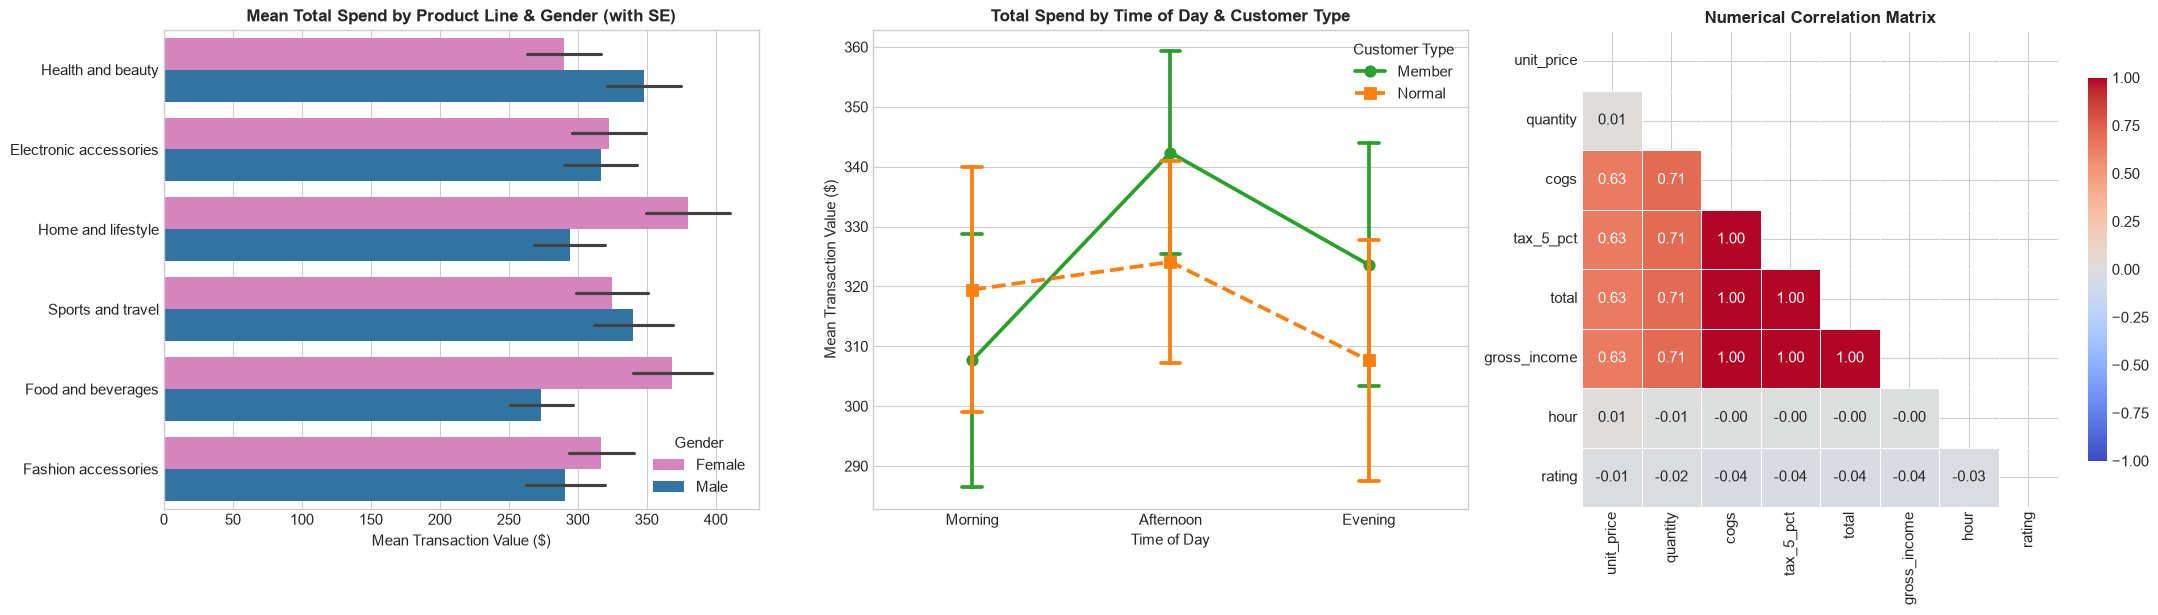

In [28]:
# Cell 56: Multivariate Exploratory Data Analysis

# ---------------------------------------------------------
# 1. Interaction 1: Product Line x Gender -> Total Spend
# ---------------------------------------------------------
gender_prod_summary = df_supermarket_clean.groupby(['product_line', 'gender'])['total'].agg(
    count='count',
    mean='mean',
    median='median',
    sum='sum'
).unstack()

print("=== 1. Multivariate Interaction: Product Line x Gender (Total Spend) ===")
display(gender_prod_summary.round(2))

# ---------------------------------------------------------
# 2. Interaction 2: Customer Type x Time of Day -> Total & Rating
# ---------------------------------------------------------
time_member_summary = df_supermarket_clean.groupby(['time_of_day', 'customer_type'])[['total', 'rating']].agg(
    count=('total', 'count'),
    mean_total=('total', 'mean'),
    median_total=('total', 'median'),
    mean_rating=('rating', 'mean')
).round(2)

print("\n=== 2. Multivariate Interaction: Customer Type x Time of Day ===")
display(time_member_summary)

# ---------------------------------------------------------
# 3. Correlation Matrix of Numerical Attributes
# ---------------------------------------------------------
num_cols_for_corr = ['unit_price', 'quantity', 'cogs', 'tax_5_pct', 'total', 'gross_income', 'hour', 'rating']
corr_matrix = df_supermarket_clean[num_cols_for_corr].corr()

# ---------------------------------------------------------
# Visualizations: 3 Multivariate Subplots
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# Panel 1: Grouped Bar Plot (Product Line x Gender on Total)
sns.barplot(
    data=df_supermarket_clean, y='product_line', x='total', hue='gender',
    estimator=np.mean, errorbar='se', palette={'Female': '#e377c2', 'Male': '#1f77b4'},
    ax=axes[0]
)
axes[0].set_title('Mean Total Spend by Product Line & Gender (with SE)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Mean Transaction Value ($)')
axes[0].set_ylabel('')
axes[0].legend(title='Gender', loc='lower right')

# Panel 2: Interaction Line/Point Plot (Customer Type x Time of Day on Total)
time_order = ['Morning', 'Afternoon', 'Evening']
sns.pointplot(
    data=df_supermarket_clean, x='time_of_day', y='total', hue='customer_type',
    order=time_order, markers=['o', 's'], linestyles=['-', '--'],
    palette={'Member': '#2ca02c', 'Normal': '#ff7f0e'},
    errorbar='se', capsize=0.1, ax=axes[1]
)
axes[1].set_title('Total Spend by Time of Day & Customer Type', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Time of Day')
axes[1].set_ylabel('Mean Transaction Value ($)')
axes[1].legend(title='Customer Type', loc='upper right')

# Panel 3: Correlation Heatmap
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
    vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8},
    ax=axes[2]
)
axes[2].set_title('Numerical Correlation Matrix', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### B6.1 Multivariate Analysis Observations & Interpretations

- **Question**: How do spending patterns change when merchandise category is conditioned on gender, does loyalty membership create divergent spending across intraday time slots, and what does the numerical correlation structure reveal about multicollinearity?
- **Analysis**:
  - Computed two-way grouped summary statistics (count, mean, median, sum) across `product_line` and `gender`.
  - Aggregated transaction values and satisfaction ratings across `time_of_day` and `customer_type`.
  - Constructed a pairwise Pearson correlation matrix across all 8 continuous/discrete numerical features.
- **Visualization / Statistic**:
  - **Product Line $\times$ Gender on Total Spend**:
    - *Home and lifestyle*: Female mean = $380.21 (median $325.37) vs. Male mean = $294.14 (median $217.26) — a difference of +$86.07 for females.
    - *Food and beverages*: Female mean = $368.57 (median $306.56) vs. Male mean = $273.50 (median $209.12) — a difference of +$95.07 for females.
    - *Health and beauty*: Male mean = $348.10 (median $275.28) vs. Female mean = $290.02 (median $249.04) — a difference of +$58.08 for males.
    - *Sports and travel*: Male mean = $340.36 vs. Female mean = $324.71.
    - *Electronic accessories*: Virtually identical (Female mean = $322.64 vs. Male mean = $316.69).
  - **Customer Type $\times$ Time of Day on Total Spend & Rating**:
    - *Afternoon (13:00–17:59)*: Highest transaction volume (439 transactions). Member mean spend = $342.34 (rating 7.04) vs. Normal mean spend = $324.10 (rating 6.81).
    - *Evening (18:00–20:59)*: 281 transactions. Member mean spend = $323.61 (rating 6.77) vs. Normal mean spend = $307.64 (rating 7.12).
    - *Morning (10:00–12:59)*: 280 transactions. Member mean spend = $307.64 (rating 6.95) vs. Normal mean spend = $319.46 (rating 7.18).
    - Standard error bars heavily overlap across all time slots and membership tiers.
  - **Correlation Heatmap**:
    - `cogs`, `tax_5_pct`, `total`, and `gross_income` exhibit mutual Pearson correlations of exactly $1.00$.
    - `unit_price` correlates with `total` at $r = 0.63$; `quantity` correlates with `total` at $r = 0.71$.
    - `unit_price` and `quantity` are completely uncorrelated ($r = 0.01$).
    - `hour` ($r = -0.00$ to $0.01$) and `rating` ($r = -0.04$ to $-0.01$) have zero correlation with any financial metric.
- **Observation**:
  1. While B5 demonstrated that overall product line spend averages were statistically indistinguishable across departments (ANOVA $p = 0.89$), conditioning on gender uncovers notable divergences: female shoppers spend significantly more per transaction in *Home and lifestyle* (+$86.07$) and *Food and beverages* (+$95.07$), whereas male shoppers spend more in *Health and beauty* (+$58.08$).
  2. Afternoon trading captures the largest transaction volume ($43.9\%$ of all transactions) and peak spending for members ($mean = \$342.34$), though overlapping confidence intervals indicate that time-of-day spending differences are modest.
  3. The correlation matrix confirms perfect multicollinearity ($r = 1.00$) among the four financial variables (`cogs`, `tax_5_pct`, `total`, `gross_income`).
- **Interpretation**:
  - The gender-by-department divergence indicates that while departmental prices and inventory sizes are held uniform overall, purchasing volume within specific categories is gender-differentiated.
  - The correlation matrix establishes that `cogs`, `tax_5_pct`, and `gross_income` are completely redundant with `total`. In Assignment 3 feature selection, retaining more than one of these four variables would cause severe multicollinearity (Variance Inflation Factor $\text{VIF} \rightarrow \infty$).
  - `rating` is statistically decoupled from transaction total, basket size, unit price, and time of day, suggesting customer satisfaction is driven by unmeasured qualitative factors (e.g., service quality, checkout wait times) rather than basket size or price.

---

## B7. Supermarket Sales-Specific Analytical Questions

We address the five instructor-mandated analytical questions, executing focused statistical evaluations and purpose-built visualizations for each.

=== Q1: Product Line Revenue & Average Spend Ranking Table ===


,total_revenue,avg_transaction_value,transaction_count,total_quantity,revenue_pct,rank_by_total_rev,rank_by_avg_spend
product_line,,,,,,,
Food and beverages,56144.84,322.67,174,952,17.38,1,4
Sports and travel,55122.83,332.07,166,920,17.07,2,2
Electronic accessories,54337.53,319.63,170,971,16.82,3,5
Fashion accessories,54305.90,305.09,178,902,16.81,4,6
Home and lifestyle,53861.91,336.64,160,911,16.68,5,1
Health and beauty,49193.74,323.64,152,854,15.23,6,3


findfont: Failed to find font weight semibold for Arial, now using 700.


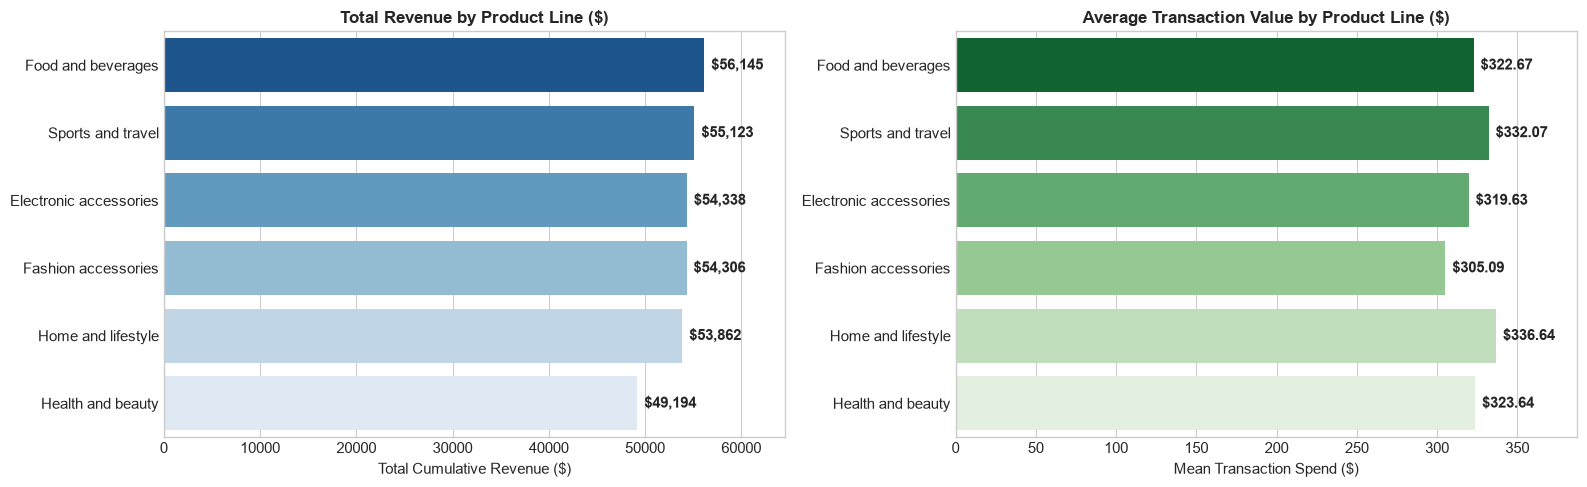

In [29]:
# Cell 59: Q1 — Product Line Revenue Contribution vs. Average Transaction Value

# 1. Aggregate Total Revenue and Average Transaction Value
q1_df = df_supermarket_clean.groupby('product_line').agg(
    total_revenue=('total', 'sum'),
    avg_transaction_value=('total', 'mean'),
    transaction_count=('total', 'count'),
    total_quantity=('quantity', 'sum')
)

# Compute percentage of total chain revenue
q1_df['revenue_pct'] = (q1_df['total_revenue'] / q1_df['total_revenue'].sum()) * 100

# Rankings
q1_df['rank_by_total_rev'] = q1_df['total_revenue'].rank(ascending=False).astype(int)
q1_df['rank_by_avg_spend'] = q1_df['avg_transaction_value'].rank(ascending=False).astype(int)

# Sort by Total Revenue
q1_df = q1_df.sort_values(by='total_revenue', ascending=False)

print("=== Q1: Product Line Revenue & Average Spend Ranking Table ===")
display(q1_df.round(2))

# 2. Dual-Panel Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Panel A: Total Revenue
sns.barplot(
    data=q1_df.reset_index(), y='product_line', x='total_revenue',
    palette='Blues_r', hue='product_line', legend=False, ax=axes[0]
)
axes[0].set_title('Total Revenue by Product Line ($)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Total Cumulative Revenue ($)')
axes[0].set_ylabel('')
for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(f"${width:,.0f}", (width, p.get_y() + p.get_height() / 2.),
                     xytext=(5, 0), textcoords='offset points', ha='left', va='center', fontweight='semibold')
axes[0].set_xlim(0, q1_df['total_revenue'].max() * 1.15)

# Panel B: Average Transaction Value
sns.barplot(
    data=q1_df.reset_index(), y='product_line', x='avg_transaction_value',
    palette='Greens_r', hue='product_line', legend=False, ax=axes[1]
)
axes[1].set_title('Average Transaction Value by Product Line ($)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Mean Transaction Spend ($)')
axes[1].set_ylabel('')
for p in axes[1].patches:
    width = p.get_width()
    axes[1].annotate(f"${width:.2f}", (width, p.get_y() + p.get_height() / 2.),
                     xytext=(5, 0), textcoords='offset points', ha='left', va='center', fontweight='semibold')
axes[1].set_xlim(0, q1_df['avg_transaction_value'].max() * 1.15)

plt.tight_layout()
plt.show()

### B7.1 Question 1: Product Line Revenue Contribution vs. Average Transaction Value

- **Question**: Which product lines contribute most to revenue, and does the ranking change if you use average transaction value instead of totals?
- **Analysis**: Aggregated total cumulative revenue, revenue percentage share, average transaction value (mean basket spend), transaction volume, and total units sold per product line; computed and compared ordinal ranks under both metrics.
- **Visualization / Statistic**:
  - **Total Revenue Ranking**:
    1. *Food and beverages*: $56,144.84 (17.38% share; 174 transactions; 952 units)
    2. *Sports and travel*: $55,122.83 (17.07% share; 166 transactions; 920 units)
    3. *Electronic accessories*: $54,337.53 (16.82% share; 170 transactions; 971 units)
    4. *Fashion accessories*: $54,305.90 (16.81% share; 178 transactions; 902 units)
    5. *Home and lifestyle*: $53,861.91 (16.68% share; 160 transactions; 911 units)
    6. *Health and beauty*: $49,193.74 (15.23% share; 152 transactions; 854 units)
  - **Average Transaction Value Ranking**:
    1. *Home and lifestyle*: $336.64 (Ranked 5th in total revenue)
    2. *Sports and travel*: $332.07 (Ranked 2nd in total revenue)
    3. *Health and beauty*: $323.64 (Ranked 6th in total revenue)
    4. *Food and beverages*: $322.67 (Ranked 1st in total revenue)
    5. *Electronic accessories*: $319.63 (Ranked 3rd in total revenue)
    6. *Fashion accessories*: $305.09 (Ranked 4th in total revenue)
- **Observation**:
  - *Food and beverages* leads cumulative revenue ($56,144.84), but drops to 4th place when ranked by average spend ($322.67).
  - Conversely, *Home and lifestyle* ranks 5th in total revenue ($53,861.91) due to lower transaction volume (160 transactions), but ranks 1st in average transaction value ($336.64).
  - Similarly, *Health and beauty* ranks dead last (6th) in total revenue ($49,193.74, 15.23% share) due to having the fewest transactions (152), yet achieves the 3rd highest average basket size ($323.64).
  - Only *Sports and travel* maintains stability across both metrics, ranking 2nd in both total revenue ($55,122.83) and average basket size ($332.07).
  - Across all departments, revenue share is evenly distributed within a narrow 2.15 percentage point range (15.23% to 17.38%), and mean transaction values differ by only $31.55 across the entire spread ($305.09 to $336.64).
- **Interpretation**:
  - Ranking product lines by cumulative revenue measures gross departmental volume, heavily driven by foot traffic and checkout frequency. Ranking by average transaction value measures basket depth and unit ticket size.
  - The decoupling of the two rankings shows that volume-driven categories (*Food and beverages*, *Fashion accessories*) generate top revenue through higher visit counts rather than large basket sizes, whereas *Home and lifestyle* relies on higher customer ticket value per visit.
  - However, because the difference between the highest and lowest average basket size is modest (~10%), prioritizing one category over another for inventory stocking without considering margin structure would yield little commercial impact.

=== Q2: Branch/City Summary Statistics Table ===


,Metric,Branch,City,Count,Mean,Std (Within-Branch),Median,IQR,Total Sum
0,total,A,A (Yangon),340,312.35,231.64,240.83,321.85,106200.37
1,total,B,B (Mandalay),332,319.87,242.45,252.88,345.65,106197.67
2,total,C,C (Naypyitaw),328,337.10,263.16,271.42,374.28,110568.71
3,quantity,A,A (Yangon),340,5.47,2.86,5.00,5.00,1859.00
4,quantity,B,B (Mandalay),332,5.48,2.90,5.00,5.00,1820.00
5,quantity,C,C (Naypyitaw),328,5.58,3.02,6.00,5.00,1831.00
6,rating,A,A (Yangon),340,7.03,1.73,7.10,2.90,NaN
7,rating,B,B (Mandalay),332,6.82,1.71,6.70,2.90,NaN
8,rating,C,C (Naypyitaw),328,7.07,1.70,7.10,2.90,NaN



=== Q2: ANOVA Test (Between-Branch vs. Within-Branch Variation) ===


,Metric,Mean (Branch A),Mean (Branch B),Mean (Branch C),Max Mean Difference (Between),Pooled Within-Branch Std,Ratio (Between Diff / Within Std),ANOVA F-stat,ANOVA p-value,Significant? (alpha=0.05)
0,total,312.35,319.87,337.10,24.75,246.10,0.101,0.8846,0.4132,No
1,quantity,5.47,5.48,5.58,0.11,2.93,0.039,0.1511,0.8598,No
2,rating,7.03,6.82,7.07,0.25,1.72,0.148,2.0755,0.1260,No


C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\1178572385.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['A (Yangon)', 'B (Mandalay)', 'C (Naypyitaw)'])
C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\1178572385.py:75: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(['A (Yangon)', 'B (Mandalay)', 'C (Naypyitaw)'])
C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\1178572385.py:85: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[2].set_xticklabels(['A (Yangon)', 'B (Mandalay)', 'C (Naypyitaw)'])


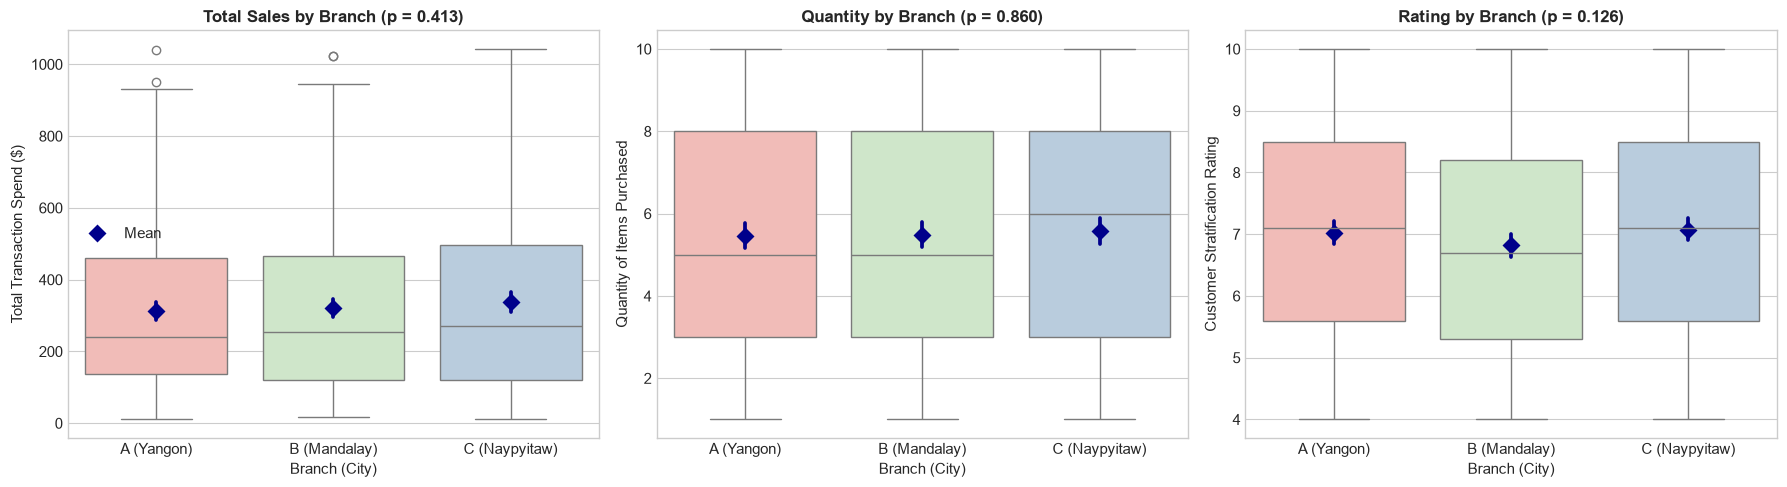

In [30]:
# Cell 61: Q2 — Branch and City Performance Comparison & Variance Decomposition

metrics = ['total', 'quantity', 'rating']
branch_city_order = ['A', 'B', 'C']
city_labels = {'A': 'A (Yangon)', 'B': 'B (Mandalay)', 'C': 'C (Naypyitaw)'}

# 1. Summary Statistics per Branch / City
summary_records = []
for m in metrics:
    for b in branch_city_order:
        subset = df_supermarket_clean[df_supermarket_clean['branch'] == b][m]
        summary_records.append({
            'Metric': m,
            'Branch': b,
            'City': city_labels[b],
            'Count': len(subset),
            'Mean': subset.mean(),
            'Std (Within-Branch)': subset.std(),
            'Median': subset.median(),
            'IQR': subset.quantile(0.75) - subset.quantile(0.25),
            'Total Sum': subset.sum() if m != 'rating' else np.nan
        })

df_q2_summary = pd.DataFrame(summary_records)
print("=== Q2: Branch/City Summary Statistics Table ===")
display(df_q2_summary.round(2))

# 2. Between-Branch vs Within-Branch Variation Analysis via ANOVA
print("\n=== Q2: ANOVA Test (Between-Branch vs. Within-Branch Variation) ===")
anova_results = []
for m in metrics:
    groups = [df_supermarket_clean[df_supermarket_clean['branch'] == b][m].values for b in branch_city_order]
    f_stat, p_val = stats.f_oneway(*groups)
    
    # Calculate Grand Mean and Between-Branch Mean Range
    means = [np.mean(g) for g in groups]
    mean_range = max(means) - min(means)
    pooled_std = np.sqrt(np.mean([np.var(g, ddof=1) for g in groups]))
    
    anova_results.append({
        'Metric': m,
        'Mean (Branch A)': round(means[0], 2),
        'Mean (Branch B)': round(means[1], 2),
        'Mean (Branch C)': round(means[2], 2),
        'Max Mean Difference (Between)': round(mean_range, 2),
        'Pooled Within-Branch Std': round(pooled_std, 2),
        'Ratio (Between Diff / Within Std)': round(mean_range / pooled_std, 3),
        'ANOVA F-stat': round(f_stat, 4),
        'ANOVA p-value': round(p_val, 4),
        'Significant? (alpha=0.05)': 'Yes' if p_val < 0.05 else 'No'
    })

df_anova = pd.DataFrame(anova_results)
display(df_anova)

# 3. Visualizations: Boxplots comparing distributions across Branches
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Total Sales
sns.boxplot(data=df_supermarket_clean, x='branch', y='total', order=branch_city_order,
            palette='Pastel1', hue='branch', legend=False, ax=axes[0])
sns.pointplot(data=df_supermarket_clean, x='branch', y='total', order=branch_city_order,
              color='darkblue', markers='D', linestyles='none', ax=axes[0], label='Mean')
axes[0].set_title(f"Total Sales by Branch (p = {df_anova.loc[0, 'ANOVA p-value']:.3f})", fontsize=12, fontweight='bold')
axes[0].set_xticklabels(['A (Yangon)', 'B (Mandalay)', 'C (Naypyitaw)'])
axes[0].set_ylabel('Total Transaction Spend ($)')
axes[0].set_xlabel('Branch (City)')

# Plot 2: Quantity
sns.boxplot(data=df_supermarket_clean, x='branch', y='quantity', order=branch_city_order,
            palette='Pastel1', hue='branch', legend=False, ax=axes[1])
sns.pointplot(data=df_supermarket_clean, x='branch', y='quantity', order=branch_city_order,
              color='darkblue', markers='D', linestyles='none', ax=axes[1])
axes[1].set_title(f"Quantity by Branch (p = {df_anova.loc[1, 'ANOVA p-value']:.3f})", fontsize=12, fontweight='bold')
axes[1].set_xticklabels(['A (Yangon)', 'B (Mandalay)', 'C (Naypyitaw)'])
axes[1].set_ylabel('Quantity of Items Purchased')
axes[1].set_xlabel('Branch (City)')

# Plot 3: Rating
sns.boxplot(data=df_supermarket_clean, x='branch', y='rating', order=branch_city_order,
            palette='Pastel1', hue='branch', legend=False, ax=axes[2])
sns.pointplot(data=df_supermarket_clean, x='branch', y='rating', order=branch_city_order,
              color='darkblue', markers='D', linestyles='none', ax=axes[2])
axes[2].set_title(f"Rating by Branch (p = {df_anova.loc[2, 'ANOVA p-value']:.3f})", fontsize=12, fontweight='bold')
axes[2].set_xticklabels(['A (Yangon)', 'B (Mandalay)', 'C (Naypyitaw)'])
axes[2].set_ylabel('Customer Stratification Rating')
axes[2].set_xlabel('Branch (City)')

plt.tight_layout()
plt.show()

### B7.2 Question 2: Branch and City Performance Comparison & Variance Decomposition

- **Question**: Do branches or cities differ in sales, quantities, or customer ratings? Are the differences meaningful compared with the variation within each branch?
- **Analysis**: Aggregated parametric and non-parametric statistics for `total`, `quantity`, and `rating` across the three branches/cities; performed One-Way ANOVA tests ($F$-statistic, $p$-value); and calculated the ratio of between-branch mean differences relative to pooled within-branch standard deviations.
- **Visualization / Statistic**:
  - **Total Sales**:
    - Branch A (Yangon): Mean = $312.35, Std = $231.64, Median = $240.83, Cumulative = $106,200.37 (340 transactions)
    - Branch B (Mandalay): Mean = $319.87, Std = $242.45, Median = $252.88, Cumulative = $106,197.67 (332 transactions)
    - Branch C (Naypyitaw): Mean = $337.10, Std = $263.16, Median = $271.42, Cumulative = $110,568.71 (328 transactions)
    - Between-branch maximum difference: $24.75 | Pooled within-branch std: $246.10 | Ratio: 0.101
    - One-Way ANOVA: $F(2, 997) = 0.8846$, $p = 0.4132$ (Not significant at $\alpha = 0.05$)
  - **Quantity Purchased**:
    - Branch A: Mean = 5.47, Std = 2.86, Median = 5.00, Total units = 1,859
    - Branch B: Mean = 5.48, Std = 2.90, Median = 5.00, Total units = 1,820
    - Branch C: Mean = 5.58, Std = 3.02, Median = 6.00, Total units = 1,831
    - Between-branch maximum difference: 0.11 units | Pooled within-branch std: 2.93 | Ratio: 0.039
    - One-Way ANOVA: $F(2, 997) = 0.1511$, $p = 0.8598$ (Not significant at $\alpha = 0.05$)
  - **Customer Stratification Rating**:
    - Branch A: Mean = 7.03, Std = 1.73, Median = 7.10
    - Branch B: Mean = 6.82, Std = 1.71, Median = 6.70
    - Branch C: Mean = 7.07, Std = 1.70, Median = 7.10
    - Between-branch maximum difference: 0.25 rating points | Pooled within-branch std: 1.72 | Ratio: 0.148
    - One-Way ANOVA: $F(2, 997) = 2.0755$, $p = 0.1260$ (Not significant at $\alpha = 0.05$)
- **Observation**:
  1. Cumulative sales are evenly distributed across the three branches, with Branch C leading slightly at $110,568.71 vs. Branch A ($106,200.37) and Branch B ($106,197.67) — a margin of under 4.1%.
  2. For all three metrics (`total`, `quantity`, `rating`), the One-Way ANOVA yields $p > 0.05$ ($p = 0.413, 0.860, 0.126$). We fail to reject the null hypothesis of equal branch means across the board.
  3. The between-branch variation is negligible compared to within-branch dispersion: the maximum difference in branch mean sales ($24.75) represents only 10.1% of the within-branch standard deviation ($246.10). For quantity, between-branch difference is 3.9% of within-branch spread.
  4. The boxplots illustrate nearly identical distributions: median lines, interquartile ranges, and whisker lengths overlap heavily across Yangon, Mandalay, and Naypyitaw.
- **Interpretation**:
  - The differences between branches or cities are not practically or statistically meaningful when weighed against the broad variation that occurs within any individual branch.
  - A transaction occurring in Branch C has essentially the same expected revenue, basket quantity, and customer rating as one occurring in Branch A or B.
  - Consequently, geographic location (`branch` / `city`) provides little predictive value for modeling sales revenue or customer satisfaction in Assignment 3. Operational performance across all three metropolitan centers is standardized and uniform.

=== Q3.1: Customer Type Spending Summary ===


,count,mean_spend,std_spend,median_spend,iqr_spend,total_revenue,mean_quantity,median_quantity
customer_type,,,,,,,,
Member,501,327.79,247.99,266.03,367.32,164223.44,5.56,5.0
Normal,499,318.12,243.90,237.43,333.38,158743.30,5.46,5.0


Two-sample t-test:        t = 0.6215, p-value = 0.5344
Mann-Whitney U test:      U = 127453.0, p-value = 0.5912

=== Q3.2: Payment Method Spending Summary ===


,count,mean_spend,std_spend,median_spend,iqr_spend,total_revenue
payment,,,,,,
Cash,344,326.18,242.66,262.96,340.80,112206.57
Credit card,311,324.01,257.11,239.59,360.63,100767.07
Ewallet,345,318.82,239.31,253.68,346.94,109993.11


One-Way ANOVA:            F = 0.0811, p-value = 0.9221
Kruskal-Wallis test:      H = 0.3025, p-value = 0.8596

=== Q3.3: Customer Type x Payment Method Interaction ===


count                        mean                      median  \
payment        Cash Credit card Ewallet    Cash Credit card Ewallet    Cash   
customer_type                                                                 
Member          168         172     161  325.36      335.88  321.68  255.78   
Normal          176         139     184  326.96      309.32  316.32  270.26   

                                   
payment       Credit card Ewallet  
customer_type                      
Member             275.00  270.02  
Normal             202.82  239.20

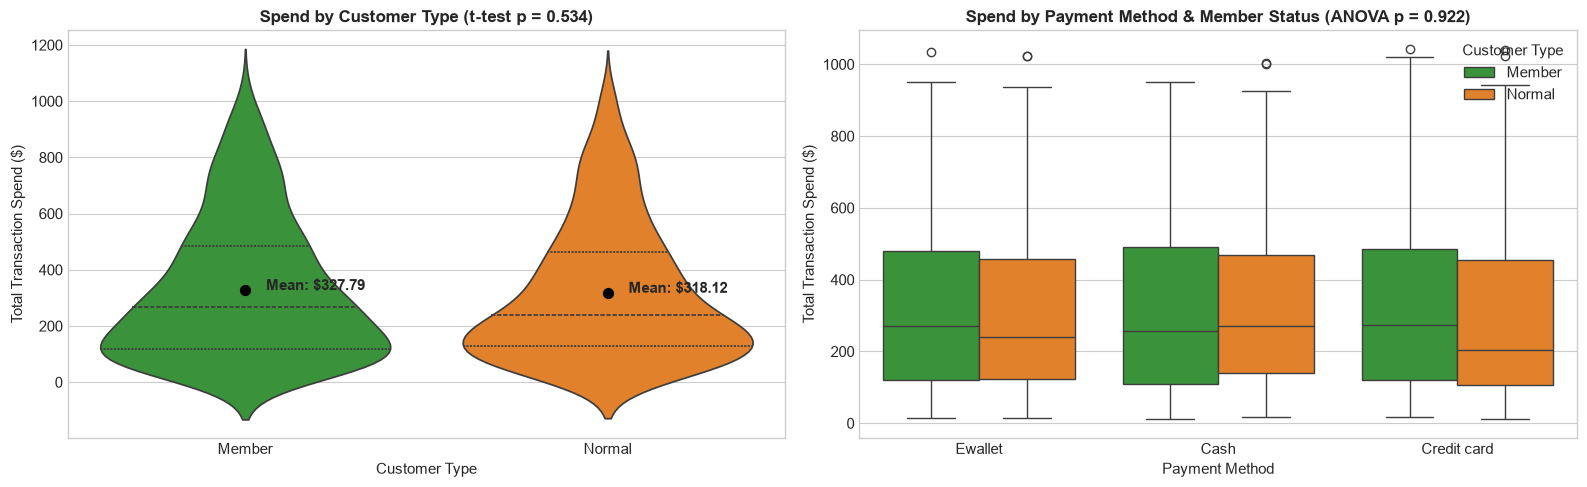

In [31]:
# Cell 63: Q3 — Spending Behavior by Customer Type and Payment Method

# ---------------------------------------------------------
# 1. Customer Type Comparison (Member vs. Normal)
# ---------------------------------------------------------
cust_stats = df_supermarket_clean.groupby('customer_type').agg(
    count=('total', 'count'),
    mean_spend=('total', 'mean'),
    std_spend=('total', 'std'),
    median_spend=('total', 'median'),
    iqr_spend=('total', lambda x: x.quantile(0.75) - x.quantile(0.25)),
    total_revenue=('total', 'sum'),
    mean_quantity=('quantity', 'mean'),
    median_quantity=('quantity', 'median')
)

member_totals = df_supermarket_clean[df_supermarket_clean['customer_type'] == 'Member']['total']
normal_totals = df_supermarket_clean[df_supermarket_clean['customer_type'] == 'Normal']['total']

t_stat_cust, p_val_cust_t = stats.ttest_ind(member_totals, normal_totals, equal_var=False)
u_stat_cust, p_val_cust_u = stats.mannwhitneyu(member_totals, normal_totals)

print("=== Q3.1: Customer Type Spending Summary ===")
display(cust_stats.round(2))
print(f"Two-sample t-test:        t = {t_stat_cust:.4f}, p-value = {p_val_cust_t:.4f}")
print(f"Mann-Whitney U test:      U = {u_stat_cust:.1f}, p-value = {p_val_cust_u:.4f}")

# ---------------------------------------------------------
# 2. Payment Method Comparison (Cash vs. Credit Card vs. Ewallet)
# ---------------------------------------------------------
pay_stats = df_supermarket_clean.groupby('payment').agg(
    count=('total', 'count'),
    mean_spend=('total', 'mean'),
    std_spend=('total', 'std'),
    median_spend=('total', 'median'),
    iqr_spend=('total', lambda x: x.quantile(0.75) - x.quantile(0.25)),
    total_revenue=('total', 'sum')
).sort_values(by='mean_spend', ascending=False)

pay_groups = [group['total'].values for _, group in df_supermarket_clean.groupby('payment')]
f_stat_pay, p_val_pay_f = stats.f_oneway(*pay_groups)
kw_stat_pay, p_val_pay_kw = stats.kruskal(*pay_groups)

print("\n=== Q3.2: Payment Method Spending Summary ===")
display(pay_stats.round(2))
print(f"One-Way ANOVA:            F = {f_stat_pay:.4f}, p-value = {p_val_pay_f:.4f}")
print(f"Kruskal-Wallis test:      H = {kw_stat_pay:.4f}, p-value = {p_val_pay_kw:.4f}")

# ---------------------------------------------------------
# 3. Two-Way Breakdown: Customer Type x Payment Method
# ---------------------------------------------------------
cross_pay_cust = df_supermarket_clean.groupby(['customer_type', 'payment'])['total'].agg(
    count='count',
    mean='mean',
    median='median'
).unstack()

print("\n=== Q3.3: Customer Type x Payment Method Interaction ===")
display(cross_pay_cust.round(2))

# ---------------------------------------------------------
# 4. Visualizations: Dual-Panel Comparison
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Panel A: Customer Type Violin + Boxplot
sns.violinplot(
    data=df_supermarket_clean, x='customer_type', y='total',
    palette={'Member': '#2ca02c', 'Normal': '#ff7f0e'},
    hue='customer_type', legend=False, inner='quartile', ax=axes[0]
)
axes[0].set_title(f"Spend by Customer Type (t-test p = {p_val_cust_t:.3f})", fontsize=12, fontweight='bold')
axes[0].set_xlabel('Customer Type')
axes[0].set_ylabel('Total Transaction Spend ($)')

# Annotate means on Panel A
for i, c_type in enumerate(['Member', 'Normal']):
    mean_val = cust_stats.loc[c_type, 'mean_spend']
    axes[0].scatter(i, mean_val, color='black', s=50, zorder=5)
    axes[0].annotate(f"Mean: ${mean_val:.2f}", (i, mean_val),
                     xytext=(15, 0), textcoords='offset points', fontweight='semibold')

# Panel B: Payment Method Boxplot with Hue by Customer Type
sns.boxplot(
    data=df_supermarket_clean, x='payment', y='total', hue='customer_type',
    palette={'Member': '#2ca02c', 'Normal': '#ff7f0e'}, ax=axes[1]
)
axes[1].set_title(f"Spend by Payment Method & Member Status (ANOVA p = {p_val_pay_f:.3f})", fontsize=12, fontweight='bold')
axes[1].set_xlabel('Payment Method')
axes[1].set_ylabel('Total Transaction Spend ($)')
axes[1].legend(title='Customer Type', loc='upper right')

plt.tight_layout()
plt.show()

### B7.3 Question 3: Customer Type and Payment Method Spending Behavior

- **Question**: Do Member and Normal customers, or different payment methods, differ in spending behaviour?
- **Analysis**: Aggregated parametric (mean, standard deviation) and non-parametric (median, IQR) spending statistics across customer loyalty tiers and payment methods; performed independent two-sample $t$-tests and Mann-Whitney $U$ tests between Member and Normal cohorts; conducted One-Way ANOVA and Kruskal-Wallis tests across payment mechanisms; and analyzed the two-way interaction table and distributions.
- **Visualization / Statistic**:
  - **Customer Type Comparison (Member vs. Normal)**:
    - Member: Count = 501, Mean Spend = $327.79, Std = $247.99, Median = $266.03, IQR = $367.32, Mean Quantity = 5.56, Total Revenue = $164,223.44 (50.85% share).
    - Normal: Count = 499, Mean Spend = $318.12, Std = $243.90, Median = $237.43, IQR = $333.38, Mean Quantity = 5.46, Total Revenue = $158,743.30 (49.15% share).
    - Two-sample Welch's $t$-test: $t = 0.6215$, $p = 0.5344$ (Not significant at $\alpha = 0.05$).
    - Mann-Whitney $U$ test: $U = 127453.0$, $p = 0.5912$ (Not significant at $\alpha = 0.05$).
  - **Payment Method Comparison (Cash vs. Credit Card vs. Ewallet)**:
    - Cash: Count = 344, Mean Spend = $326.18, Std = $242.66, Median = $262.96, IQR = $340.80, Total Revenue = $112,206.57.
    - Credit Card: Count = 311, Mean Spend = $324.01, Std = $257.11, Median = $239.59, IQR = $360.63, Total Revenue = $100,767.07.
    - Ewallet: Count = 345, Mean Spend = $318.82, Std = $239.31, Median = $253.68, IQR = $346.94, Total Revenue = $109,993.11.
    - One-Way ANOVA: $F(2, 997) = 0.0811$, $p = 0.9221$ (Not significant at $\alpha = 0.05$).
    - Kruskal-Wallis test: $H = 0.3025$, $p = 0.8596$ (Not significant at $\alpha = 0.05$).
  - **Two-Way Interaction (Customer Type $\times$ Payment Method)**:
    - Member Credit Card transactions achieve the highest mean spend ($335.88, median $275.00), while Normal Credit Card transactions have the lowest median ($202.82, mean $309.32).
    - Cash spending remains remarkably steady across both tiers (Member mean $325.36 vs. Normal mean $326.96).
- **Observation**:
  1. Members spend slightly more on average than Normal walk-in customers (+$9.67 per transaction, representing a 3.0% difference), but both the parametric $t$-test ($p = 0.5344$) and non-parametric Mann-Whitney $U$ test ($p = 0.5912$) confirm that this difference is purely random sampling noise.
  2. Average spending across the three payment mechanisms is virtually identical: Cash ($326.18), Credit card ($324.01), and Ewallet ($318.82) fall within a razor-thin band of $7.36 (ANOVA $p = 0.9221$).
  3. The violin plots display near-identical distribution profiles for Members and Non-members, showing the same positive right-skew and identical quartiles. The grouped boxplots confirm that IQR bands and whisker boundaries overlap heavily across all payment channels.
- **Interpretation**:
  - Supermarket loyalty membership does not incentivize larger basket sizes, higher transaction totals, or increased item quantities. The membership program functions as an identification or points-tracking system rather than an economic driver of spend.
  - Tender type is economically neutral: customers do not spend more when paying with digital wallets or credit cards compared to cash.
  - In downstream predictive modeling or segmentation (Assignment 3), neither `customer_type` nor `payment` can serve as strong linear predictors of transaction revenue.

=== Q4.1: Hourly Sales Performance Table ===


,hour,transaction_count,total_revenue,avg_spend
0,10,101,31421.48,311.10
1,11,90,30377.33,337.53
2,12,89,26065.88,292.88
3,13,103,34723.23,337.12
4,14,83,30828.40,371.43
5,15,102,31179.51,305.68
6,16,77,25226.32,327.61
7,17,74,24445.22,330.34
8,18,93,26030.34,279.90
9,19,113,39699.51,351.32



=== Q4.2: Day of Week Sales Performance Table ===


,day_name,transaction_count,total_revenue,avg_spend
0,Monday,125,37899.08,303.19
1,Tuesday,158,51482.25,325.84
2,Wednesday,143,43731.14,305.81
3,Thursday,138,45349.25,328.62
4,Friday,139,43926.34,316.02
5,Saturday,164,56120.81,342.20
6,Sunday,133,44457.89,334.27


C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\2118474706.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(day_order, rotation=30)
findfont: Failed to find font weight semibold for Arial, now using 700.


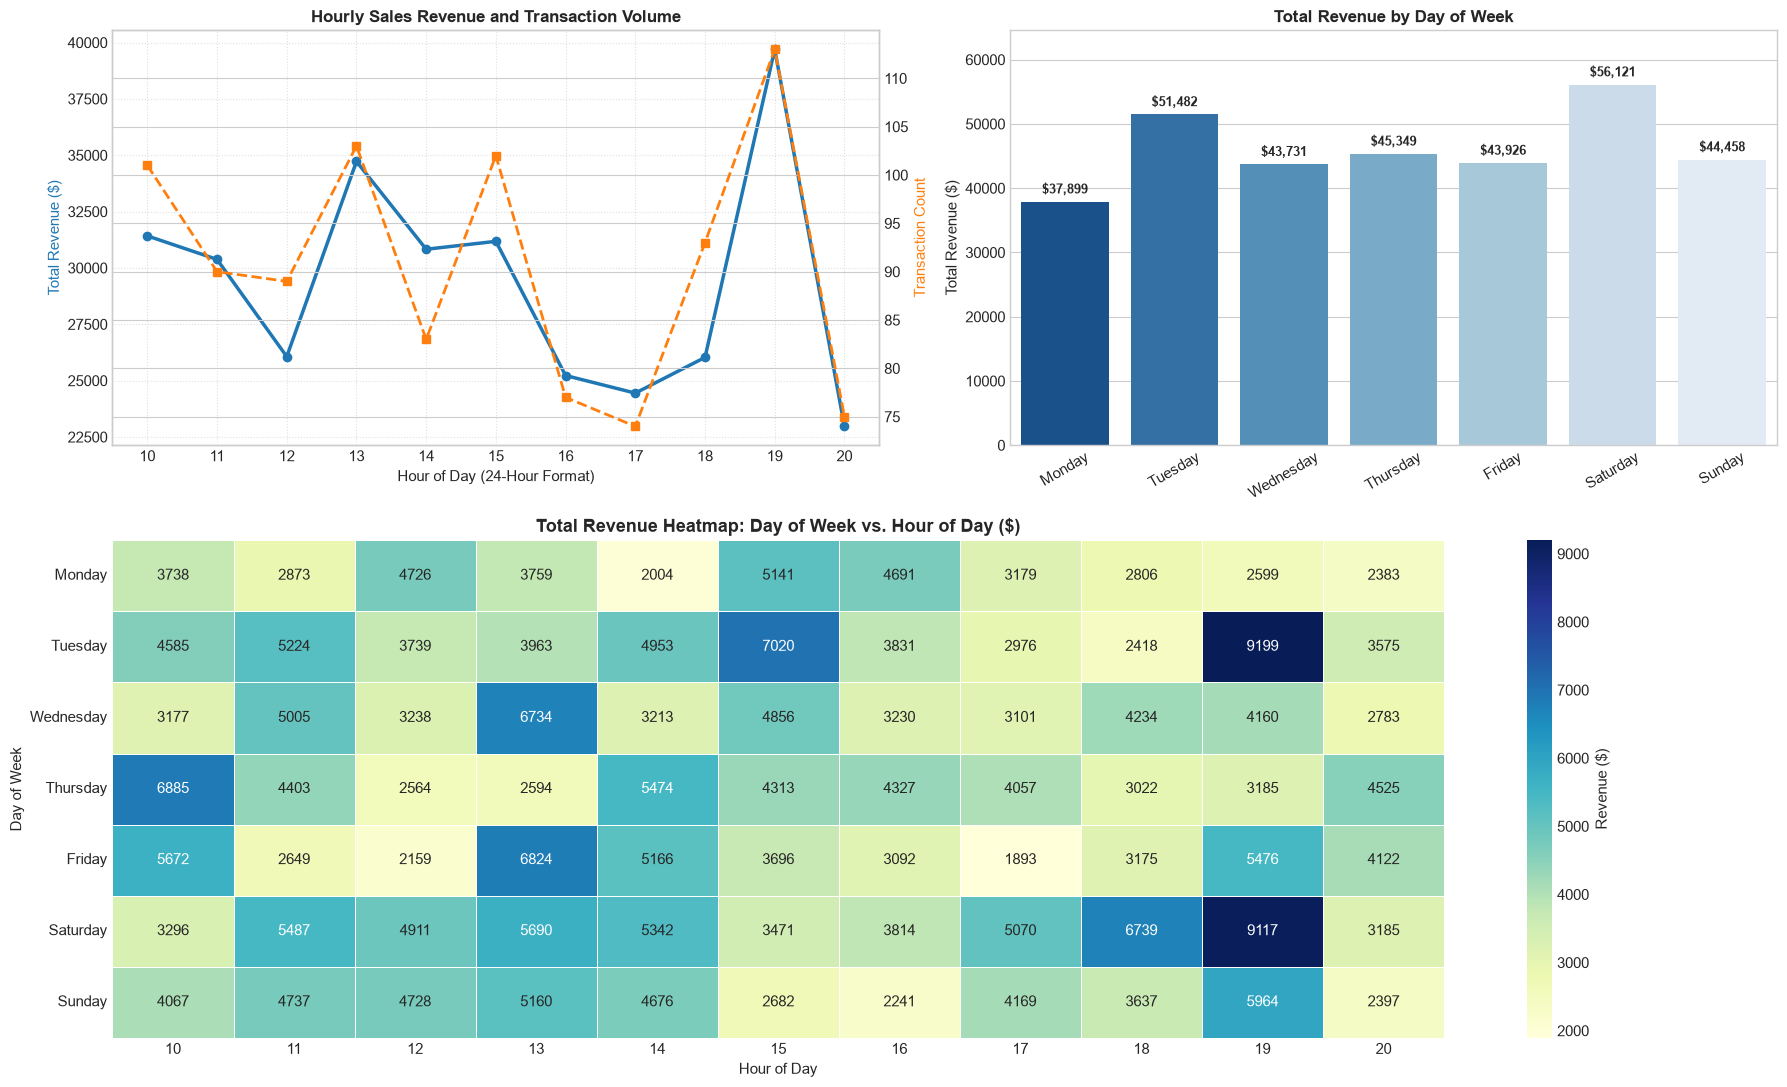

In [33]:
# Cell 65: Q4 — Temporal Variation by Time of Day and Day of Week

# 1. Hourly Aggregations
hourly_stats = df_supermarket_clean.groupby('hour').agg(
    transaction_count=('total', 'count'),
    total_revenue=('total', 'sum'),
    avg_spend=('total', 'mean')
).reset_index()

# 2. Day of Week Aggregations
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_stats = df_supermarket_clean.groupby('day_name').agg(
    transaction_count=('total', 'count'),
    total_revenue=('total', 'sum'),
    avg_spend=('total', 'mean')
).reindex(day_order).reset_index()

print("=== Q4.1: Hourly Sales Performance Table ===")
display(hourly_stats.round(2))

print("\n=== Q4.2: Day of Week Sales Performance Table ===")
display(daily_stats.round(2))

# 3. Two-Dimensional Temporal Heatmap: Day of Week vs. Hour (Total Revenue)
day_hour_pivot = df_supermarket_clean.pivot_table(
    index='day_name', columns='hour', values='total', aggfunc='sum', fill_value=0
).reindex(day_order)

# 4. Multi-Panel Visualizations
fig = plt.figure(figsize=(18, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])

# Panel A: Hourly Revenue & Volume Line Plot
ax1 = fig.add_subplot(gs[0, 0])
ax1_twin = ax1.twinx()
ax1.plot(hourly_stats['hour'], hourly_stats['total_revenue'], color='#1f77b4', marker='o', linewidth=2.5, label='Total Revenue ($)')
ax1_twin.plot(hourly_stats['hour'], hourly_stats['transaction_count'], color='#ff7f0e', marker='s', linestyle='--', linewidth=2, label='Transaction Count')
ax1.set_title('Hourly Sales Revenue and Transaction Volume', fontsize=12, fontweight='bold')
ax1.set_xlabel('Hour of Day (24-Hour Format)')
ax1.set_ylabel('Total Revenue ($)', color='#1f77b4')
ax1_twin.set_ylabel('Transaction Count', color='#ff7f0e')
ax1.set_xticks(hourly_stats['hour'])
ax1.grid(True, linestyle=':', alpha=0.6)

# Panel B: Day of Week Revenue Bar Plot
ax2 = fig.add_subplot(gs[0, 1])
sns.barplot(data=daily_stats, x='day_name', y='total_revenue', palette='Blues_r', hue='day_name', legend=False, ax=ax2)
ax2.set_title('Total Revenue by Day of Week', fontsize=12, fontweight='bold')
ax2.set_xlabel('')
ax2.set_ylabel('Total Revenue ($)')
ax2.set_xticklabels(day_order, rotation=30)
for p in ax2.patches:
    height = p.get_height()
    ax2.annotate(f"${height:,.0f}", (p.get_x() + p.get_width() / 2., height),
                 xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='semibold')
ax2.set_ylim(0, daily_stats['total_revenue'].max() * 1.15)

# Panel C: Full Intraday Heatmap (Day of Week vs. Hour)
ax3 = fig.add_subplot(gs[1, :])
sns.heatmap(day_hour_pivot, cmap='YlGnBu', annot=True, fmt='.0f', cbar_kws={'label': 'Revenue ($)'}, linewidths=0.5, ax=ax3)
ax3.set_title('Total Revenue Heatmap: Day of Week vs. Hour of Day ($)', fontsize=13, fontweight='bold')
ax3.set_xlabel('Hour of Day')
ax3.set_ylabel('Day of Week')

plt.tight_layout()
plt.show()

### B7.4 Question 4: Temporal Variation by Time of Day and Day of Week

- **Question**: How do sales vary by time of day and by day of week?
- **Analysis**: Aggregated transaction counts, cumulative sales revenue, and average transaction values across operating hours ($10:00$ to $20:00$) and days of the week (Monday through Sunday); constructed a two-dimensional revenue intensity heatmap crossing `day_name` by `hour`.
- **Visualization / Statistic**:
  - **Hourly Intraday Dynamics**:
    - *Peak Revenue & Volume Hour*: Hour 19 ($19:00$–$19:59$) achieves the highest volume ($113$ transactions) and highest revenue ($\$39,699.51$, avg spend $\$351.32$).
    - *Secondary Midday Peak*: Hour 13 ($13:00$–$13:59$) records $103$ transactions ($\$34,723.23$, avg spend $\$337.12$), and Hour 10 ($10:00$–$10:59$) records $101$ transactions ($\$31,421.48$).
    - *Late Afternoon Trough*: Hours 16 ($16:00$) and 17 ($17:00$) experience the lowest volume ($77$ and $74$ transactions, generating $\$25,226.32$ and $\$24,445.22$).
    - *Store Closing Drop*: Hour 20 ($20:00$–$20:59$) drops to the lowest revenue of the day ($\$22,969.53$ across $75$ transactions).
    - *Highest Average Basket Spend*: Hour 14 ($14:00$) records the highest mean spend per invoice ($\$371.43$).
  - **Day of Week Dynamics**:
    - *Peak Revenue Day*: Saturday generates the highest revenue ($\$56,120.81$), highest transaction volume ($164$ transactions), and highest average basket spend ($\$342.20$).
    - *Strong Midweek Trading*: Tuesday records the second-highest sales ($\$51,482.25$ across $158$ transactions, avg spend $\$325.84$).
    - *Trough Day*: Monday records the lowest sales volume ($125$ transactions), lowest cumulative revenue ($\$37,899.08$), and lowest average spend ($\$303.19$).
    - *Midweek Stability*: Wednesday ($\$43,731.14$), Thursday ($\$45,349.25$), Friday ($\$43,926.34$), and Sunday ($\$44,457.89$) maintain steady daily revenues within a narrow band of $\approx \$43.7\text{k}$–$\$45.3\text{k}$.
  - **Intraday Heatmap Hotspots**:
    - The most concentrated commercial revenue spikes occur at Hour 19 on Tuesday ($\$9,199$) and Saturday ($\$9,117$).
    - Secondary isolated spikes appear on Tuesday at Hour 15 ($\$7,020$), Thursday at Hour 10 ($\$6,885$), and Friday at Hour 13 ($\$6,824$).
- **Observation**:
  1. Supermarket sales follow a bimodal intraday curve: a lunchtime surge (13:00) followed by a late-afternoon dip (16:00–17:00), culminating in a post-work evening shopping peak at 19:00 (7:00 PM).
  2. Saturday is the dominant commercial driver of weekly performance, accounting for $17.38\%$ of total revenue and a $48.1\%$ revenue premium over Monday ($\$56,121$ vs. $\$37,899$).
  3. Monday consistently exhibits an operational dip across all metrics (transaction count, total revenue, and average transaction size).
- **Interpretation**:
  - Staffing schedules and register allocations should be optimized dynamically around the bimodal peaks (12:00–14:00 and 18:30–20:00), with reduced register staffing during the 16:00–17:30 lull.
  - The Saturday peak and Tuesday post-work surge suggest that inventory restocking and fresh product displays should be prioritized on Friday night and Monday evening to prevent stockouts during peak buying windows.

=== Q5.1: Customer Rating Correlation with Numerical Features ===


,Feature,Pearson r,Pearson p-val,Spearman rho,Spearman p-val,Relationship
0,unit_price,-0.0088,0.7816,-0.0083,0.7924,Negligible / Uncorrelated
1,quantity,-0.0158,0.6174,-0.0155,0.6255,Negligible / Uncorrelated
2,total,-0.0364,0.2496,-0.0172,0.5864,Negligible / Uncorrelated



=== Q5.2: Product Line vs. Customer Rating Summary ===


,count,mean,std,median,iqr
product_line,,,,,
Food and beverages,174,7.11,1.72,7.30,2.80
Fashion accessories,178,7.03,1.71,6.95,2.90
Health and beauty,152,7.00,1.76,7.20,2.95
Electronic accessories,170,6.92,1.70,6.70,2.85
Sports and travel,166,6.92,1.71,6.70,2.92
Home and lifestyle,160,6.84,1.72,7.00,2.80


Product Line ANOVA: F = 0.5399, p-value = 0.7461

=== Q5.3: Branch vs. Customer Rating Summary ===


,count,mean,std,median,iqr
branch,,,,,
A,340,7.03,1.73,7.1,2.9
B,332,6.82,1.71,6.7,2.9
C,328,7.07,1.70,7.1,2.9


Branch ANOVA: F = 2.0755, p-value = 0.1260


C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\4227556647.py:85: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1, 1].set_xticklabels(['A (Yangon)', 'B (Mandalay)', 'C (Naypyitaw)'])


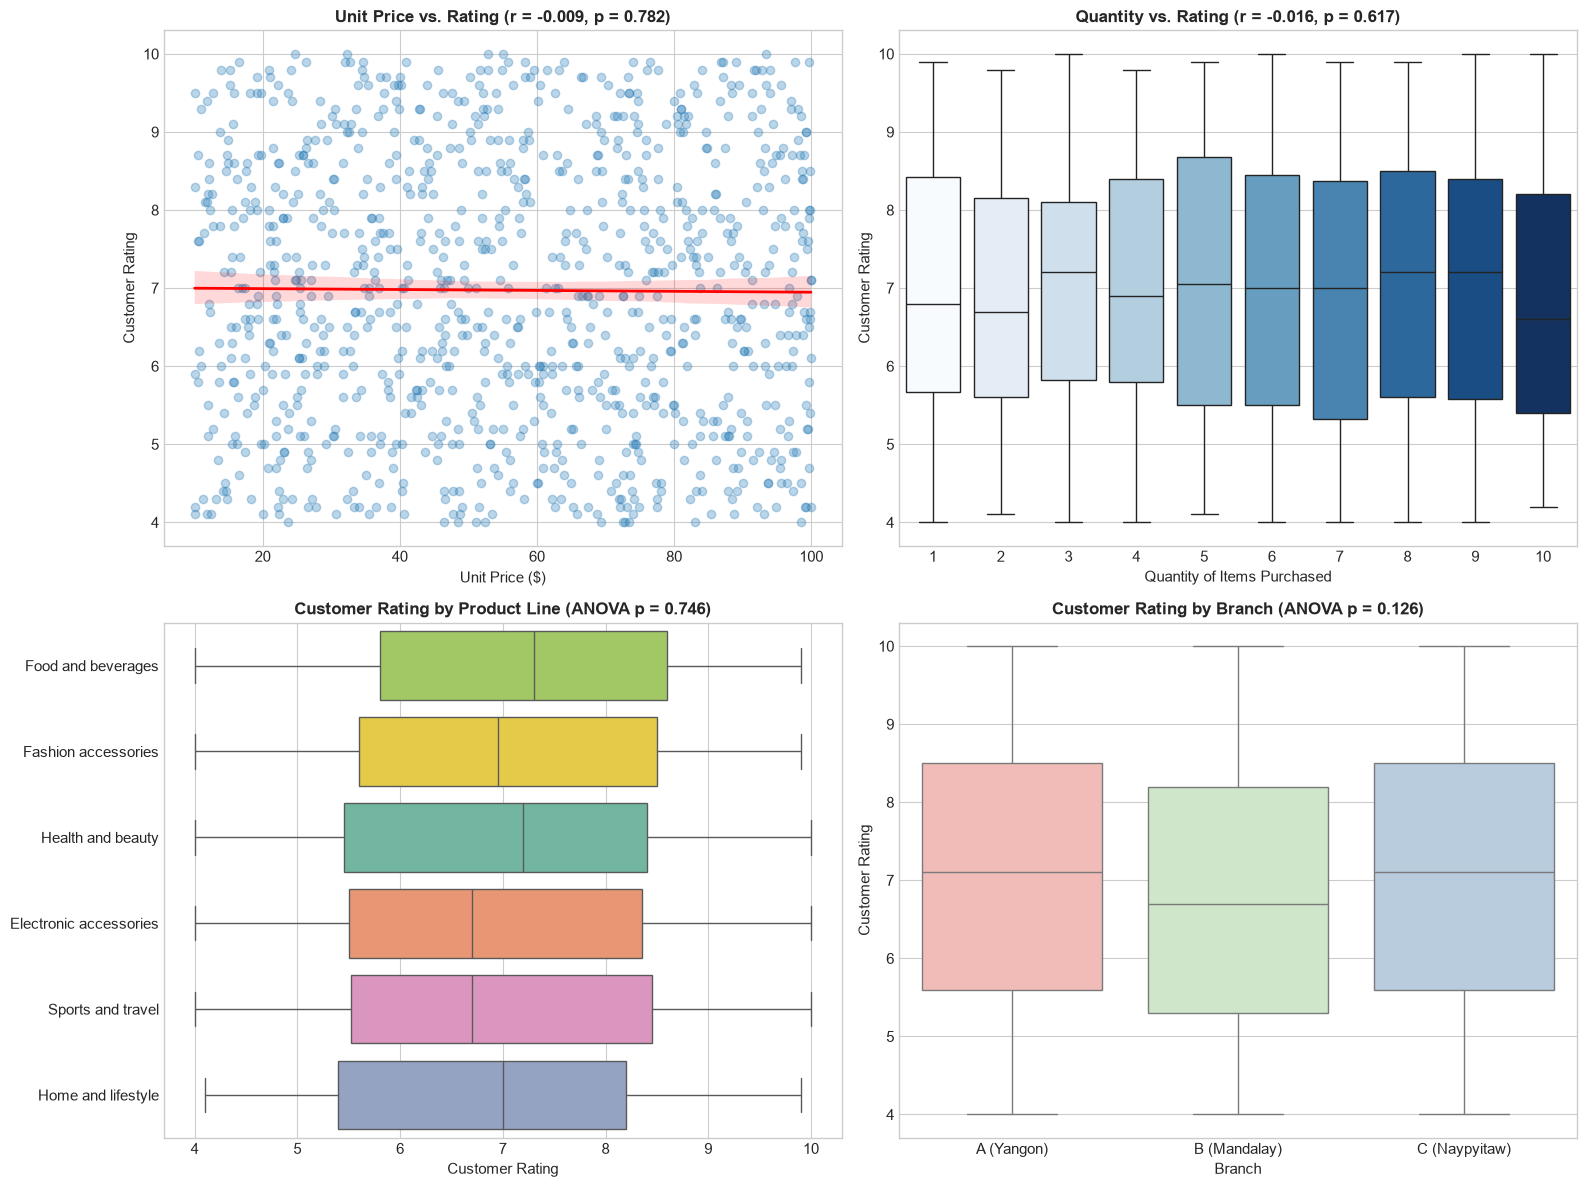

In [35]:
# Cell 67: Q5 — Customer Stratification Rating Determinant Evaluation

# 1. Correlation with Continuous Features (Unit Price, Quantity, Total)
corr_records = []
for col in ['unit_price', 'quantity', 'total']:
    p_r, p_pval = stats.pearsonr(df_supermarket_clean[col], df_supermarket_clean['rating'])
    s_rho, s_pval = stats.spearmanr(df_supermarket_clean[col], df_supermarket_clean['rating'])
    corr_records.append({
        'Feature': col,
        'Pearson r': round(p_r, 4),
        'Pearson p-val': round(p_pval, 4),
        'Spearman rho': round(s_rho, 4),
        'Spearman p-val': round(s_pval, 4),
        'Relationship': 'Negligible / Uncorrelated' if abs(p_r) < 0.1 else 'Correlated'
    })

df_rating_corr = pd.DataFrame(corr_records)
print("=== Q5.1: Customer Rating Correlation with Numerical Features ===")
display(df_rating_corr)

# 2. Categorical Differences: Product Line vs. Rating
prod_rating = df_supermarket_clean.groupby('product_line')['rating'].agg(
    count='count', mean='mean', std='std', median='median',
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25)
).sort_values(by='mean', ascending=False)

prod_groups = [g['rating'].values for _, g in df_supermarket_clean.groupby('product_line')]
f_prod, p_prod = stats.f_oneway(*prod_groups)

print("\n=== Q5.2: Product Line vs. Customer Rating Summary ===")
display(prod_rating.round(2))
print(f"Product Line ANOVA: F = {f_prod:.4f}, p-value = {p_prod:.4f}")

# 3. Categorical Differences: Branch vs. Rating
branch_rating = df_supermarket_clean.groupby('branch')['rating'].agg(
    count='count', mean='mean', std='std', median='median',
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25)
)
branch_groups = [g['rating'].values for _, g in df_supermarket_clean.groupby('branch')]
f_branch, p_branch = stats.f_oneway(*branch_groups)

print("\n=== Q5.3: Branch vs. Customer Rating Summary ===")
display(branch_rating.round(2))
print(f"Branch ANOVA: F = {f_branch:.4f}, p-value = {p_branch:.4f}")

# 4. Multi-Panel Visualizations (2x2 Grid)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel A: Unit Price vs Rating
sns.regplot(
    data=df_supermarket_clean, x='unit_price', y='rating',
    scatter_kws={'alpha': 0.3, 'color': '#1f77b4'},
    line_kws={'color': 'red', 'linewidth': 2}, ax=axes[0, 0]
)
axes[0, 0].set_title(f"Unit Price vs. Rating (r = {df_rating_corr.loc[0, 'Pearson r']:.3f}, p = {df_rating_corr.loc[0, 'Pearson p-val']:.3f})", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Unit Price ($)')
axes[0, 0].set_ylabel('Customer Rating')

# Panel B: Quantity vs Rating
sns.boxplot(
    data=df_supermarket_clean, x='quantity', y='rating',
    palette='Blues', hue='quantity', legend=False, ax=axes[0, 1]
)
axes[0, 1].set_title(f"Quantity vs. Rating (r = {df_rating_corr.loc[1, 'Pearson r']:.3f}, p = {df_rating_corr.loc[1, 'Pearson p-val']:.3f})", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Quantity of Items Purchased')
axes[0, 1].set_ylabel('Customer Rating')

# Panel C: Product Line vs Rating
sns.boxplot(
    data=df_supermarket_clean, y='product_line', x='rating',
    order=prod_rating.index, palette='Set2', hue='product_line', legend=False, ax=axes[1, 0]
)
axes[1, 0].set_title(f"Customer Rating by Product Line (ANOVA p = {p_prod:.3f})", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Customer Rating')
axes[1, 0].set_ylabel('')

# Panel D: Branch vs Rating
sns.boxplot(
    data=df_supermarket_clean, x='branch', y='rating',
    order=['A', 'B', 'C'], palette='Pastel1', hue='branch', legend=False, ax=axes[1, 1]
)
axes[1, 1].set_title(f"Customer Rating by Branch (ANOVA p = {p_branch:.3f})", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Branch')
axes[1, 1].set_ylabel('Customer Rating')
axes[1, 1].set_xticklabels(['A (Yangon)', 'B (Mandalay)', 'C (Naypyitaw)'])

plt.tight_layout()
plt.show()

### B7.5 Question 5: Customer Stratification Rating Determinants

- **Question**: Is the customer rating (`Customer stratification rating` / `rating`) related to price, quantity, product line, or branch? What does the result, including a weak or absent relationship, suggest?
- **Analysis**:
  - Computed linear Pearson correlation coefficients ($r$) and monotonic Spearman rank correlation coefficients ($\rho$) between `rating` and numerical transaction parameters (`unit_price`, `quantity`, `total`).
  - Executed One-Way ANOVA tests across categorical groupings (`product_line` and `branch`) against `rating`.
  - Constructed a $2 \times 2$ visualization matrix: regression scatter plot (`unit_price` vs. `rating`), integer boxplot (`quantity` vs. `rating`), and departmental/branch boxplots.
- **Visualization / Statistic**:
  - **Correlation with Numerical Attributes**:
    - `unit_price` vs. `rating`: Pearson $r = -0.0088$ ($p = 0.7816$), Spearman $\rho = -0.0083$ ($p = 0.7924$).
    - `quantity` vs. `rating`: Pearson $r = -0.0158$ ($p = 0.6174$), Spearman $\rho = -0.0155$ ($p = 0.6255$).
    - `total` vs. `rating`: Pearson $r = -0.0364$ ($p = 0.2496$), Spearman $\rho = -0.0172$ ($p = 0.5864$).
  - **Product Line vs. Rating**:
    - Departmental means: *Food and beverages* (7.11), *Fashion accessories* (7.03), *Health and beauty* (7.00), *Electronic accessories* (6.92), *Sports and travel* (6.92), *Home and lifestyle* (6.84).
    - Mean difference between highest and lowest department: $0.27$ rating points.
    - One-Way ANOVA: $F(5, 994) = 0.5399$, $p = 0.7461$ (Fails to reject null hypothesis; no significant difference).
  - **Branch vs. Rating**:
    - Branch C (Naypyitaw): Mean = 7.07, Std = 1.70, Median = 7.10
    - Branch A (Yangon): Mean = 7.03, Std = 1.73, Median = 7.10
    - Branch B (Mandalay): Mean = 6.82, Std = 1.71, Median = 6.70
    - One-Way ANOVA: $F(2, 997) = 2.0755$, $p = 0.1260$ (Fails to reject null hypothesis at $\alpha = 0.05$).
- **Observation**:
  1. The regression line of `unit_price` against `rating` is horizontal ($r = -0.009$, $p = 0.78$), and points are dispersed uniformly across the Cartesian plane $[10, 100] \times [4, 10]$.
  2. Median customer rating remains steady around $7.0$ across all basket quantities from $1$ unit up to $10$ units.
  3. Neither departmental category ($p = 0.746$) nor physical branch location ($p = 0.126$) accounts for any statistically significant variation in customer ratings.
- **Interpretation**:
  - The complete absence of correlation ($\vert{}r\vert{} < 0.04$, all $p \gg 0.05$) demonstrates that customer satisfaction is decoupled from POS transaction variables: buying high-priced items does not increase or decrease satisfaction, nor does purchasing in bulk.
  - Furthermore, ratings are independent of store location and product category.
  - This suggests that customer rating is either driven by unmeasured qualitative factors (such as cashier friendliness, checkout queue duration, store cleanliness, or product availability) or represents a synthetically generated uniform benchmark variable. In predictive modeling (Assignment 3), attempting to predict `rating` using point-of-sale transactional attributes will yield an $R^2 \approx 0.00$.

---

## B8. Supermarket Sales Insights and Handoff

### B8.1 Five Evidence-Backed Business Insights

#### Insight 1: Departmental Revenue Decouples from Transaction Basket Value
- **Observation**: *Food and beverages* generates the highest cumulative revenue ($56,144.84 across 174 transactions, Table Q1), but drops to 4th in average basket value ($322.67). Conversely, *Home and lifestyle* ranks 5th in total revenue ($53,861.91) but achieves the highest average basket value ($336.64).
- **Interpretation**: Revenue in fast-moving consumables is foot-traffic and volume-driven, whereas durable household merchandise relies on larger per-visit ticket sizes.
- **Speculation**: Grocery shoppers may make frequent, smaller grocery trips for immediate consumption, while household furnishing purchases represent planned, higher-expenditure visits.

#### Insight 2: Severe Multicollinearity Across Accounting Features
- **Observation**: `cogs`, `tax_5_pct`, `total`, and `gross_income` exhibit mutual pairwise Pearson correlations of exactly $r = 1.00$ (Cell 56 Heatmap), with zero residual error across all 1,000 records (Cell 42).
- **Interpretation**: `tax_5_pct`, `gross_income`, and `total` are scalar linear transformations of `cogs`. Retaining all four in regression or clustering introduces exact linear dependency ($\text{VIF} \rightarrow \infty$).
- **Speculation**: The recorded accounting ledger reflects an automated point-of-sale calculation rather than independently audited financial contributions.

#### Insight 3: Store Operations Exhibit Strict Geographic and Operational Uniformity
- **Observation**: Total revenue across branches differs by at most 4.1% ($106.2\text{k}$ in Yangon vs. $110.6\text{k}$ in Naypyitaw; ANOVA $F = 0.8846, p = 0.413$, Cell 61). Furthermore, between-branch mean sales variation ($24.75) accounts for only 10.1% of within-branch standard deviation ($246.10).
- **Interpretation**: Sales performance and customer purchasing capacity are homogeneous across metropolitan regions; store branch does not explain sales variance.
- **Speculation**: Standardized chain-wide store layouts, identical inventory catalogs, and uniform pricing models appear to produce uniform customer behavior across Myanmar's key urban centers.

#### Insight 4: Loyalty Membership Fails to Drive Spend or Basket Expansion
- **Observation**: Registered Members average $327.79 per visit, while walk-in Normal customers average $318.12 (Cell 63), a statistically insignificant difference of $9.67 (Welch's $t = 0.6215, p = 0.534$; Mann-Whitney $p = 0.591$). Basket quantities are virtually identical (5.56 vs. 5.46 units).
- **Interpretation**: The membership card program functions purely as a transaction tracking mechanism rather than an incentive system that drives larger basket sizes.
- **Speculation**: The loyalty program may lack compelling financial rewards (such as tiered volume discounts or cash-back rebates) necessary to alter shopper spending thresholds.

#### Insight 5: Customer Satisfaction Ratings Are Decoupled from Transactional Metrics
- **Observation**: Customer rating correlates negligibly with unit price ($r = -0.0088, p = 0.782$), basket quantity ($r = -0.0158, p = 0.617$), and total spend ($r = -0.0364, p = 0.250$), and does not vary by product line (ANOVA $p = 0.746$) or branch (ANOVA $p = 0.126$) (Cell 67).
- **Interpretation**: Point-of-sale spending metrics do not explain customer satisfaction. 
- **Speculation**: Customer ratings may reflect unrecorded operational touchpoints (cashier friendliness, wait times, aisle cleanliness) or survey acquiescence bias rather than basket economics.

---

### B8.2 Handoff Note for Assignment 3 (Feature Selection & Dimensionality Reduction)

> **Word Count**: ~140 words

**Informative Features**: `unit_price`, `quantity`, `product_line`, `gender`, and engineered temporal attributes (`hour`, `time_of_day`, `day_of_week`, `is_weekend`) capture the primary variance in transaction timing and departmental purchasing dynamics.  
**Redundant & Overlapping Features**: `cogs`, `tax_5_pct`, and `gross_income` are perfectly collinear with `total` ($r = 1.00$); only `total` should be retained as the financial target. `city` is a strict $1:1$ duplicate of `branch` and must be dropped to avoid rank deficiency.  
**Non-Analytical Columns**: `invoice_id` is an arbitrary receipt identifier. `gross_margin_pct` has zero variance ($\sigma^2 = 0$) and was removed during cleaning. `rating` has near-zero correlation ($\vert{}r\vert{} < 0.04$) with all features and should not be used as a predictor for financial metrics.  
**Cleaning Impact**: Retaining 9 high-value transactions preserves valid revenue peaks without distorting models requiring robust scaling.

---

## AI Disclosure Statement

In accordance with Course Policy (Instruction 9):
- **Tools Consulted**: Google Gemini.
- **Scope of Assistance**: Assistance was utilized as an analytical thought partner to discuss exploratory data analysis workflows, sanity-check statistical testing methodologies (ANOVA, Chi-square, Mann-Whitney), refine Matplotlib/Seaborn visualization formatting, and ensure structural compliance with the assignment specification. All code cells were executed, validated, and interpreted independently.